In [2]:
# ================================================================
# CELL 01 — ENVIRONNEMENT GPU T4 ×2 + CONFIGURATION BREAKHIS
# ================================================================

import os
import sys
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras

warnings.filterwarnings("ignore")


# ================================================================
# 1. INFORMATIONS ENVIRONNEMENT
# ================================================================

print("=" * 75)
print("ENVIRONNEMENT D'ENTRAÎNEMENT")
print("=" * 75)

print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {keras.__version__}")
print(f"Python     : {sys.version.split()[0]}")


# ================================================================
# 2. SEED
# ================================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Seed       : {SEED}")


# ================================================================
# 3. DÉTECTION DES GPU
# ================================================================

print("\n" + "=" * 75)
print("INITIALISATION GPU")
print("=" * 75)

GPUS = tf.config.list_physical_devices("GPU")

if len(GPUS) == 0:

    print("❌ Aucun GPU détecté")
    print("⚠️ Vérifie : Settings → Accelerator → GPU T4 ×2")

    strategy = tf.distribute.get_strategy()

    DEVICE_TYPE = "CPU"
    NUM_REPLICAS = 1

else:

    print(f"✅ {len(GPUS)} GPU détecté(s)")

    for i, gpu in enumerate(GPUS):

        print(f"GPU {i} : {gpu}")

        try:
            tf.config.experimental.set_memory_growth(
                gpu,
                True
            )
        except Exception:
            pass

    # ============================================================
    # MirroredStrategy
    # ============================================================

    strategy = tf.distribute.MirroredStrategy()

    DEVICE_TYPE = "GPU"
    NUM_REPLICAS = strategy.num_replicas_in_sync

    print("\n✅ MirroredStrategy activée")
    print(f"Nombre de réplicas : {NUM_REPLICAS}")


# ================================================================
# 4. VÉRIFICATION DES GPU
# ================================================================

print("\n" + "=" * 75)
print("PÉRIPHÉRIQUES DISPONIBLES")
print("=" * 75)

for device in tf.config.list_physical_devices():

    print(" -", device)


# ================================================================
# 5. CONFIGURATION DU PROJET
# ================================================================

PROJECT_NAME = "BreakHis_Histopathology"

IMAGE_SIZE = (224, 224)

IMG_HEIGHT = 224
IMG_WIDTH = 224

NUM_CLASSES = 2

CLASS_NAMES = [
    "benign",
    "malignant"
]


# ================================================================
# 6. BATCH SIZE
# ================================================================

# Batch global distribué entre les 2 GPU
GLOBAL_BATCH_SIZE = 64

if GLOBAL_BATCH_SIZE % NUM_REPLICAS != 0:

    raise ValueError(
        f"GLOBAL_BATCH_SIZE={GLOBAL_BATCH_SIZE} "
        f"doit être divisible par "
        f"NUM_REPLICAS={NUM_REPLICAS}"
    )

BATCH_SIZE_PER_REPLICA = (
    GLOBAL_BATCH_SIZE // NUM_REPLICAS
)


# ================================================================
# 7. CHEMIN BREAKHIS
# ================================================================

BREAKHIS_ROOT = Path(
    "/kaggle/input/datasets/ambarish/breakhis"
)


# ================================================================
# 8. VÉRIFICATION DATASET
# ================================================================

print("\n" + "=" * 75)
print("VÉRIFICATION DU DATASET BREAKHIS")
print("=" * 75)

print("Chemin :")
print(BREAKHIS_ROOT)


if not BREAKHIS_ROOT.exists():

    raise FileNotFoundError(
        "\n❌ Dataset BreakHis introuvable.\n"
        f"Chemin : {BREAKHIS_ROOT}"
    )


print("✅ Dataset BreakHis trouvé")


# ================================================================
# 9. DÉTECTION DU DOSSIER BreaKHis_v1
# ================================================================

possible_roots = [

    BREAKHIS_ROOT / "BreaKHis_v1",

    BREAKHIS_ROOT / "BreakHis_v1",

    BREAKHIS_ROOT / "BreaKHis",

    BREAKHIS_ROOT
]


BREAKHIS_DATA_ROOT = None

for path in possible_roots:

    if path.exists() and path.is_dir():

        try:

            contents = list(path.iterdir())

            if len(contents) > 0:

                BREAKHIS_DATA_ROOT = path

                break

        except Exception:
            pass


if BREAKHIS_DATA_ROOT is None:

    raise FileNotFoundError(
        "❌ Structure BreaKHis_v1 introuvable."
    )


print("\nDossier principal :")
print(BREAKHIS_DATA_ROOT)


# ================================================================
# 10. DÉTECTION FOLDS.CSV
# ================================================================

FOLDS_CSV = BREAKHIS_ROOT / "Folds.csv"


if not FOLDS_CSV.exists():

    candidates = list(
        BREAKHIS_ROOT.rglob("Folds.csv")
    )

    if len(candidates) > 0:

        FOLDS_CSV = candidates[0]


if FOLDS_CSV.exists():

    print("\n✅ Folds.csv trouvé :")
    print(FOLDS_CSV)

else:

    print("\n⚠️ Folds.csv introuvable")


# ================================================================
# 11. STRUCTURE DU DATASET
# ================================================================

print("\n" + "=" * 75)
print("STRUCTURE PRINCIPALE DU DATASET")
print("=" * 75)


def show_structure(path, max_depth=3, depth=0):

    if depth > max_depth:
        return

    try:

        items = sorted(
            path.iterdir(),
            key=lambda x: (not x.is_dir(), x.name.lower())
        )

    except Exception:

        return

    for item in items:

        indent = "    " * depth

        if item.is_dir():

            print(
                f"{indent}📁 {item.name}/"
            )

            show_structure(
                item,
                max_depth=max_depth,
                depth=depth + 1
            )

        else:

            print(
                f"{indent}📄 {item.name}"
            )


show_structure(
    BREAKHIS_ROOT,
    max_depth=3
)


# ================================================================
# 12. CONFIGURATION FINALE
# ================================================================

print("\n" + "=" * 75)
print("CONFIGURATION FINALE")
print("=" * 75)

print(f"Projet              : {PROJECT_NAME}")

print(f"Hardware            : {DEVICE_TYPE}")

print(f"Nombre de GPU       : {len(GPUS)}")

print(f"Nombre de réplicas  : {NUM_REPLICAS}")

print(f"Image size          : {IMAGE_SIZE}")

print(f"Nombre de classes   : {NUM_CLASSES}")

print(f"Classes             : {CLASS_NAMES}")

print(f"Global batch size   : {GLOBAL_BATCH_SIZE}")

print(
    f"Batch / GPU         : "
    f"{BATCH_SIZE_PER_REPLICA}"
)

print(
    f"Dataset             : "
    f"{BREAKHIS_ROOT}"
)

print(
    f"BreaKHis_v1         : "
    f"{BREAKHIS_DATA_ROOT}"
)

print(
    f"Folds.csv           : "
    f"{FOLDS_CSV}"
)


# ================================================================
# 13. VARIABLES DISPONIBLES POUR LES PROCHAINES CELLULES
# ================================================================

print("\n" + "=" * 75)
print("VARIABLES PRÊTES")
print("=" * 75)

variables = [
    "strategy",
    "DEVICE_TYPE",
    "NUM_REPLICAS",
    "PROJECT_NAME",
    "IMAGE_SIZE",
    "NUM_CLASSES",
    "CLASS_NAMES",
    "GLOBAL_BATCH_SIZE",
    "BATCH_SIZE_PER_REPLICA",
    "BREAKHIS_ROOT",
    "BREAKHIS_DATA_ROOT",
    "FOLDS_CSV"
]

for variable in variables:

    print(f"✓ {variable}")


print("\n" + "=" * 75)
print("✅ CELL 01 TERMINÉE")
print("=" * 75)

ENVIRONNEMENT D'ENTRAÎNEMENT
TensorFlow : 2.20.0
Keras      : 3.13.2
Python     : 3.12.13
Seed       : 42

INITIALISATION GPU
✅ 2 GPU détecté(s)
GPU 0 : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
GPU 1 : PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')

✅ MirroredStrategy activée
Nombre de réplicas : 2

PÉRIPHÉRIQUES DISPONIBLES
 - PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
 - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
 - PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

VÉRIFICATION DU DATASET BREAKHIS
Chemin :
/kaggle/input/datasets/ambarish/breakhis
✅ Dataset BreakHis trouvé

Dossier principal :
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1

✅ Folds.csv trouvé :
/kaggle/input/datasets/ambarish/breakhis/Folds.csv

STRUCTURE PRINCIPALE

In [3]:
# ================================================================
# CELL 02 — ANALYSE ET PRÉPARATION DU DATASET BREAKHIS
# ================================================================

import os
import re
from pathlib import Path

import pandas as pd
import numpy as np


print("=" * 75)
print("ANALYSE DU DATASET BREAKHIS")
print("=" * 75)


# ================================================================
# 1. LECTURE DE Folds.csv
# ================================================================

print("\n" + "=" * 75)
print("LECTURE DE Folds.csv")
print("=" * 75)

if not FOLDS_CSV.exists():

    raise FileNotFoundError(
        f"❌ Fichier Folds.csv introuvable : {FOLDS_CSV}"
    )


df_folds = pd.read_csv(FOLDS_CSV)

print("✅ Folds.csv chargé")

print(f"\nNombre de lignes : {len(df_folds):,}")

print("\nColonnes disponibles :")

for i, column in enumerate(df_folds.columns):

    print(f"{i:02d} - {column}")


# ================================================================
# 2. APERÇU DES DONNÉES
# ================================================================

print("\n" + "=" * 75)
print("APERÇU DES DONNÉES")
print("=" * 75)

display(df_folds.head())


# ================================================================
# 3. INFORMATIONS DU DATAFRAME
# ================================================================

print("\n" + "=" * 75)
print("INFORMATIONS DU DATAFRAME")
print("=" * 75)

print(df_folds.info())


# ================================================================
# 4. RECHERCHE DES COLONNES IMPORTANTES
# ================================================================

columns_lower = {
    col.lower(): col
    for col in df_folds.columns
}


def find_column(possible_names):

    for name in possible_names:

        if name.lower() in columns_lower:

            return columns_lower[name.lower()]

    return None


PATH_COLUMN = find_column([
    "filename",
    "file",
    "path",
    "filepath",
    "image",
    "image_path"
])


LABEL_COLUMN = find_column([
    "label",
    "class",
    "classification",
    "target"
])


PATIENT_COLUMN = find_column([
    "patient_id",
    "patient",
    "patientid"
])


FOLD_COLUMN = find_column([
    "fold",
    "split",
    "set"
])


print("\n" + "=" * 75)
print("COLONNES DÉTECTÉES")
print("=" * 75)

print("Path    :", PATH_COLUMN)
print("Label   :", LABEL_COLUMN)
print("Patient :", PATIENT_COLUMN)
print("Fold    :", FOLD_COLUMN)


# ================================================================
# 5. RECHERCHE AUTOMATIQUE DES IMAGES
# ================================================================

print("\n" + "=" * 75)
print("RECHERCHE DES IMAGES")
print("=" * 75)

print("Recherche dans :")
print(BREAKHIS_DATA_ROOT)


IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".tif",
    ".tiff",
    ".bmp"
}


image_files = []

for extension in IMAGE_EXTENSIONS:

    image_files.extend(
        BREAKHIS_DATA_ROOT.rglob(f"*{extension}")
    )


# Suppression des doublons
image_files = sorted(
    set(image_files)
)


print(
    f"\n✅ Images trouvées : "
    f"{len(image_files):,}"
)


# ================================================================
# 6. CONSTRUCTION D'UN INDEX DES IMAGES
# ================================================================

print("\nConstruction de l'index...")


image_records = []


for image_path in image_files:

    path_str = str(image_path)

    path_lower = path_str.lower()


    # ------------------------------------------------------------
    # Label
    # ------------------------------------------------------------

    if "/benign/" in path_lower:

        label = "benign"

    elif "/malignant/" in path_lower:

        label = "malignant"

    else:

        label = None


    # ------------------------------------------------------------
    # Sous-type
    # ------------------------------------------------------------

    subtype = None

    if label is not None:

        parts = image_path.parts

        try:

            label_index = [
                p.lower()
                for p in parts
            ].index(label)

            if label_index + 1 < len(parts):

                subtype = parts[label_index + 1]

        except ValueError:

            pass


    # ------------------------------------------------------------
    # Grossissement
    # ------------------------------------------------------------

    magnification = None

    match = re.search(
        r"-(40|100|200|400)-",
        image_path.name
    )

    if match:

        magnification = f"{match.group(1)}X"


    # ------------------------------------------------------------
    # Patient
    # ------------------------------------------------------------

    patient_id = None

    # Format courant :
    # SOB_B_A-14-22549AB-40-001.png

    match = re.search(
        r"([A-Z]{2,5}_[A-Z]_?[A-Z]?)-(\d+)-",
        image_path.name
    )

    if match:

        patient_id = (
            match.group(1)
            + "-"
            + match.group(2)
        )


    image_records.append({

        "image_path": path_str,

        "filename": image_path.name,

        "label": label,

        "subtype": subtype,

        "magnification": magnification,

        "patient_id": patient_id

    })


df_images = pd.DataFrame(
    image_records
)


# ================================================================
# 7. SUPPRESSION DES IMAGES SANS LABEL
# ================================================================

before = len(df_images)

df_images = df_images[
    df_images["label"].notna()
].copy()

after = len(df_images)


print(
    f"\nImages avec label : "
    f"{after:,}"
)

print(
    f"Images ignorées   : "
    f"{before - after:,}"
)


# ================================================================
# 8. DISTRIBUTION BENIGN / MALIGNANT
# ================================================================

print("\n" + "=" * 75)
print("DISTRIBUTION DES CLASSES")
print("=" * 75)

class_distribution = (
    df_images["label"]
    .value_counts()
    .to_frame("count")
)

class_distribution["percentage"] = (
    class_distribution["count"]
    / len(df_images)
    * 100
)

display(class_distribution)


# ================================================================
# 9. SOUS-TYPES HISTOLOGIQUES
# ================================================================

print("\n" + "=" * 75)
print("SOUS-TYPES HISTOLOGIQUES")
print("=" * 75)

subtype_distribution = (
    df_images["subtype"]
    .value_counts(dropna=False)
    .to_frame("count")
)

subtype_distribution["percentage"] = (
    subtype_distribution["count"]
    / len(df_images)
    * 100
)

display(subtype_distribution)


# ================================================================
# 10. DISTRIBUTION DES GROSSISSEMENTS
# ================================================================

print("\n" + "=" * 75)
print("GROSSISSEMENTS")
print("=" * 75)

magnification_distribution = (
    df_images["magnification"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("count")
)

magnification_distribution["percentage"] = (
    magnification_distribution["count"]
    / len(df_images)
    * 100
)

display(magnification_distribution)


# ================================================================
# 11. PATIENTS
# ================================================================

print("\n" + "=" * 75)
print("ANALYSE DES PATIENTS")
print("=" * 75)

known_patients = (
    df_images["patient_id"]
    .dropna()
    .nunique()
)

print(
    f"Patients détectés : "
    f"{known_patients:,}"
)


if known_patients > 0:

    images_per_patient = (
        df_images
        .groupby("patient_id")
        .size()
    )

    print(
        f"Images/patient — moyenne : "
        f"{images_per_patient.mean():.2f}"
    )

    print(
        f"Images/patient — médiane : "
        f"{images_per_patient.median():.2f}"
    )

    print(
        f"Images/patient — minimum : "
        f"{images_per_patient.min()}"
    )

    print(
        f"Images/patient — maximum : "
        f"{images_per_patient.max()}"
    )


# ================================================================
# 12. VÉRIFICATION DES FICHIERS
# ================================================================

print("\n" + "=" * 75)
print("VÉRIFICATION DES FICHIERS")
print("=" * 75)

missing_files = []

for path in df_images["image_path"]:

    if not Path(path).exists():

        missing_files.append(path)


print(
    f"Fichiers manquants : "
    f"{len(missing_files):,}"
)


if len(missing_files) > 0:

    print("\nExemples :")

    for path in missing_files[:10]:

        print(" -", path)

else:

    print("✅ Tous les fichiers indexés existent")


# ================================================================
# 13. DOUBLONS
# ================================================================

print("\n" + "=" * 75)
print("RECHERCHE DES DOUBLONS")
print("=" * 75)

duplicate_paths = (
    df_images["image_path"]
    .duplicated()
    .sum()
)

duplicate_filenames = (
    df_images["filename"]
    .duplicated()
    .sum()
)

print(
    f"Chemins dupliqués    : "
    f"{duplicate_paths:,}"
)

print(
    f"Noms de fichiers dup.: "
    f"{duplicate_filenames:,}"
)


# ================================================================
# 14. RÉPARTITION PAR CLASSE ET GROSSISSEMENT
# ================================================================

print("\n" + "=" * 75)
print("CLASSE × GROSSISSEMENT")
print("=" * 75)

class_magnification = pd.crosstab(
    df_images["label"],
    df_images["magnification"]
)

display(class_magnification)


# ================================================================
# 15. RÉPARTITION PAR SOUS-TYPE
# ================================================================

print("\n" + "=" * 75)
print("CLASSE × SOUS-TYPE")
print("=" * 75)

class_subtype = pd.crosstab(
    df_images["label"],
    df_images["subtype"]
)

display(class_subtype)


# ================================================================
# 16. SAUVEGARDE DE L'INDEX
# ================================================================

INDEX_OUTPUT = (
    "/kaggle/working/breakhis_image_index.csv"
)

df_images.to_csv(
    INDEX_OUTPUT,
    index=False
)

print("\n" + "=" * 75)
print("INDEX SAUVEGARDÉ")
print("=" * 75)

print(INDEX_OUTPUT)


# ================================================================
# 17. RÉSUMÉ FINAL
# ================================================================

print("\n" + "=" * 75)
print("RÉSUMÉ BREAKHIS")
print("=" * 75)

print(
    f"Images totales       : "
    f"{len(df_images):,}"
)

print(
    f"Classes              : "
    f"{df_images['label'].nunique()}"
)

print(
    f"Patients connus      : "
    f"{known_patients:,}"
)

print(
    f"Sous-types           : "
    f"{df_images['subtype'].nunique()}"
)

print(
    f"Grossissements       : "
    f"{df_images['magnification'].nunique()}"
)

print(
    f"Fichiers manquants   : "
    f"{len(missing_files):,}"
)

print(
    f"Doublons chemins     : "
    f"{duplicate_paths:,}"
)

print("\n" + "=" * 75)
print("✅ CELL 02 TERMINÉE")
print("=" * 75)

ANALYSE DU DATASET BREAKHIS

LECTURE DE Folds.csv
✅ Folds.csv chargé

Nombre de lignes : 39,545

Colonnes disponibles :
00 - fold
01 - mag
02 - grp
03 - filename

APERÇU DES DONNÉES


,fold,mag,grp,filename
0,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
1,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
2,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
3,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
4,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...



INFORMATIONS DU DATAFRAME
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39545 entries, 0 to 39544
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   fold      39545 non-null  int64 
 1   mag       39545 non-null  int64 
 2   grp       39545 non-null  object
 3   filename  39545 non-null  object
dtypes: int64(2), object(2)
memory usage: 1.2+ MB
None

COLONNES DÉTECTÉES
Path    : filename
Label   : None
Patient : None
Fold    : fold

RECHERCHE DES IMAGES
Recherche dans :
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1

✅ Images trouvées : 7,909

Construction de l'index...

Images avec label : 7,909
Images ignorées   : 0

DISTRIBUTION DES CLASSES


,count,percentage
label,,
malignant,5429,68.643318
benign,2480,31.356682



SOUS-TYPES HISTOLOGIQUES


...


ANALYSE DES PATIENTS
Patients détectés : 2
Images/patient — moyenne : 729.00
Images/patient — médiane : 729.00
Images/patient — minimum : 444
Images/patient — maximum : 1014

VÉRIFICATION DES FICHIERS
Fichiers manquants : 0
✅ Tous les fichiers indexés existent

RECHERCHE DES DOUBLONS
Chemins dupliqués    : 0
Noms de fichiers dup.: 0

CLASSE × GROSSISSEMENT


magnification,100X,200X,400X,40X
label,,,,
benign,644,623,588,625
malignant,1437,1390,1232,1370



CLASSE × SOUS-TYPE


subtype,SOB
label,
benign,2480
malignant,5429



INDEX SAUVEGARDÉ
/kaggle/working/breakhis_image_index.csv

RÉSUMÉ BREAKHIS
Images totales       : 7,909
Classes              : 2
Patients connus      : 2
Sous-types           : 1
Grossissements       : 4
Fichiers manquants   : 0
Doublons chemins     : 0

✅ CELL 02 TERMINÉE


In [4]:
# ============================================================================
# 🔎 CELL 03 — CONSTRUCTION ROBUSTE DE L'INDEX BREAKHIS
# ============================================================================

import os
import re
import glob
import pandas as pd
from pathlib import Path
from collections import Counter

print("=" * 80)
print("📊 CONSTRUCTION ROBUSTE DE L'INDEX BREAKHIS")
print("=" * 80)

# ----------------------------------------------------------------------------
# 1. CHEMINS
# ----------------------------------------------------------------------------

BREAKHIS_ROOT = "/kaggle/input/datasets/ambarish/breakhis"

# Dataset réel
DATA_ROOT = os.path.join(
    BREAKHIS_ROOT,
    "BreaKHis_v1"
)

# Recherche récursive des images
IMAGE_ROOT = DATA_ROOT

FOLDS_CSV = os.path.join(
    BREAKHIS_ROOT,
    "Folds.csv"
)

print(f"\nDataset     : {BREAKHIS_ROOT}")
print(f"Images root : {IMAGE_ROOT}")
print(f"Folds CSV   : {FOLDS_CSV}")

assert os.path.exists(BREAKHIS_ROOT), \
    f"Dataset introuvable : {BREAKHIS_ROOT}"

assert os.path.exists(DATA_ROOT), \
    f"Dossier BreaKHis_v1 introuvable : {DATA_ROOT}"

assert os.path.exists(FOLDS_CSV), \
    f"Folds.csv introuvable : {FOLDS_CSV}"

print("\n✅ Chemins principaux vérifiés")


# ----------------------------------------------------------------------------
# 2. CHARGEMENT FOLDS.CSV
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📄 CHARGEMENT FOLDS.CSV")
print("=" * 80)

folds_df = pd.read_csv(FOLDS_CSV)

print(f"\nNombre de lignes : {len(folds_df):,}")
print(f"Colonnes         : {folds_df.columns.tolist()}")

display(folds_df.head())


# ----------------------------------------------------------------------------
# 3. NORMALISATION DES COLONNES
# ----------------------------------------------------------------------------

folds_df.columns = [
    str(c).strip().lower()
    for c in folds_df.columns
]

# Certains fichiers peuvent avoir des noms légèrement différents.
# On cherche automatiquement les colonnes utiles.

filename_col = None
fold_col = None
split_col = None

for col in folds_df.columns:

    if col in ["filename", "file", "path", "filepath"]:
        filename_col = col

    if col in ["fold", "fold_id"]:
        fold_col = col

    if col in ["grp", "group", "split", "subset"]:
        split_col = col


print("\nColonnes détectées :")

print("filename :", filename_col)
print("fold     :", fold_col)
print("split    :", split_col)


# ----------------------------------------------------------------------------
# 4. INDEX DES IMAGES
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔎 RECHERCHE DES IMAGES")
print("=" * 80)

image_files = []

for ext in ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG"]:

    image_files.extend(
        glob.glob(
            os.path.join(
                IMAGE_ROOT,
                "**",
                ext
            ),
            recursive=True
        )
    )

# Suppression éventuelle des doublons
image_files = sorted(
    list(set(image_files))
)

print(f"\n✅ Images trouvées : {len(image_files):,}")


# ----------------------------------------------------------------------------
# 5. PARSING ROBUSTE DU NOM
# ----------------------------------------------------------------------------

def parse_breakhis_filename(image_path):

    """
    Exemple :

    SOB_B_A-14-22549AB-100-001.png

    B  -> benign
    A  -> adenosis
    14 -> patient ID
    100 -> magnification
    """

    filename = os.path.basename(image_path)

    stem = os.path.splitext(filename)[0]

    parts = stem.split("_")

    # ------------------------------------------------------------
    # Vérification générale
    # ------------------------------------------------------------

    if len(parts) < 3:
        return None

    # Exemple :
    # parts[0] = SOB
    # parts[1] = B
    # parts[2] = A-14-22549AB-100-001

    class_code = parts[1].upper()

    # ------------------------------------------------------------
    # Classe
    # ------------------------------------------------------------

    if class_code == "B":

        label = "benign"
        label_id = 0

    elif class_code == "M":

        label = "malignant"
        label_id = 1

    else:

        return None

    # ------------------------------------------------------------
    # Informations après le deuxième "_"
    # ------------------------------------------------------------

    remaining = parts[2].split("-")

    if len(remaining) < 5:
        return None

    # Exemple :
    #
    # A
    # 14
    # 22549AB
    # 100
    # 001

    subtype = remaining[0].upper()

    patient_number = remaining[1]

    magnification = remaining[3]

    # ------------------------------------------------------------
    # Sous-type
    # ------------------------------------------------------------

    valid_subtypes = [
        "A",
        "F",
        "PT",
        "TA",
        "DC",
        "LC",
        "MC",
        "PC"
    ]

    if subtype not in valid_subtypes:

        return None

    # ------------------------------------------------------------
    # Grossissement
    # ------------------------------------------------------------

    valid_magnifications = {
        "40": "40X",
        "100": "100X",
        "200": "200X",
        "400": "400X"
    }

    magnification_name = valid_magnifications.get(
        magnification
    )

    if magnification_name is None:

        return None

    # ------------------------------------------------------------
    # Patient ID
    # ------------------------------------------------------------

    patient_id = f"patient_{patient_number}"

    return {
        "filename": filename,
        "image_path": image_path,
        "label": label,
        "label_id": label_id,
        "subtype": subtype,
        "patient_id": patient_id,
        "magnification": magnification_name
    }


# ----------------------------------------------------------------------------
# 6. CONSTRUCTION DE L'INDEX
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🏗️ CONSTRUCTION DE L'INDEX")
print("=" * 80)

records = []

ignored = []

for image_path in image_files:

    parsed = parse_breakhis_filename(image_path)

    if parsed is None:

        ignored.append(image_path)

    else:

        records.append(parsed)


df = pd.DataFrame(records)

print(f"\nImages indexées : {len(df):,}")
print(f"Images ignorées : {len(ignored):,}")


# ----------------------------------------------------------------------------
# 7. VÉRIFICATION
# ----------------------------------------------------------------------------

if len(ignored) > 0:

    print("\n⚠️ Quelques images sont encore ignorées :")

    for path in ignored[:20]:

        print(
            os.path.basename(path)
        )


# ----------------------------------------------------------------------------
# 8. DISTRIBUTION DES CLASSES
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🏷️ DISTRIBUTION DES CLASSES")
print("=" * 80)

class_stats = (
    df["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="count")
)

class_stats["percentage"] = (
    class_stats["count"]
    / len(df)
    * 100
)

display(class_stats)


# ----------------------------------------------------------------------------
# 9. SOUS-TYPES
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔬 SOUS-TYPES HISTOLOGIQUES")
print("=" * 80)

subtype_stats = (
    df["subtype"]
    .value_counts()
    .rename_axis("subtype")
    .reset_index(name="count")
)

subtype_stats["percentage"] = (
    subtype_stats["count"]
    / len(df)
    * 100
)

display(subtype_stats)


# ----------------------------------------------------------------------------
# 10. GROSSISSEMENTS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔬 GROSSISSEMENTS")
print("=" * 80)

mag_stats = (
    df["magnification"]
    .value_counts()
    .rename_axis("magnification")
    .reset_index(name="count")
)

mag_stats["percentage"] = (
    mag_stats["count"]
    / len(df)
    * 100
)

display(mag_stats)


# ----------------------------------------------------------------------------
# 11. CLASSE × GROSSISSEMENT
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📊 CLASSE × GROSSISSEMENT")
print("=" * 80)

display(
    pd.crosstab(
        df["label"],
        df["magnification"]
    )
)


# ----------------------------------------------------------------------------
# 12. CLASSE × SOUS-TYPE
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📊 CLASSE × SOUS-TYPE")
print("=" * 80)

display(
    pd.crosstab(
        df["label"],
        df["subtype"]
    )
)


# ----------------------------------------------------------------------------
# 13. PATIENTS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("👤 PATIENTS")
print("=" * 80)

patient_stats = (
    df.groupby("patient_id")
    .size()
    .sort_values()
)

print(
    f"\nPatients détectés : {patient_stats.shape[0]}"
)

print(
    f"Images/patient : {patient_stats.mean():.2f}"
)

print(
    f"Médiane         : {patient_stats.median():.2f}"
)

print(
    f"Minimum          : {patient_stats.min()}"
)

print(
    f"Maximum          : {patient_stats.max()}"
)


# ----------------------------------------------------------------------------
# 14. DOUBLONS
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔍 VÉRIFICATION DES DOUBLONS")
print("=" * 80)

duplicate_paths = df["image_path"].duplicated().sum()

duplicate_names = df["filename"].duplicated().sum()

print(
    f"\nChemins dupliqués : {duplicate_paths}"
)

print(
    f"Noms dupliqués    : {duplicate_names}"
)


# ----------------------------------------------------------------------------
# 15. FICHIERS EXISTANTS
# ----------------------------------------------------------------------------

missing_files = [
    path
    for path in df["image_path"]
    if not os.path.exists(path)
]

print(
    f"\nFichiers manquants : {len(missing_files)}"
)


# ----------------------------------------------------------------------------
# 16. VALIDATION
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("✅ VALIDATION DES MÉTADONNÉES")
print("=" * 80)

print(
    "\nClasses :",
    sorted(df["label"].unique())
)

print(
    "Sous-types :",
    sorted(df["subtype"].unique())
)

print(
    "Grossissements :",
    sorted(df["magnification"].unique())
)

print(
    "Patients :",
    df["patient_id"].nunique()
)


# ----------------------------------------------------------------------------
# 17. SAUVEGARDE
# ----------------------------------------------------------------------------

INDEX_PATH = "/kaggle/working/breakhis_image_index_corrected.csv"

df.to_csv(
    INDEX_PATH,
    index=False
)

print("\n" + "=" * 80)
print("💾 INDEX SAUVEGARDÉ")
print("=" * 80)

print(
    f"\n{INDEX_PATH}"
)


# ----------------------------------------------------------------------------
# 18. RÉSUMÉ FINAL
# ----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ")
print("=" * 80)

print(
    f"\nImages totales       : {len(df):,}"
)

print(
    f"Images ignorées      : {len(ignored):,}"
)

print(
    f"Patients             : {df['patient_id'].nunique()}"
)

print(
    f"Classes              : {df['label'].nunique()}"
)

print(
    f"Sous-types           : {df['subtype'].nunique()}"
)

print(
    f"Grossissements       : {df['magnification'].nunique()}"
)

print(
    f"Images manquantes    : {len(missing_files)}"
)

print(
    f"Doublons chemins     : {duplicate_paths}"
)

print("\nClasses :")
print(
    df["label"].value_counts()
)

print("\nSous-types :")
print(
    df["subtype"].value_counts()
)

print("\nGrossissements :")
print(
    df["magnification"].value_counts()
)

print("\n" + "=" * 80)
print("✅ INDEX BREAKHIS CORRIGÉ")
print("=" * 80)

📊 CONSTRUCTION ROBUSTE DE L'INDEX BREAKHIS

Dataset     : /kaggle/input/datasets/ambarish/breakhis
Images root : /kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1
Folds CSV   : /kaggle/input/datasets/ambarish/breakhis/Folds.csv

✅ Chemins principaux vérifiés

📄 CHARGEMENT FOLDS.CSV

Nombre de lignes : 39,545
Colonnes         : ['fold', 'mag', 'grp', 'filename']


,fold,mag,grp,filename
0,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
1,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
2,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
3,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
4,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...



Colonnes détectées :
filename : filename
fold     : fold
split    : grp

🔎 RECHERCHE DES IMAGES

✅ Images trouvées : 7,909

🏗️ CONSTRUCTION DE L'INDEX

Images indexées : 7,909
Images ignorées : 0

🏷️ DISTRIBUTION DES CLASSES


,label,count,percentage
0,malignant,5429,68.643318
1,benign,2480,31.356682



🔬 SOUS-TYPES HISTOLOGIQUES


...


📊 CLASSE × GROSSISSEMENT


magnification,100X,200X,400X,40X
label,,,,
benign,644,623,588,625
malignant,1437,1390,1232,1370



📊 CLASSE × SOUS-TYPE


subtype,A,DC,F,LC,MC,PC,PT,TA
label,,,,,,,,
benign,444,0,1014,0,0,0,453,569
malignant,0,3451,0,626,792,560,0,0



👤 PATIENTS

Patients détectés : 2
Images/patient : 3954.50
Médiane         : 3954.50
Minimum          : 65
Maximum          : 7844

🔍 VÉRIFICATION DES DOUBLONS

Chemins dupliqués : 0
Noms dupliqués    : 0

Fichiers manquants : 0

✅ VALIDATION DES MÉTADONNÉES

Classes : ['benign', 'malignant']
Sous-types : ['A', 'DC', 'F', 'LC', 'MC', 'PC', 'PT', 'TA']
Grossissements : ['100X', '200X', '400X', '40X']
Patients : 2

💾 INDEX SAUVEGARDÉ

/kaggle/working/breakhis_image_index_corrected.csv

🎯 RÉSUMÉ

Images totales       : 7,909
Images ignorées      : 0
Patients             : 2
Classes              : 2
Sous-types           : 8
Grossissements       : 4
Images manquantes    : 0
Doublons chemins     : 0

Classes :
label
malignant    5429
benign       2480
Name: count, dtype: int64

Sous-types :
subtype
DC    3451
F     1014
MC     792
LC     626
TA     569
PC     560
PT     453
A      444
Name: count, dtype: int64

Grossissements :
magnification
100X    2081
200X    2013
40X     1995
400X    18

In [5]:
# ============================================================================
# CELL 3B — EXTRACTION ROBUSTE DES PATIENTS BREAKHIS
# ============================================================================

import pandas as pd
import numpy as np
import re
from pathlib import Path

print("=" * 80)
print("👤 EXTRACTION ROBUSTE DES PATIENTS — BREAKHIS")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Charger l'index précédent
# ---------------------------------------------------------------------------

INDEX_PATH = "/kaggle/working/breakhis_image_index_corrected.csv"

df = pd.read_csv(INDEX_PATH)

print(f"\n✅ Index chargé")
print(f"Images : {len(df):,}")
print(f"Colonnes : {list(df.columns)}")


# ---------------------------------------------------------------------------
# 2. Fonction d'extraction du Patient ID
# ---------------------------------------------------------------------------
#
# Exemple :
#
# SOB_B_F-14-14134-100-001.png
#     │ │ │    │
#     │ │ │    └── Patient = 14-14134
#     │ │ └─────── Subtype = F
#     │ └───────── B = Benign / M = Malignant
#
# Autres exemples :
#
# SOB_M_DC-14-12312-200-001.png
# SOB_B_PT-14-21998AB-100-001.png
#
# ---------------------------------------------------------------------------

def extract_patient_id(filename):

    name = Path(str(filename)).name

    # Pattern principal BreakHis
    #
    # SOB_B_F-14-14134-100-001.png
    # SOB_B_PT-14-21998AB-100-001.png
    #
    # On récupère :
    #   1 = B/M
    #   2 = subtype
    #   3 = patient ID
    #
    pattern = re.match(
        r"^SOB_([BM])_([A-Z]+)-(\d+-[A-Za-z0-9]+)-"
        r"(40|100|200|400)-\d+\.png$",
        name,
        re.IGNORECASE
    )

    if pattern:
        patient_id = pattern.group(3)
        return patient_id

    return None


# ---------------------------------------------------------------------------
# 3. Extraction
# ---------------------------------------------------------------------------

df["patient_id_corrected"] = df["filename"].apply(
    extract_patient_id
)


# ---------------------------------------------------------------------------
# 4. Diagnostic
# ---------------------------------------------------------------------------

total_images = len(df)

detected = df["patient_id_corrected"].notna().sum()
missing = df["patient_id_corrected"].isna().sum()

print("\n" + "=" * 80)
print("🔎 RÉSULTAT DE L'EXTRACTION")
print("=" * 80)

print(f"\nImages totales      : {total_images:,}")
print(f"Patients détectés  : {detected:,}")
print(f"Images sans patient: {missing:,}")


# ---------------------------------------------------------------------------
# 5. Afficher quelques exemples
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📄 EXEMPLES")
print("=" * 80)

examples = df[
    ["filename", "label", "subtype", "magnification", "patient_id_corrected"]
].head(20)

print(examples.to_string(index=False))


# ---------------------------------------------------------------------------
# 6. Afficher les fichiers non reconnus
# ---------------------------------------------------------------------------

if missing > 0:

    print("\n⚠️ Fichiers non reconnus :")

    print(
        df.loc[
            df["patient_id_corrected"].isna(),
            "filename"
        ].head(30).to_string(index=False)
    )

else:

    print("\n✅ Tous les fichiers possèdent un Patient ID")


# ---------------------------------------------------------------------------
# 7. Remplacer l'ancien patient_id
# ---------------------------------------------------------------------------

df["patient_id"] = df["patient_id_corrected"]

df.drop(
    columns=["patient_id_corrected"],
    inplace=True
)


# ---------------------------------------------------------------------------
# 8. Nombre réel de patients
# ---------------------------------------------------------------------------

unique_patients = df["patient_id"].nunique()

print("\n" + "=" * 80)
print("👥 PATIENTS")
print("=" * 80)

print(f"\nNombre de patients uniques : {unique_patients}")


# ---------------------------------------------------------------------------
# 9. Nombre d'images par patient
# ---------------------------------------------------------------------------

images_per_patient = df.groupby(
    "patient_id"
).size()

print("\nImages par patient :")

print(
    images_per_patient.describe().to_string()
)


# ---------------------------------------------------------------------------
# 10. Distribution des classes par patient
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🏷️ CLASSE PAR PATIENT")
print("=" * 80)

patient_labels = df.groupby(
    "patient_id"
)["label"].nunique()

inconsistent_patients = patient_labels[
    patient_labels > 1
]

print(
    f"\nPatients avec plusieurs labels : "
    f"{len(inconsistent_patients)}"
)

if len(inconsistent_patients) > 0:

    print("\n⚠️ Patients problématiques :")

    for patient in inconsistent_patients.index:
        print(
            patient,
            df[df["patient_id"] == patient]["label"]
            .unique()
        )

else:

    print("✅ Chaque patient possède un seul label")


# ---------------------------------------------------------------------------
# 11. Distribution des patients par classe
# ---------------------------------------------------------------------------

patient_class_distribution = (
    df.groupby("patient_id")["label"]
    .first()
    .value_counts()
)

print("\nNombre de patients par classe :")

print(
    patient_class_distribution.to_string()
)


# ---------------------------------------------------------------------------
# 12. Distribution des images par classe
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📊 DISTRIBUTION DES IMAGES")
print("=" * 80)

print(
    df["label"]
    .value_counts()
    .to_string()
)


# ---------------------------------------------------------------------------
# 13. Distribution des sous-types
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔬 SOUS-TYPES")
print("=" * 80)

print(
    df["subtype"]
    .value_counts()
    .to_string()
)


# ---------------------------------------------------------------------------
# 14. Vérification des doublons
# ---------------------------------------------------------------------------

duplicate_paths = df["image_path"].duplicated().sum()

duplicate_filenames = df["filename"].duplicated().sum()

print("\n" + "=" * 80)
print("🔍 DOUBLONS")
print("=" * 80)

print(f"\nChemins dupliqués : {duplicate_paths}")
print(f"Noms dupliqués    : {duplicate_filenames}")


# ---------------------------------------------------------------------------
# 15. Sauvegarde
# ---------------------------------------------------------------------------

PATIENT_INDEX_PATH = (
    "/kaggle/working/"
    "breakhis_image_index_patient_corrected.csv"
)

df.to_csv(
    PATIENT_INDEX_PATH,
    index=False
)

print("\n" + "=" * 80)
print("💾 INDEX PATIENT SAUVEGARDÉ")
print("=" * 80)

print(f"\n{PATIENT_INDEX_PATH}")


# ---------------------------------------------------------------------------
# 16. Résumé final
# ---------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 3B")
print("=" * 80)

print(f"""
Images totales       : {len(df):,}
Patients uniques     : {df["patient_id"].nunique():,}
Patients manquants   : {df["patient_id"].isna().sum():,}
Classes              : {df["label"].nunique()}
Sous-types            : {df["subtype"].nunique()}
Grossissements        : {df["magnification"].nunique()}
Doublons chemins      : {duplicate_paths}
Doublons fichiers     : {duplicate_filenames}
Patients incohérents  : {len(inconsistent_patients)}

Index :
{PATIENT_INDEX_PATH}
""")

print("=" * 80)
print("✅ CELL 3B TERMINÉE")
print("=" * 80)

👤 EXTRACTION ROBUSTE DES PATIENTS — BREAKHIS

✅ Index chargé
Images : 7,909
Colonnes : ['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification']

🔎 RÉSULTAT DE L'EXTRACTION

Images totales      : 7,909
Patients détectés  : 7,909
Images sans patient: 0

📄 EXEMPLES
                      filename  label subtype magnification patient_id_corrected
SOB_B_A-14-22549AB-100-001.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-002.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-003.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-004.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-005.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-006.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-007.png benign       A          100X           14-22549AB
SOB_B_A-14-22549AB-100-008.png benign       A          1

In [6]:
# ============================================================================
# CELL 04 — SPLIT PATIENT-LEVEL ROBUSTE
# ============================================================================

import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("=" * 80)
print("🔀 CELL 04 — SPLIT PATIENT-LEVEL BREAKHIS")
print("=" * 80)

# ============================================================================
# 1. RECHERCHE AUTOMATIQUE DU BON INDEX
# ============================================================================

INDEX_CANDIDATES = [
    "/kaggle/working/breakhis_image_index_patient_corrected.csv",
    "/kaggle/working/breakhis_image_index_corrected.csv",
    "/kaggle/working/breakhis_image_index.csv"
]

INDEX_PATH = None

for path in INDEX_CANDIDATES:
    if os.path.exists(path):
        print(f"\n📄 Index trouvé : {path}")
        
        temp_df = pd.read_csv(path)
        
        print("Colonnes :")
        print(list(temp_df.columns))
        
        # On préfère l'index contenant directement le patient corrigé
        if "patient_id_corrected" in temp_df.columns:
            INDEX_PATH = path
            df = temp_df
            break

# ============================================================================
# 2. SI PATIENT_ID_CORRECTED N'EST PAS TROUVÉ
# ============================================================================

if INDEX_PATH is None:

    print("\n⚠️ Aucun index contenant 'patient_id_corrected' trouvé.")

    # Chercher un index contenant patient_id
    for path in INDEX_CANDIDATES:

        if os.path.exists(path):

            temp_df = pd.read_csv(path)

            if "patient_id" in temp_df.columns:

                INDEX_PATH = path
                df = temp_df

                print(
                    f"\n✅ Index alternatif utilisé : {path}"
                )

                break

# ============================================================================
# 3. VÉRIFICATION FINALE
# ============================================================================

if INDEX_PATH is None:

    raise FileNotFoundError(
        """
❌ Aucun index BreakHis compatible trouvé.

Fichiers recherchés :
- breakhis_image_index_patient_corrected.csv
- breakhis_image_index_corrected.csv
- breakhis_image_index.csv
"""
    )

print("\n" + "=" * 80)
print("📊 INDEX CHARGÉ")
print("=" * 80)

print(f"Fichier : {INDEX_PATH}")
print(f"Images  : {len(df):,}")

print("\nColonnes :")
print(list(df.columns))

# ============================================================================
# 4. NORMALISATION DU PATIENT ID
# ============================================================================

if "patient_id_corrected" in df.columns:

    PATIENT_COLUMN = "patient_id_corrected"

    print(
        "\n✅ Colonne patient utilisée : "
        "patient_id_corrected"
    )

elif "patient_id" in df.columns:

    PATIENT_COLUMN = "patient_id"

    print(
        "\n⚠️ Colonne patient_id_corrected absente."
    )

    print(
        "➡️ Utilisation de patient_id."
    )

else:

    raise KeyError(
        """
❌ Impossible de trouver une colonne patient.

Colonnes disponibles :
""" + str(list(df.columns))
    )

# ============================================================================
# 5. VÉRIFICATION DES COLONNES NÉCESSAIRES
# ============================================================================

required_columns = [
    "image_path",
    "filename",
    "label",
    "label_id",
    "subtype",
    "magnification",
    PATIENT_COLUMN
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise KeyError(
        f"""
❌ Colonnes manquantes :

{missing_columns}

Colonnes disponibles :

{list(df.columns)}
"""
    )

# ============================================================================
# 6. NETTOYAGE PATIENT ID
# ============================================================================

df[PATIENT_COLUMN] = (
    df[PATIENT_COLUMN]
    .astype(str)
    .str.strip()
)

# Remplacer les valeurs invalides éventuelles

invalid_patient_values = [
    "",
    "nan",
    "None",
    "NaN"
]

invalid_mask = df[PATIENT_COLUMN].isin(
    invalid_patient_values
)

print("\nPatients invalides :", invalid_mask.sum())

if invalid_mask.sum() > 0:

    raise ValueError(
        "❌ Certaines images possèdent un Patient ID invalide."
    )

# ============================================================================
# 7. NOMBRE DE PATIENTS
# ============================================================================

num_patients = df[PATIENT_COLUMN].nunique()

print(
    f"\n👤 Patients uniques : {num_patients}"
)

# ============================================================================
# 8. VÉRIFIER QU'UN PATIENT POSSÈDE UN SEUL LABEL
# ============================================================================

print("\n" + "=" * 80)
print("🔍 VÉRIFICATION DES LABELS PAR PATIENT")
print("=" * 80)

patient_label_counts = (
    df
    .groupby(PATIENT_COLUMN)["label"]
    .nunique()
)

inconsistent_patients = patient_label_counts[
    patient_label_counts > 1
]

if len(inconsistent_patients) > 0:

    print(
        f"❌ {len(inconsistent_patients)} patients "
        "possèdent plusieurs labels."
    )

    print(inconsistent_patients)

    raise ValueError(
        "❌ Impossible de continuer : labels incohérents."
    )

else:

    print(
        "✅ Chaque patient possède un seul label."
    )

# ============================================================================
# 9. CRÉER TABLE PATIENT
# ============================================================================

patient_df = (
    df
    .groupby(PATIENT_COLUMN)
    .agg(
        label=("label", "first"),
        label_id=("label_id", "first"),
        num_images=("image_path", "count")
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("👤 TABLE PATIENT")
print("=" * 80)

print(
    patient_df.head(10).to_string(index=False)
)

# ============================================================================
# 10. DISTRIBUTION DES PATIENTS
# ============================================================================

print("\nDistribution des patients :")

print(
    patient_df["label"].value_counts()
)

# ============================================================================
# 11. SPLIT TRAIN / TEMP
# ============================================================================

train_patients, temp_patients = train_test_split(
    patient_df,
    test_size=0.30,
    random_state=42,
    stratify=patient_df["label"]
)

# ============================================================================
# 12. SPLIT VALIDATION / TEST
# ============================================================================

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42,
    stratify=temp_patients["label"]
)

# ============================================================================
# 13. AJOUTER SPLIT
# ============================================================================

train_patients = train_patients.copy()
val_patients = val_patients.copy()
test_patients = test_patients.copy()

train_patients["split"] = "train"
val_patients["split"] = "validation"
test_patients["split"] = "test"

# ============================================================================
# 14. COMBINER
# ============================================================================

patient_split_df = pd.concat(
    [
        train_patients,
        val_patients,
        test_patients
    ],
    ignore_index=True
)

# ============================================================================
# 15. AJOUTER SPLIT À CHAQUE IMAGE
# ============================================================================

df_split = df.merge(
    patient_split_df[
        [
            PATIENT_COLUMN,
            "split"
        ]
    ],
    on=PATIENT_COLUMN,
    how="left"
)

# ============================================================================
# 16. VÉRIFICATION DES IMAGES SANS SPLIT
# ============================================================================

missing_split = df_split["split"].isna().sum()

print("\n" + "=" * 80)
print("🔍 VALIDATION DU SPLIT")
print("=" * 80)

print(
    f"Images sans split : {missing_split}"
)

if missing_split > 0:

    raise ValueError(
        "❌ Certaines images n'ont pas reçu de split."
    )

print(
    "✅ Toutes les images ont reçu un split."
)

# ============================================================================
# 17. VÉRIFIER LA FUITE DE PATIENTS
# ============================================================================

patient_split_count = (
    df_split
    .groupby(PATIENT_COLUMN)["split"]
    .nunique()
)

problem_patients = patient_split_count[
    patient_split_count > 1
]

print(
    f"\nPatients présents dans plusieurs splits : "
    f"{len(problem_patients)}"
)

if len(problem_patients) > 0:

    print(problem_patients)

    raise ValueError(
        """
❌ FUITE DE DONNÉES DÉTECTÉE !

Un même patient apparaît dans plusieurs ensembles.
"""
    )

else:

    print(
        "✅ Aucun patient partagé entre les ensembles."
    )

# ============================================================================
# 18. DISTRIBUTION DES PATIENTS
# ============================================================================

print("\n" + "=" * 80)
print("📊 PATIENTS PAR SPLIT")
print("=" * 80)

print(
    patient_split_df["split"]
    .value_counts()
)

print("\nClasse × Split :")

print(
    pd.crosstab(
        patient_split_df["split"],
        patient_split_df["label"]
    )
)

# ============================================================================
# 19. DISTRIBUTION DES IMAGES
# ============================================================================

print("\n" + "=" * 80)
print("🖼️ IMAGES PAR SPLIT")
print("=" * 80)

print(
    df_split["split"]
    .value_counts()
)

print("\nClasse × Split — images :")

print(
    pd.crosstab(
        df_split["split"],
        df_split["label"]
    )
)

# ============================================================================
# 20. GROSSISSEMENT × SPLIT
# ============================================================================

print("\n" + "=" * 80)
print("🔬 GROSSISSEMENT × SPLIT")
print("=" * 80)

print(
    pd.crosstab(
        df_split["split"],
        df_split["magnification"]
    )
)

# ============================================================================
# 21. SAUVEGARDE
# ============================================================================

SPLIT_INDEX_PATH = (
    "/kaggle/working/"
    "breakhis_patient_level_split.csv"
)

df_split.to_csv(
    SPLIT_INDEX_PATH,
    index=False
)

# ============================================================================
# 22. RÉSUMÉ FINAL
# ============================================================================

print("\n" + "=" * 80)
print("💾 INDEX FINAL SAUVEGARDÉ")
print("=" * 80)

print(
    SPLIT_INDEX_PATH
)

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 04")
print("=" * 80)

print(
    f"""
Images totales       : {len(df_split):,}
Patients uniques     : {df_split[PATIENT_COLUMN].nunique()}

Train patients       : {len(train_patients)}
Validation patients  : {len(val_patients)}
Test patients        : {len(test_patients)}

Train images         : {(df_split['split'] == 'train').sum():,}
Validation images    : {(df_split['split'] == 'validation').sum():,}
Test images          : {(df_split['split'] == 'test').sum():,}

Patients en fuite    : {len(problem_patients)}
Images sans split    : {missing_split}

Patient column       : {PATIENT_COLUMN}
"""
)

print("=" * 80)
print("✅ CELL 04 TERMINÉE")
print("=" * 80)

🔀 CELL 04 — SPLIT PATIENT-LEVEL BREAKHIS

📄 Index trouvé : /kaggle/working/breakhis_image_index_patient_corrected.csv
Colonnes :
['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification']

📄 Index trouvé : /kaggle/working/breakhis_image_index_corrected.csv
Colonnes :
['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification']

📄 Index trouvé : /kaggle/working/breakhis_image_index.csv
Colonnes :
['image_path', 'filename', 'label', 'subtype', 'magnification', 'patient_id']

⚠️ Aucun index contenant 'patient_id_corrected' trouvé.

✅ Index alternatif utilisé : /kaggle/working/breakhis_image_index_patient_corrected.csv

📊 INDEX CHARGÉ
Fichier : /kaggle/working/breakhis_image_index_patient_corrected.csv
Images  : 7,909

Colonnes :
['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification']

⚠️ Colonne patient_id_corrected absente.
➡️ Utilisation de patient_id.

Patients invalides : 0

👤 Patients unique

🔎 CELL 05 — CONTRÔLE QUALITÉ DES IMAGES

✅ Index chargé
Images : 7,909
Colonnes : ['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification', 'split']

Patient column : patient_id

📁 VÉRIFICATION DES FICHIERS
Fichiers existants : 7,909
Fichiers manquants : 0
✅ Tous les chemins sont valides.

🖼️ TEST D'OUVERTURE DES IMAGES
Progression : 1,000/7,909
Progression : 2,000/7,909
Progression : 3,000/7,909
Progression : 4,000/7,909
Progression : 5,000/7,909
Progression : 6,000/7,909
Progression : 7,000/7,909

------------------------------------------------------------
Images testées    : 7,909
Images corrompues : 0
✅ Aucune image corrompue détectée.

📐 DIMENSIONS DES IMAGES
 width  height  count
   700     460   7835
   700     456     74

🎨 MODES COULEUR
RGB        : 7,909

🏷️ DISTRIBUTION DES CLASSES
           count  percentage
label                       
malignant   5429       68.64
benign      2480       31.36

📊 CLASSES PAR SPLIT
label       benign  malign

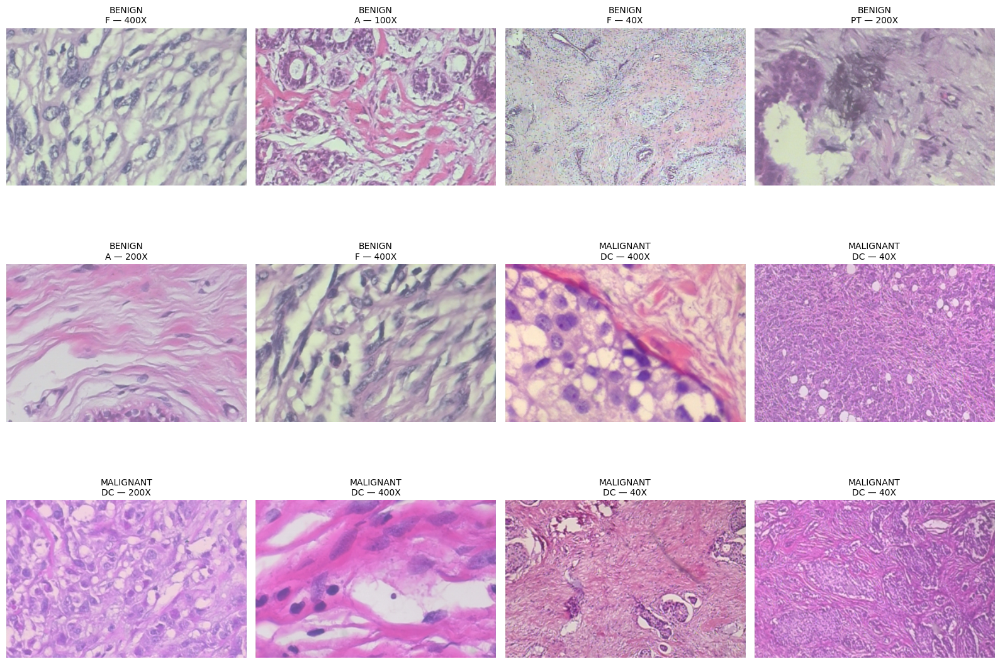


🔐 VÉRIFICATION FINALE DES SPLITS

TRAIN
Images   : 5,491
Patients : 56
{'malignant': 3673, 'benign': 1818}

VALIDATION
Images   : 1,072
Patients : 12
{'malignant': 757, 'benign': 315}

TEST
Images   : 1,346
Patients : 13
{'malignant': 999, 'benign': 347}

🎯 RÉSUMÉ CELL 05

Images totales       : 7,909
Images corrompues    : 0
Fichiers manquants   : 0

Patients uniques     : 81

Classes              : 2
Sous-types            : 8
Grossissements        : 4

Train images         : 5,491
Validation images    : 1,072
Test images          : 1,346

✅ CELL 05 TERMINÉE


In [7]:
# ============================================================================
# CELL 05 — CONTRÔLE QUALITÉ DES IMAGES BREAKHIS
# ============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

print("=" * 80)
print("🔎 CELL 05 — CONTRÔLE QUALITÉ DES IMAGES")
print("=" * 80)

# ============================================================================
# 1. CHARGEMENT DE L'INDEX FINAL
# ============================================================================

SPLIT_INDEX_PATH = (
    "/kaggle/working/"
    "breakhis_patient_level_split.csv"
)

df = pd.read_csv(SPLIT_INDEX_PATH)

print("\n✅ Index chargé")
print(f"Images : {len(df):,}")
print(f"Colonnes : {list(df.columns)}")

# ============================================================================
# 2. IDENTIFICATION DE LA COLONNE PATIENT
# ============================================================================

if "patient_id_corrected" in df.columns:
    PATIENT_COLUMN = "patient_id_corrected"
elif "patient_id" in df.columns:
    PATIENT_COLUMN = "patient_id"
else:
    raise KeyError(
        "❌ Colonne patient introuvable."
    )

print(f"\nPatient column : {PATIENT_COLUMN}")

# ============================================================================
# 3. VÉRIFICATION DES CHEMINS
# ============================================================================

print("\n" + "=" * 80)
print("📁 VÉRIFICATION DES FICHIERS")
print("=" * 80)

existing_files = 0
missing_files = []

for path in df["image_path"]:

    if os.path.exists(path):
        existing_files += 1
    else:
        missing_files.append(path)

print(f"Fichiers existants : {existing_files:,}")
print(f"Fichiers manquants : {len(missing_files):,}")

if missing_files:

    print("\n⚠️ Exemples de fichiers manquants :")

    for path in missing_files[:20]:
        print(path)

    raise FileNotFoundError(
        f"{len(missing_files)} fichiers sont introuvables."
    )

else:

    print("✅ Tous les chemins sont valides.")

# ============================================================================
# 4. TEST D'OUVERTURE DES IMAGES
# ============================================================================

print("\n" + "=" * 80)
print("🖼️ TEST D'OUVERTURE DES IMAGES")
print("=" * 80)

corrupted_images = []
image_sizes = Counter()
image_modes = Counter()

# Tester toutes les images
for i, path in enumerate(df["image_path"]):

    try:

        with Image.open(path) as img:

            # Vérifier réellement l'image
            img.verify()

        # Réouvrir après verify()
        with Image.open(path) as img:

            image_sizes[img.size] += 1
            image_modes[img.mode] += 1

    except Exception as e:

        corrupted_images.append(
            {
                "path": path,
                "error": str(e)
            }
        )

    # Progression
    if (i + 1) % 1000 == 0:

        print(
            f"Progression : "
            f"{i + 1:,}/{len(df):,}"
        )

print("\n" + "-" * 60)

print(
    f"Images testées    : {len(df):,}"
)

print(
    f"Images corrompues : {len(corrupted_images):,}"
)

if corrupted_images:

    print("\n⚠️ Images corrompues :")

    for item in corrupted_images[:20]:
        print(
            item["path"],
            "=>",
            item["error"]
        )

else:

    print(
        "✅ Aucune image corrompue détectée."
    )

# ============================================================================
# 5. DIMENSIONS DES IMAGES
# ============================================================================

print("\n" + "=" * 80)
print("📐 DIMENSIONS DES IMAGES")
print("=" * 80)

size_df = pd.DataFrame(
    [
        {
            "width": size[0],
            "height": size[1],
            "count": count
        }
        for size, count in image_sizes.items()
    ]
)

size_df = size_df.sort_values(
    "count",
    ascending=False
)

print(
    size_df.to_string(index=False)
)

# ============================================================================
# 6. MODES COULEUR
# ============================================================================

print("\n" + "=" * 80)
print("🎨 MODES COULEUR")
print("=" * 80)

for mode, count in image_modes.items():

    print(
        f"{mode:10s} : {count:,}"
    )

# ============================================================================
# 7. DISTRIBUTION DES CLASSES
# ============================================================================

print("\n" + "=" * 80)
print("🏷️ DISTRIBUTION DES CLASSES")
print("=" * 80)

class_distribution = (
    df["label"]
    .value_counts()
)

class_percentage = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class_table = pd.DataFrame(
    {
        "count": class_distribution,
        "percentage": class_percentage
    }
)

print(
    class_table
)

# ============================================================================
# 8. DISTRIBUTION DES CLASSES PAR SPLIT
# ============================================================================

print("\n" + "=" * 80)
print("📊 CLASSES PAR SPLIT")
print("=" * 80)

split_class = pd.crosstab(
    df["split"],
    df["label"]
)

print(split_class)

# ============================================================================
# 9. POURCENTAGES PAR SPLIT
# ============================================================================

print("\nPourcentages :")

split_class_percentage = (
    pd.crosstab(
        df["split"],
        df["label"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

print(
    split_class_percentage
)

# ============================================================================
# 10. DISTRIBUTION DES GROSSISSEMENTS
# ============================================================================

print("\n" + "=" * 80)
print("🔬 GROSSISSEMENTS")
print("=" * 80)

print(
    df["magnification"]
    .value_counts()
    .sort_index()
)

# ============================================================================
# 11. GROSSISSEMENT × CLASSE
# ============================================================================

print("\n" + "=" * 80)
print("🔬 GROSSISSEMENT × CLASSE")
print("=" * 80)

mag_class = pd.crosstab(
    df["magnification"],
    df["label"]
)

print(mag_class)

# ============================================================================
# 12. SOUS-TYPES
# ============================================================================

print("\n" + "=" * 80)
print("🔬 SOUS-TYPES HISTOLOGIQUES")
print("=" * 80)

print(
    df["subtype"]
    .value_counts()
)

# ============================================================================
# 13. PATIENTS
# ============================================================================

print("\n" + "=" * 80)
print("👤 PATIENTS")
print("=" * 80)

print(
    f"Patients uniques : "
    f"{df[PATIENT_COLUMN].nunique()}"
)

images_per_patient = (
    df.groupby(PATIENT_COLUMN)
    .size()
)

print(
    "\nImages par patient :"
)

print(
    images_per_patient.describe()
)

# ============================================================================
# 14. VISUALISATION — EXEMPLES
# ============================================================================

print("\n" + "=" * 80)
print("🖼️ VISUALISATION D'EXEMPLES")
print("=" * 80)

# Nombre d'exemples
N_EXAMPLES = 12

# Échantillon équilibré
examples = []

for label in ["benign", "malignant"]:

    subset = df[
        df["label"] == label
    ]

    n = min(
        N_EXAMPLES // 2,
        len(subset)
    )

    examples.append(
        subset.sample(
            n=n,
            random_state=42
        )
    )

examples_df = pd.concat(
    examples
).reset_index(drop=True)

# ============================================================================
# 15. AFFICHAGE
# ============================================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, (_, row) in zip(
    axes,
    examples_df.iterrows()
):

    try:

        img = Image.open(
            row["image_path"]
        ).convert("RGB")

        ax.imshow(img)

        ax.set_title(
            f"{row['label'].upper()}\n"
            f"{row['subtype']} — "
            f"{row['magnification']}",
            fontsize=10
        )

        ax.axis("off")

    except Exception as e:

        ax.text(
            0.5,
            0.5,
            "IMAGE ERROR",
            ha="center",
            va="center"
        )

        ax.axis("off")

plt.tight_layout()

plt.show()

# ============================================================================
# 16. VÉRIFICATION DES SPLITS
# ============================================================================

print("\n" + "=" * 80)
print("🔐 VÉRIFICATION FINALE DES SPLITS")
print("=" * 80)

for split_name in [
    "train",
    "validation",
    "test"
]:

    subset = df[
        df["split"] == split_name
    ]

    print(
        f"\n{split_name.upper()}"
    )

    print(
        f"Images   : {len(subset):,}"
    )

    print(
        f"Patients : "
        f"{subset[PATIENT_COLUMN].nunique()}"
    )

    print(
        subset["label"]
        .value_counts()
        .to_dict()
    )

# ============================================================================
# 17. RÉSUMÉ FINAL
# ============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 05")
print("=" * 80)

print(
    f"""
Images totales       : {len(df):,}
Images corrompues    : {len(corrupted_images):,}
Fichiers manquants   : {len(missing_files):,}

Patients uniques     : {df[PATIENT_COLUMN].nunique()}

Classes              : {df['label'].nunique()}
Sous-types            : {df['subtype'].nunique()}
Grossissements        : {df['magnification'].nunique()}

Train images         : {(df['split'] == 'train').sum():,}
Validation images    : {(df['split'] == 'validation').sum():,}
Test images          : {(df['split'] == 'test').sum():,}
"""
)

print("=" * 80)
print("✅ CELL 05 TERMINÉE")
print("=" * 80)

In [8]:
# =============================================================================
# CELL 06 — PRÉPARATION DES DATAFRAMES TRAIN / VALIDATION / TEST
# =============================================================================

import os
import pandas as pd
import numpy as np

print("=" * 80)
print("📦 CELL 06 — PRÉPARATION DES ENSEMBLES")
print("=" * 80)

# -----------------------------------------------------------------------------
# 1. Charger l'index final
# -----------------------------------------------------------------------------

INDEX_PATH = "/kaggle/working/breakhis_patient_level_split.csv"

if not os.path.exists(INDEX_PATH):
    raise FileNotFoundError(
        f"❌ Index introuvable : {INDEX_PATH}"
    )

df = pd.read_csv(INDEX_PATH)

print(f"\n✅ Index chargé")
print(f"Images : {len(df):,}")
print(f"Colonnes : {list(df.columns)}")

# -----------------------------------------------------------------------------
# 2. Vérification des colonnes nécessaires
# -----------------------------------------------------------------------------

REQUIRED_COLUMNS = [
    "image_path",
    "filename",
    "label",
    "label_id",
    "subtype",
    "patient_id",
    "magnification",
    "split"
]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"❌ Colonnes manquantes : {missing_columns}"
    )

print("\n✅ Toutes les colonnes nécessaires sont présentes.")

# -----------------------------------------------------------------------------
# 3. Normalisation du split
# -----------------------------------------------------------------------------

df["split"] = df["split"].astype(str).str.lower().str.strip()

# -----------------------------------------------------------------------------
# 4. Vérification des valeurs
# -----------------------------------------------------------------------------

VALID_SPLITS = {"train", "validation", "test"}

invalid_splits = set(df["split"].unique()) - VALID_SPLITS

if invalid_splits:
    raise ValueError(
        f"❌ Splits invalides détectés : {invalid_splits}"
    )

print(f"\nSplits détectés : {sorted(df['split'].unique())}")

# -----------------------------------------------------------------------------
# 5. Création des DataFrames
# -----------------------------------------------------------------------------

train_df = df[df["split"] == "train"].copy()
val_df   = df[df["split"] == "validation"].copy()
test_df  = df[df["split"] == "test"].copy()

# Reset index
train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

# -----------------------------------------------------------------------------
# 6. Résumé
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📊 RÉPARTITION")
print("=" * 80)

print(f"\nTRAIN")
print(f"Images   : {len(train_df):,}")
print(f"Patients : {train_df['patient_id'].nunique():,}")

print("\nVALIDATION")
print(f"Images   : {len(val_df):,}")
print(f"Patients : {val_df['patient_id'].nunique():,}")

print("\nTEST")
print(f"Images   : {len(test_df):,}")
print(f"Patients : {test_df['patient_id'].nunique():,}")

# -----------------------------------------------------------------------------
# 7. Distribution des classes
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🏷️ DISTRIBUTION DES CLASSES")
print("=" * 80)

for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    counts = split_df["label"].value_counts()

    print(f"\n{name}")
    print(counts)

    percentages = (
        split_df["label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("Pourcentages :")
    print(percentages)

# -----------------------------------------------------------------------------
# 8. Vérification des patients
# -----------------------------------------------------------------------------

train_patients = set(train_df["patient_id"])
val_patients   = set(val_df["patient_id"])
test_patients  = set(test_df["patient_id"])

overlap_train_val = train_patients & val_patients
overlap_train_test = train_patients & test_patients
overlap_val_test = val_patients & test_patients

print("\n" + "=" * 80)
print("🔒 VÉRIFICATION DES FUITES DE PATIENTS")
print("=" * 80)

print(f"\nTrain ∩ Validation : {len(overlap_train_val)}")
print(f"Train ∩ Test       : {len(overlap_train_test)}")
print(f"Validation ∩ Test  : {len(overlap_val_test)}")

if (
    len(overlap_train_val) == 0
    and len(overlap_train_test) == 0
    and len(overlap_val_test) == 0
):
    print("\n✅ AUCUNE FUITE DE PATIENT")
else:
    raise ValueError(
        "❌ Fuite de patients détectée !"
    )

# -----------------------------------------------------------------------------
# 9. Vérification des fichiers
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("📁 VÉRIFICATION DES FICHIERS")
print("=" * 80)

for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    exists = split_df["image_path"].map(os.path.exists)

    print(
        f"{name:<12} : "
        f"{exists.sum():,}/{len(exists):,} fichiers présents"
    )

    if not exists.all():
        print(
            f"⚠️ {len(exists) - exists.sum()} fichiers manquants"
        )

# -----------------------------------------------------------------------------
# 10. Affichage d'un échantillon
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("🔎 APERÇU TRAIN")
print("=" * 80)

display(
    train_df[
        [
            "filename",
            "label",
            "label_id",
            "subtype",
            "patient_id",
            "magnification"
        ]
    ].head(10)
)

# -----------------------------------------------------------------------------
# 11. Variables globales pour les cellules suivantes
# -----------------------------------------------------------------------------

TRAIN_DF = train_df
VAL_DF   = val_df
TEST_DF  = test_df

print("\n" + "=" * 80)
print("💾 VARIABLES PRÊTES")
print("=" * 80)

print("✓ TRAIN_DF")
print("✓ VAL_DF")
print("✓ TEST_DF")

print("\n" + "=" * 80)
print("✅ CELL 06 TERMINÉE")
print("=" * 80)

📦 CELL 06 — PRÉPARATION DES ENSEMBLES

✅ Index chargé
Images : 7,909
Colonnes : ['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification', 'split']

✅ Toutes les colonnes nécessaires sont présentes.

Splits détectés : ['test', 'train', 'validation']

📊 RÉPARTITION

TRAIN
Images   : 5,491
Patients : 56

VALIDATION
Images   : 1,072
Patients : 12

TEST
Images   : 1,346
Patients : 13

🏷️ DISTRIBUTION DES CLASSES

TRAIN
label
malignant    3673
benign       1818
Name: count, dtype: int64
Pourcentages :
label
malignant    66.89
benign       33.11
Name: proportion, dtype: float64

VALIDATION
label
malignant    757
benign       315
Name: count, dtype: int64
Pourcentages :
label
malignant    70.62
benign       29.38
Name: proportion, dtype: float64

TEST
label
malignant    999
benign       347
Name: count, dtype: int64
Pourcentages :
label
malignant    74.22
benign       25.78
Name: proportion, dtype: float64

🔒 VÉRIFICATION DES FUITES DE PATIENTS

Train ∩ Validati

,filename,label,label_id,subtype,patient_id,magnification
0,SOB_B_A-14-22549AB-100-001.png,benign,0,A,14-22549AB,100X
1,SOB_B_A-14-22549AB-100-002.png,benign,0,A,14-22549AB,100X
2,SOB_B_A-14-22549AB-100-003.png,benign,0,A,14-22549AB,100X
3,SOB_B_A-14-22549AB-100-004.png,benign,0,A,14-22549AB,100X
4,SOB_B_A-14-22549AB-100-005.png,benign,0,A,14-22549AB,100X
5,SOB_B_A-14-22549AB-100-006.png,benign,0,A,14-22549AB,100X
6,SOB_B_A-14-22549AB-100-007.png,benign,0,A,14-22549AB,100X
7,SOB_B_A-14-22549AB-100-008.png,benign,0,A,14-22549AB,100X
8,SOB_B_A-14-22549AB-100-009.png,benign,0,A,14-22549AB,100X
9,SOB_B_A-14-22549AB-100-010.png,benign,0,A,14-22549AB,100X



💾 VARIABLES PRÊTES
✓ TRAIN_DF
✓ VAL_DF
✓ TEST_DF

✅ CELL 06 TERMINÉE


In [9]:
# =============================================================================
# 🚀 CELL 07 — PIPELINE TF.DATA + AUGMENTATION (CORRIGÉE)
# =============================================================================
# BreakHis Histopathology
# 2 × NVIDIA Tesla T4
# TensorFlow 2.20 / Keras 3
#
# 🔧 CORRECTION APPLIQUÉE :
#   Les images sont désormais fournies au modèle en [0,255] et NON en
#   [0,1]. tf.keras.applications.EfficientNetB0 contient déjà sa propre
#   couche de rescaling/normalisation ImageNet en interne : diviser par
#   255 en amont "écrasait" les pixels vers une plage quasi nulle
#   ([0, 0.0039]) et empêchait le modèle d'exploiter les poids ImageNet.
#   C'est ce qui expliquait l'AUC-ROC ≈ 0.58 (modèle qui prédit presque
#   toujours "malignant").
# =============================================================================

import os
import math
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 80)
print("🚀 CELL 07 — PIPELINE TF.DATA + AUGMENTATION")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

IMAGE_SIZE = (224, 224)
IMAGE_CHANNELS = 3

GLOBAL_BATCH_SIZE = 64

AUTOTUNE = tf.data.AUTOTUNE
SEED = 42

# Vérification de la stratégie créée dans la Cell 01
try:
    NUM_REPLICAS = strategy.num_replicas_in_sync
except NameError:
    print("⚠️ strategy non trouvée.")
    print("➡️ Création automatique de MirroredStrategy...")
    strategy = tf.distribute.MirroredStrategy()
    NUM_REPLICAS = strategy.num_replicas_in_sync

BATCH_SIZE_PER_REPLICA = GLOBAL_BATCH_SIZE // NUM_REPLICAS

print("\nConfiguration :")
print(f"Image size       : {IMAGE_SIZE + (IMAGE_CHANNELS,)}")
print(f"Global batch     : {GLOBAL_BATCH_SIZE}")
print(f"Réplicas         : {NUM_REPLICAS}")
print(f"Batch / GPU      : {BATCH_SIZE_PER_REPLICA}")


# =============================================================================
# 2. VÉRIFICATION DES DATAFRAMES
# =============================================================================

required_columns = [
    "image_path",
    "label",
    "label_id",
    "patient_id",
    "subtype",
    "magnification"
]

for df_name, df in [
    ("TRAIN_DF", TRAIN_DF),
    ("VAL_DF", VAL_DF),
    ("TEST_DF", TEST_DF)
]:

    missing = [c for c in required_columns if c not in df.columns]

    if missing:
        raise ValueError(
            f"❌ {df_name} ne contient pas les colonnes : {missing}"
        )

    print(f"✓ {df_name:<10} : {len(df):,} images")


print()


# =============================================================================
# 3. NORMALISATION DES LABELS
# =============================================================================

# On force les labels en int32
TRAIN_DF = TRAIN_DF.copy()
VAL_DF = VAL_DF.copy()
TEST_DF = TEST_DF.copy()

TRAIN_DF["label_id"] = TRAIN_DF["label_id"].astype(np.int32)
VAL_DF["label_id"] = VAL_DF["label_id"].astype(np.int32)
TEST_DF["label_id"] = TEST_DF["label_id"].astype(np.int32)

print("Labels :")

print(
    "TRAIN :",
    np.unique(
        TRAIN_DF["label_id"].values,
        return_counts=True
    )
)

print(
    "VAL   :",
    np.unique(
        VAL_DF["label_id"].values,
        return_counts=True
    )
)

print(
    "TEST  :",
    np.unique(
        TEST_DF["label_id"].values,
        return_counts=True
    )
)


# =============================================================================
# 4. DATA AUGMENTATION (100% tf.image — AUCUNE couche keras.layers.*)
# =============================================================================
#
# ⚠️ IMPORTANT — pourquoi pas de keras.layers.Random* ici :
# Dans cet environnement (Keras 3 / TF 2.20 sur Kaggle), TOUTES les
# couches de prétraitement Keras (RandomFlip, RandomRotation, RandomZoom,
# RandomTranslation, RandomContrast, RandomBrightness...) héritent d'une
# classe de base commune ("DataLayer") qui vérifie en interne
# `isinstance(x, keras.KerasTensor)`. Ce symbole n'est pas exposé
# correctement dans cet environnement quand la couche est appelée à
# l'intérieur d'un pipeline tf.data.map() (contexte graphé/autograph),
# ce qui provoque un AttributeError — quelle que soit la couche utilisée.
#
# Solution robuste : réimplémenter toute l'augmentation avec des
# opérateurs tf.image "bruts", qui ne passent jamais par ce mécanisme
# Keras et fonctionnent de façon fiable dans tf.data.map().
#
# Couverture équivalente à la version précédente :
# - Flip horizontal + vertical
# - Rotation (par incréments de 90°, substitut robuste à la rotation
#   continue ±8° — TF n'offre pas de rotation continue "brute" sans
#   dépendance externe)
# - Zoom léger (crop aléatoire + resize)
# - Translation légère (incluse dans le crop aléatoire, dont la
#   position varie)
# - Contraste, luminosité, teinte, saturation légers (variabilité
#   de coloration H&E et d'exposition du scanner)
# =============================================================================

def geometric_augmentation(image):
    """
    Augmentation géométrique : flips, rotation 90°, zoom/translation
    via crop aléatoire + resize. 100% tf.image, sans couche Keras.
    """

    # Flips horizontal / vertical
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    # Rotation par incréments de 90° (0°, 90°, 180°, 270°)
    k = tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k=k)

    # Zoom léger + translation implicite : crop aléatoire (85% à 100%
    # de l'image) puis resize à la taille cible. La position du crop
    # étant aléatoire, ça introduit aussi une légère translation.
    crop_fraction = tf.random.uniform([], minval=0.85, maxval=1.0)

    crop_h = tf.cast(
        tf.cast(IMAGE_SIZE[0], tf.float32) * crop_fraction, tf.int32
    )
    crop_w = tf.cast(
        tf.cast(IMAGE_SIZE[1], tf.float32) * crop_fraction, tf.int32
    )

    image = tf.image.random_crop(
        image,
        size=[crop_h, crop_w, IMAGE_CHANNELS]
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method=tf.image.ResizeMethod.BILINEAR
    )

    return image


def photometric_augmentation(image):
    """
    Augmentation photométrique : luminosité, contraste, teinte,
    saturation. Simule la variabilité de coloration H&E et
    d'exposition du scanner entre laboratoires. 100% tf.image.
    """

    # Luminosité et contraste : opèrent directement en [0,255]
    image = tf.image.random_brightness(image, max_delta=25.0)
    image = tf.image.random_contrast(image, lower=0.85, upper=1.15)

    image = tf.clip_by_value(image, 0.0, 255.0)

    # Teinte / saturation : tf.image.random_hue et random_saturation
    # attendent des valeurs dans [0,1] pour une conversion HSV
    # correcte, on rescale donc temporairement.
    image_01 = image / 255.0

    image_01 = tf.image.random_hue(image_01, max_delta=0.03)
    image_01 = tf.image.random_saturation(image_01, lower=0.85, upper=1.15)

    image_01 = tf.clip_by_value(image_01, 0.0, 1.0)

    return image_01 * 255.0


print("✅ Augmentation créée (100% tf.image, sans couche Keras)")


# =============================================================================
# 5. FONCTION DE LECTURE DES IMAGES
# =============================================================================

def load_image(image_path, label):
    """
    Charge une image PNG/JPEG et retourne :
        image : float32 [0,255]  (PAS de division par 255,
                                   EfficientNetB0 applique déjà
                                   son propre rescaling interne)
        label : int32
    """

    # Lecture du fichier
    image = tf.io.read_file(image_path)

    # Décodage PNG/JPEG
    image = tf.image.decode_image(
        image,
        channels=IMAGE_CHANNELS,
        expand_animations=False
    )

    # Type float32 — SANS division par 255.
    # ⚠️ tf.image.convert_image_dtype(uint8 -> float32) rescale
    #    automatiquement vers [0,1], ce qui casse le preprocessing
    #    interne d'EfficientNetB0 (qui attend des pixels [0,255]).
    # On fait donc un simple cast, sans rescaling.
    image = tf.cast(
        image,
        tf.float32
    )

    # Resize
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method=tf.image.ResizeMethod.BILINEAR,
        antialias=True
    )

    # Sécurité : garantir [0,255]
    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    # Label
    label = tf.cast(
        label,
        tf.int32
    )

    return image, label


# =============================================================================
# 6. DATASET DE BASE
# =============================================================================

def create_base_dataset(df):
    """
    Création du dataset tf.data sans augmentation.
    """

    paths = df["image_path"].astype(str).values
    labels = df["label_id"].astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            paths,
            labels
        )
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return dataset


# =============================================================================
# 7. CRÉATION DU DATASET TRAIN
# =============================================================================

train_ds = create_base_dataset(
    TRAIN_DF
)

# Shuffle uniquement TRAIN
train_ds = train_ds.shuffle(
    buffer_size=len(TRAIN_DF),
    seed=SEED,
    reshuffle_each_iteration=True
)


# =============================================================================
# 8. AUGMENTATION TRAIN
# =============================================================================

def augment_train(image, label):

    image = geometric_augmentation(image)
    image = photometric_augmentation(image)

    # Sécurité après augmentation
    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    return image, label


train_ds = train_ds.map(
    augment_train,
    num_parallel_calls=AUTOTUNE
)


# =============================================================================
# 9. BATCH TRAIN
# =============================================================================

train_ds = train_ds.batch(
    GLOBAL_BATCH_SIZE,
    drop_remainder=False
)


# =============================================================================
# 10. VALIDATION DATASET
# =============================================================================

val_ds = create_base_dataset(
    VAL_DF
)

val_ds = val_ds.batch(
    GLOBAL_BATCH_SIZE,
    drop_remainder=False
)


# =============================================================================
# 11. TEST DATASET
# =============================================================================

test_ds = create_base_dataset(
    TEST_DF
)

test_ds = test_ds.batch(
    GLOBAL_BATCH_SIZE,
    drop_remainder=False
)


# =============================================================================
# 12. PREFETCH
# =============================================================================

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)


# =============================================================================
# 13. CLASS WEIGHTS
# =============================================================================
#
# BreakHis :
#
# malignant ≈ 68.6%
# benign    ≈ 31.4%
#
# On utilise des poids inversément proportionnels
# à la fréquence des classes.
# =============================================================================

class_counts = (
    TRAIN_DF["label_id"]
    .value_counts()
    .sort_index()
)

num_classes = len(class_counts)
total_samples = len(TRAIN_DF)

class_weights = {}

for class_id, count in class_counts.items():

    weight = (
        total_samples /
        (num_classes * count)
    )

    class_weights[int(class_id)] = float(weight)


print("\n" + "=" * 80)
print("⚖️ CLASS WEIGHTS")
print("=" * 80)

for class_id, weight in class_weights.items():

    class_name = (
        "benign"
        if class_id == 0
        else "malignant"
    )

    print(
        f"{class_name:<12} "
        f"(id={class_id}) : {weight:.4f}"
    )


# =============================================================================
# 14. VÉRIFICATION DES BATCHS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 TEST DU PIPELINE")
print("=" * 80)

sample_images, sample_labels = next(
    iter(train_ds)
)

print(
    f"\nBatch images : {sample_images.shape}"
)

print(
    f"Batch labels : {sample_labels.shape}"
)

print(
    f"Image dtype  : {sample_images.dtype}"
)

print(
    f"Image min    : {float(tf.reduce_min(sample_images)):.4f}"
)

print(
    f"Image max    : {float(tf.reduce_max(sample_images)):.4f}"
)

print(
    f"Image mean   : {float(tf.reduce_mean(sample_images)):.4f}"
)

print(
    "Labels batch :",
    np.unique(
        sample_labels.numpy()
    )
)


# =============================================================================
# 15. VÉRIFICATION DE LA PLAGE [0,1]
# =============================================================================

if (
    float(tf.reduce_min(sample_images)) >= 0.0
    and
    float(tf.reduce_max(sample_images)) <= 255.0
):

    print(
        "\n✅ Les images sont dans [0,255] (pixels bruts, "
        "PAS de division par 255 — EfficientNetB0 gère son "
        "propre rescaling en interne)"
    )

else:

    print(
        "\n❌ ERREUR : les images ne sont pas dans [0,255]"
    )


# =============================================================================
# 16. NOMBRE DE BATCHS
# =============================================================================

train_batches = math.ceil(
    len(TRAIN_DF) / GLOBAL_BATCH_SIZE
)

val_batches = math.ceil(
    len(VAL_DF) / GLOBAL_BATCH_SIZE
)

test_batches = math.ceil(
    len(TEST_DF) / GLOBAL_BATCH_SIZE
)

print("\n" + "=" * 80)
print("📊 NOMBRE DE BATCHS")
print("=" * 80)

print(
    f"Train      : {train_batches}"
)

print(
    f"Validation : {val_batches}"
)

print(
    f"Test       : {test_batches}"
)


# =============================================================================
# 17. VARIABLES GLOBALES UTILISÉES PAR LES CELLULES SUIVANTES
# =============================================================================

NUM_CLASSES = 2

CLASS_NAMES = [
    "benign",
    "malignant"
]

print("\n" + "=" * 80)
print("🎯 VARIABLES PRÊTES POUR LA SUITE")
print("=" * 80)

print("✓ train_ds")
print("✓ val_ds")
print("✓ test_ds")
print("✓ class_weights")
print("✓ data_augmentation")
print("✓ NUM_CLASSES")
print("✓ CLASS_NAMES")
print("✓ GLOBAL_BATCH_SIZE")
print("✓ BATCH_SIZE_PER_REPLICA")


# =============================================================================
# 18. RÉSUMÉ
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 07")
print("=" * 80)

print(
    f"\nImages train      : {len(TRAIN_DF):,}"
)

print(
    f"Images validation : {len(VAL_DF):,}"
)

print(
    f"Images test       : {len(TEST_DF):,}"
)

print(
    f"\nImage size        : "
    f"{IMAGE_SIZE[0]} × {IMAGE_SIZE[1]} × {IMAGE_CHANNELS}"
)

print(
    f"\nBatch global      : {GLOBAL_BATCH_SIZE}"
)

print(
    f"Batch / GPU       : {BATCH_SIZE_PER_REPLICA}"
)

print(
    "\nAugmentation      : ✅ TRAIN uniquement"
)

print(
    "Shuffle            : ✅ TRAIN"
)

print(
    "Prefetch           : ✅ AUTOTUNE"
)

print(
    "Class weights      : ✅"
)

print(
    "Train dataset      : ✅"
)

print(
    "Validation dataset : ✅"
)

print(
    "Test dataset       : ✅"
)

print("\n" + "=" * 80)
print("✅ CELL 07 TERMINÉE")
print("=" * 80)

🚀 CELL 07 — PIPELINE TF.DATA + AUGMENTATION

Configuration :
Image size       : (224, 224, 3)
Global batch     : 64
Réplicas         : 2
Batch / GPU      : 32
✓ TRAIN_DF   : 5,491 images
✓ VAL_DF     : 1,072 images
✓ TEST_DF    : 1,346 images

Labels :
TRAIN : (array([0, 1], dtype=int32), array([1818, 3673]))
VAL   : (array([0, 1], dtype=int32), array([315, 757]))
TEST  : (array([0, 1], dtype=int32), array([347, 999]))
✅ Augmentation créée (100% tf.image, sans couche Keras)

⚖️ CLASS WEIGHTS
benign       (id=0) : 1.5102
malignant    (id=1) : 0.7475

🔎 TEST DU PIPELINE

Batch images : (64, 224, 224, 3)
Batch labels : (64,)
Image dtype  : <dtype: 'float32'>
Image min    : 0.0000
Image max    : 255.0000
Image mean   : 183.0876
Labels batch : [0 1]

✅ Les images sont dans [0,255] (pixels bruts, PAS de division par 255 — EfficientNetB0 gère son propre rescaling en interne)

📊 NOMBRE DE BATCHS
Train      : 86
Validation : 17
Test       : 22

🎯 VARIABLES PRÊTES POUR LA SUITE
✓ train_ds
✓ val_

In [10]:
# ============================================================================
# 🧠 CELL 08 — CRÉATION DU MODÈLE DE CLASSIFICATION HISTOPATHOLOGIQUE
# ============================================================================
#
# Objectif :
#   Construire un modèle EfficientNetB0 avec Transfer Learning
#   pour classifier les images histopathologiques :
#
#       0 → benign
#       1 → malignant
#
# Architecture :
#
#       Image 224x224x3
#              ↓
#       EfficientNetB0
#       (ImageNet - frozen)
#              ↓
#       GlobalAveragePooling2D
#              ↓
#       BatchNormalization
#              ↓
#       Dropout
#              ↓
#       Dense
#              ↓
#       Sigmoid
#              ↓
#       benign / malignant
#
# ============================================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 80)
print("🧠 CELL 08 — CRÉATION DU MODÈLE")
print("=" * 80)

# ============================================================================
# 1. VÉRIFICATION DE L'ENVIRONNEMENT
# ============================================================================

print("\n📌 ENVIRONNEMENT")
print("-" * 80)

print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {keras.__version__}")

# Vérification de la stratégie
try:
    print(f"Réplicas   : {strategy.num_replicas_in_sync}")
except NameError:
    print("⚠️ Variable 'strategy' absente.")

# ============================================================================
# 2. CONFIGURATION
# ============================================================================

MODEL_NAME = "EfficientNetB0_BreakHis"

INPUT_SHAPE = (
    IMAGE_SIZE[0],
    IMAGE_SIZE[1],
    3
)

NUM_CLASSES = 2

print("\n📐 CONFIGURATION")
print("-" * 80)

print(f"Modèle          : {MODEL_NAME}")
print(f"Input shape     : {INPUT_SHAPE}")
print(f"Nombre classes  : {NUM_CLASSES}")
print(f"Classes         : {CLASS_NAMES}")

# ============================================================================
# 3. CRÉATION DU MODÈLE
# ============================================================================
#
# IMPORTANT :
# Le modèle est créé dans strategy.scope() afin que les deux GPU T4
# participent correctement à l'entraînement.
# ============================================================================

with strategy.scope():

    # ------------------------------------------------------------------------
    # Backbone EfficientNetB0
    # ------------------------------------------------------------------------

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=INPUT_SHAPE
    )

    # Première phase :
    # on gèle le backbone.
    base_model.trainable = False

    # ------------------------------------------------------------------------
    # Entrée
    # ------------------------------------------------------------------------

    inputs = keras.Input(
        shape=INPUT_SHAPE,
        name="histopathology_image"
    )

    # ------------------------------------------------------------------------
    # Backbone
    # ------------------------------------------------------------------------
    #
    # training=False est important ici car le backbone est gelé.
    # Cela permet également de conserver le comportement approprié
    # des couches BatchNormalization pendant cette première phase.
    # ------------------------------------------------------------------------

    x = base_model(
        inputs,
        training=False
    )

    # ------------------------------------------------------------------------
    # Global Average Pooling
    # ------------------------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    # ------------------------------------------------------------------------
    # Normalisation
    # ------------------------------------------------------------------------

    x = layers.BatchNormalization(
        name="classifier_batch_norm"
    )(x)

    # ------------------------------------------------------------------------
    # Dropout
    # ------------------------------------------------------------------------

    x = layers.Dropout(
        0.40,
        name="classifier_dropout"
    )(x)

    # ------------------------------------------------------------------------
    # Couche dense
    # ------------------------------------------------------------------------

    x = layers.Dense(
        128,
        activation="relu",
        name="classifier_dense"
    )(x)

    x = layers.Dropout(
        0.30,
        name="classifier_dropout_2"
    )(x)

    # ------------------------------------------------------------------------
    # Sortie binaire
    # ------------------------------------------------------------------------

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="malignancy_probability"
    )(x)

    # ------------------------------------------------------------------------
    # Modèle final
    # ------------------------------------------------------------------------

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=MODEL_NAME
    )

# ============================================================================
# 4. AFFICHAGE DU MODÈLE
# ============================================================================

print("\n🏗️ ARCHITECTURE")
print("-" * 80)

model.summary()

# ============================================================================
# 5. PARAMÈTRES
# ============================================================================

total_params = model.count_params()

trainable_params = sum(
    tf.keras.backend.count_params(weight)
    for weight in model.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(weight)
    for weight in model.non_trainable_weights
)

print("\n📊 PARAMÈTRES")
print("-" * 80)

print(f"Paramètres totaux       : {total_params:,}")
print(f"Paramètres entraînables : {trainable_params:,}")
print(f"Paramètres gelés        : {non_trainable_params:,}")

# ============================================================================
# 6. VÉRIFICATION DU BACKBONE
# ============================================================================

print("\n🔒 BACKBONE")
print("-" * 80)

print(f"EfficientNetB0 trainable : {base_model.trainable}")
print(f"Couches backbone         : {len(base_model.layers)}")

# ============================================================================
# 7. TEST AVEC UN BATCH
# ============================================================================

print("\n🔎 TEST DU MODÈLE")
print("-" * 80)

try:

    sample_images, sample_labels = next(
        iter(train_ds)
    )

    predictions = model(
        sample_images,
        training=False
    )

    print(f"Images entrée      : {sample_images.shape}")
    print(f"Labels             : {sample_labels.shape}")
    print(f"Predictions        : {predictions.shape}")

    print(
        f"Min probabilité    : "
        f"{float(tf.reduce_min(predictions)):.4f}"
    )

    print(
        f"Max probabilité    : "
        f"{float(tf.reduce_max(predictions)):.4f}"
    )

    print(
        f"Moyenne probabilité: "
        f"{float(tf.reduce_mean(predictions)):.4f}"
    )

    print("✅ Forward pass réussi")

except Exception as e:

    print("❌ Erreur pendant le test du modèle")
    print(f"Erreur : {e}")

# ============================================================================
# 8. TEST DES DEUX GPU
# ============================================================================

print("\n🖥️ HARDWARE")
print("-" * 80)

gpus = tf.config.list_physical_devices("GPU")

print(f"GPU détectés : {len(gpus)}")

for i, gpu in enumerate(gpus):
    print(f"GPU {i} : {gpu}")

try:
    print(
        f"Réplicas MirroredStrategy : "
        f"{strategy.num_replicas_in_sync}"
    )
except NameError:
    pass

# ============================================================================
# 9. VARIABLES DISPONIBLES POUR LA CELLULE SUIVANTE
# ============================================================================

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)

print("✓ base_model")
print("✓ model")
print("✓ MODEL_NAME")
print("✓ INPUT_SHAPE")
print("✓ NUM_CLASSES")
print("✓ CLASS_NAMES")

print("\n" + "=" * 80)
print("✅ CELL 08 TERMINÉE")
print("=" * 80)

🧠 CELL 08 — CRÉATION DU MODÈLE

📌 ENVIRONNEMENT
--------------------------------------------------------------------------------
TensorFlow : 2.20.0
Keras      : 3.13.2
Réplicas   : 2

📐 CONFIGURATION
--------------------------------------------------------------------------------
Modèle          : EfficientNetB0_BreakHis
Input shape     : (224, 224, 3)
Nombre classes  : 2
Classes         : ['benign', 'malignant']
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

🏗️ ARCHITECTURE
--------------------------------------------------------------------------------


Model: "EfficientNetB0_BreakHis"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ histopathology_image            │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_batch_norm           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout_2 (Dropout)  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ malignancy_probability (Dense)  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,218,788 (16.09 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 4,052,131 (15.46 MB)


📊 PARAMÈTRES
--------------------------------------------------------------------------------
Paramètres totaux       : 4,218,788
Paramètres entraînables : 166,657
Paramètres gelés        : 4,052,131.0

🔒 BACKBONE
--------------------------------------------------------------------------------
EfficientNetB0 trainable : False
Couches backbone         : 238

🔎 TEST DU MODÈLE
--------------------------------------------------------------------------------
Images entrée      : (64, 224, 224, 3)
Labels             : (64,)
Predictions        : (64, 1)
Min probabilité    : 0.3212
Max probabilité    : 0.6615
Moyenne probabilité: 0.4804
✅ Forward pass réussi

🖥️ HARDWARE
--------------------------------------------------------------------------------
GPU détectés : 2
GPU 0 : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
GPU 1 : PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Réplicas MirroredStrategy : 2

💾 VARIABLES PRÊTES
---------------------------------

In [11]:
# ============================================================================
# 🚀 CELL 09 — COMPILATION DU MODÈLE
# ============================================================================
#
# Objectif :
#   Compiler EfficientNetB0 avant la phase d'entraînement.
#
# Problème :
#   Classification binaire :
#
#       0 = benign
#       1 = malignant
#
# ============================================================================

import tensorflow as tf
from tensorflow import keras

print("=" * 80)
print("🚀 CELL 09 — COMPILATION DU MODÈLE")
print("=" * 80)

# ============================================================================
# 1. CONFIGURATION
# ============================================================================

INITIAL_LEARNING_RATE = 1e-3

print("\n⚙️ CONFIGURATION")
print("-" * 80)

LABEL_SMOOTHING = 0.05

print(f"Learning rate initial : {INITIAL_LEARNING_RATE}")
print(f"Label smoothing       : {LABEL_SMOOTHING}")
print("Loss                  : Binary Crossentropy (label smoothing)")
print("Optimizer             : Adam")
print("Backbone              : Frozen")
print("Classification        : Binary")

# ============================================================================
# 2. MÉTRIQUES
# ============================================================================

metrics = [

    # Accuracy
    keras.metrics.BinaryAccuracy(
        name="accuracy"
    ),

    # Precision
    keras.metrics.Precision(
        name="precision"
    ),

    # Recall / Sensibilité
    keras.metrics.Recall(
        name="recall"
    ),

    # AUC ROC
    keras.metrics.AUC(
        name="auc_roc",
        curve="ROC"
    ),

    # AUC Precision-Recall
    keras.metrics.AUC(
        name="auc_pr",
        curve="PR"
    )
]

# ============================================================================
# 3. COMPILATION
# ============================================================================

with strategy.scope():

    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=INITIAL_LEARNING_RATE
        ),

        # 🆕 label_smoothing : évite au modèle d'être sur-confiant
        # (utile avec un dataset de taille modeste comme BreakHis,
        # régularise et améliore souvent l'AUC en validation/test)
        loss=keras.losses.BinaryCrossentropy(
            from_logits=False,
            label_smoothing=LABEL_SMOOTHING
        ),

        metrics=metrics
    )

# ============================================================================
# 4. AFFICHAGE
# ============================================================================

print("\n✅ MODÈLE COMPILÉ")
print("-" * 80)

print("Optimizer : Adam")
print(f"Learning rate : {INITIAL_LEARNING_RATE}")

print("\nLoss : BinaryCrossentropy")

print("\nMétriques :")

for metric in model.metrics:
    print(f"  ✓ {metric.name}")

# ============================================================================
# 5. TEST DE COMPILATION
# ============================================================================

print("\n🔎 TEST DE COMPILATION")
print("-" * 80)

try:

    sample_images, sample_labels = next(
        iter(train_ds)
    )

    results = model.evaluate(
        sample_images,
        sample_labels,
        verbose=0
    )

    print("✅ Évaluation initiale réussie")

    for name, value in zip(
        model.metrics_names,
        results
    ):
        print(
            f"{name:15s}: {value:.4f}"
        )

except Exception as e:

    print("❌ Erreur pendant l'évaluation")
    print(f"Erreur : {e}")

# ============================================================================
# 6. VÉRIFICATION HARDWARE
# ============================================================================

print("\n🖥️ HARDWARE")
print("-" * 80)

gpus = tf.config.list_physical_devices("GPU")

print(f"GPU détectés : {len(gpus)}")

for i, gpu in enumerate(gpus):

    print(
        f"GPU {i} : {gpu}"
    )

print(
    f"\nRéplicas : "
    f"{strategy.num_replicas_in_sync}"
)

# ============================================================================
# 7. VARIABLES PRÊTES
# ============================================================================

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)

print("✓ model")
print("✓ base_model")
print("✓ train_ds")
print("✓ val_ds")
print("✓ test_ds")
print("✓ class_weights")

print("\n" + "=" * 80)
print("✅ CELL 09 TERMINÉE")
print("=" * 80)

🚀 CELL 09 — COMPILATION DU MODÈLE

⚙️ CONFIGURATION
--------------------------------------------------------------------------------
Learning rate initial : 0.001
Label smoothing       : 0.05
Loss                  : Binary Crossentropy (label smoothing)
Optimizer             : Adam
Backbone              : Frozen
Classification        : Binary

✅ MODÈLE COMPILÉ
--------------------------------------------------------------------------------
Optimizer : Adam
Learning rate : 0.001

Loss : BinaryCrossentropy

Métriques :
  ✓ loss
  ✓ compile_metrics

🔎 TEST DE COMPILATION
--------------------------------------------------------------------------------
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device

In [12]:
# ============================================================================
# 🚀 CELL 10 — ENTRAÎNEMENT PHASE 1
# ============================================================================
#
# EfficientNetB0 :
#   Backbone GELÉ
#   ↓
#   Classification binaire
#   ↓
#   Benign / Malignant
#
# Objectif :
#   Apprendre d'abord la tête de classification avant le fine-tuning.
# ============================================================================

import os
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras

print("=" * 80)
print("🚀 CELL 10 — ENTRAÎNEMENT PHASE 1")
print("=" * 80)

# ============================================================================
# 1. CONFIGURATION
# ============================================================================

EPOCHS_PHASE_1 = 15

MODEL_DIR = "/kaggle/working/breakhis_models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "EfficientNetB0_BreakHis_phase1_best.keras"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "EfficientNetB0_BreakHis_phase1_final.keras"
)

print("\n⚙️ CONFIGURATION")
print("-" * 80)

print(f"Epochs maximum : {EPOCHS_PHASE_1}")
print(f"Batch global   : {GLOBAL_BATCH_SIZE}")
print(f"Batch / GPU    : {BATCH_SIZE_PER_REPLICA}")
print(f"Réplicas       : {strategy.num_replicas_in_sync}")

print("\nBackbone : EfficientNetB0")
print("Backbone trainable : False")

# ============================================================================
# 2. VÉRIFICATION DU BACKBONE
# ============================================================================

print("\n🔒 VÉRIFICATION DU BACKBONE")
print("-" * 80)

print(
    f"Trainable : {base_model.trainable}"
)

trainable_backbone = sum(
    int(layer.trainable)
    for layer in base_model.layers
)

print(
    f"Couches trainables dans backbone : "
    f"{trainable_backbone}/{len(base_model.layers)}"
)

if base_model.trainable:
    print("⚠️ ATTENTION : le backbone n'est pas gelé.")
else:
    print("✅ Backbone correctement gelé.")

# ============================================================================
# 3. CALLBACKS
# ============================================================================

callbacks = [

    # ------------------------------------------------------------------------
    # Sauvegarder uniquement le meilleur modèle
    # ------------------------------------------------------------------------

    keras.callbacks.ModelCheckpoint(

        filepath=BEST_MODEL_PATH,

        monitor="val_auc_roc",

        mode="max",

        save_best_only=True,

        save_weights_only=False,

        verbose=1
    ),

    # ------------------------------------------------------------------------
    # Arrêt anticipé
    # ------------------------------------------------------------------------

    keras.callbacks.EarlyStopping(

        monitor="val_auc_roc",

        mode="max",

        patience=4,

        min_delta=0.001,

        restore_best_weights=True,

        verbose=1
    ),

    # ------------------------------------------------------------------------
    # Réduction du learning rate
    # ------------------------------------------------------------------------

    keras.callbacks.ReduceLROnPlateau(

        monitor="val_auc_roc",

        mode="max",

        factor=0.3,

        patience=2,

        min_lr=1e-6,

        verbose=1
    ),

    # ------------------------------------------------------------------------
    # CSV des résultats
    # ------------------------------------------------------------------------

    keras.callbacks.CSVLogger(

        os.path.join(
            MODEL_DIR,
            "phase1_training_log.csv"
        )
    )
]

print("\n✅ Callbacks configurés")

# ============================================================================
# 4. VÉRIFICATION DU DATASET
# ============================================================================

print("\n📊 DATASETS")
print("-" * 80)

print(
    f"Train      : {len(TRAIN_DF):,} images"
)

print(
    f"Validation : {len(VAL_DF):,} images"
)

print(
    f"Test       : {len(TEST_DF):,} images"
)

print(
    f"\nTrain batches      : {len(TRAIN_DF) // GLOBAL_BATCH_SIZE}"
)

print(
    f"Validation batches : {len(VAL_DF) // GLOBAL_BATCH_SIZE}"
)

print(
    f"Test batches       : {len(TEST_DF) // GLOBAL_BATCH_SIZE}"
)

# ============================================================================
# 5. CLASS WEIGHTS
# ============================================================================

print("\n⚖️ CLASS WEIGHTS")
print("-" * 80)

for class_id, weight in class_weights.items():

    class_name = CLASS_NAMES[int(class_id)]

    print(
        f"{class_name:12s} "
        f"(id={class_id}) : {weight:.4f}"
    )

# ============================================================================
# 6. ENTRAÎNEMENT
# ============================================================================

print("\n" + "=" * 80)
print("🔥 DÉBUT DE L'ENTRAÎNEMENT")
print("=" * 80)

print("\nPhase 1 : tête de classification uniquement")

print(
    "\nEfficientNetB0 gelé → "
    "Classifier entraîné"
)

print("\n")

start_time = time.time()

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_PHASE_1,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)

elapsed_time = time.time() - start_time

# ============================================================================
# 7. TEMPS D'ENTRAÎNEMENT
# ============================================================================

print("\n" + "=" * 80)
print("⏱️ TEMPS D'ENTRAÎNEMENT")
print("=" * 80)

print(
    f"Durée totale : "
    f"{elapsed_time / 60:.2f} minutes"
)

print(
    f"Durée totale : "
    f"{elapsed_time / 3600:.2f} heures"
)

# ============================================================================
# 8. NOMBRE D'EPOCHS EFFECTUÉS
# ============================================================================

epochs_completed = len(
    history.history["loss"]
)

print(
    f"\nEpochs effectués : "
    f"{epochs_completed}"
)

# ============================================================================
# 9. MEILLEURS RÉSULTATS
# ============================================================================

print("\n" + "=" * 80)
print("🏆 MEILLEURS RÉSULTATS PHASE 1")
print("=" * 80)

# ---------------------------------------------------------------------------
# Meilleur AUC ROC
# ---------------------------------------------------------------------------

best_auc = max(
    history.history["val_auc_roc"]
)

best_auc_epoch = (
    np.argmax(
        history.history["val_auc_roc"]
    ) + 1
)

print(
    f"\n🥇 Meilleur Validation AUC ROC : "
    f"{best_auc:.4f}"
)

print(
    f"   Epoch : {best_auc_epoch}"
)

# ---------------------------------------------------------------------------
# Meilleure validation accuracy
# ---------------------------------------------------------------------------

best_val_acc = max(
    history.history["val_accuracy"]
)

best_val_acc_epoch = (
    np.argmax(
        history.history["val_accuracy"]
    ) + 1
)

print(
    f"\n🎯 Meilleure Validation Accuracy : "
    f"{best_val_acc:.4f}"
)

print(
    f"   Epoch : {best_val_acc_epoch}"
)

# ---------------------------------------------------------------------------
# Meilleure validation recall
# ---------------------------------------------------------------------------

best_val_recall = max(
    history.history["val_recall"]
)

best_val_recall_epoch = (
    np.argmax(
        history.history["val_recall"]
    ) + 1
)

print(
    f"\n🔬 Meilleur Validation Recall : "
    f"{best_val_recall:.4f}"
)

print(
    f"   Epoch : {best_val_recall_epoch}"
)

# ============================================================================
# 10. DERNIÈRE EPOCH
# ============================================================================

print("\n" + "=" * 80)
print("📈 DERNIÈRE EPOCH")
print("=" * 80)

last_epoch = epochs_completed - 1

for metric_name, values in history.history.items():

    if len(values) > last_epoch:

        print(
            f"{metric_name:20s}: "
            f"{values[last_epoch]:.4f}"
        )

# ============================================================================
# 11. SAUVEGARDE DU MODÈLE FINAL
# ============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE")
print("=" * 80)

model.save(
    FINAL_MODEL_PATH
)

print(
    f"✅ Modèle final sauvegardé :\n"
    f"{FINAL_MODEL_PATH}"
)

print(
    f"\n✅ Meilleur modèle sauvegardé :\n"
    f"{BEST_MODEL_PATH}"
)

# ============================================================================
# 12. VÉRIFICATION DES FICHIERS
# ============================================================================

print("\n📁 VÉRIFICATION")
print("-" * 80)

if os.path.exists(BEST_MODEL_PATH):

    size_mb = (
        os.path.getsize(
            BEST_MODEL_PATH
        ) / (1024 ** 2)
    )

    print(
        f"✅ Best model : "
        f"{size_mb:.2f} MB"
    )

else:

    print(
        "❌ Best model introuvable"
    )


if os.path.exists(FINAL_MODEL_PATH):

    size_mb = (
        os.path.getsize(
            FINAL_MODEL_PATH
        ) / (1024 ** 2)
    )

    print(
        f"✅ Final model : "
        f"{size_mb:.2f} MB"
    )

else:

    print(
        "❌ Final model introuvable"
    )

# ============================================================================
# 13. VARIABLES PRÊTES
# ============================================================================

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)

print("✓ history")
print("✓ model")
print("✓ BEST_MODEL_PATH")
print("✓ FINAL_MODEL_PATH")
print("✓ callbacks")

print("\n" + "=" * 80)
print("✅ CELL 10 TERMINÉE")
print("=" * 80)

🚀 CELL 10 — ENTRAÎNEMENT PHASE 1

⚙️ CONFIGURATION
--------------------------------------------------------------------------------
Epochs maximum : 15
Batch global   : 64
Batch / GPU    : 32
Réplicas       : 2

Backbone : EfficientNetB0
Backbone trainable : False

🔒 VÉRIFICATION DU BACKBONE
--------------------------------------------------------------------------------
Trainable : False
Couches trainables dans backbone : 0/238
✅ Backbone correctement gelé.

✅ Callbacks configurés

📊 DATASETS
--------------------------------------------------------------------------------
Train      : 5,491 images
Validation : 1,072 images
Test       : 1,346 images

Train batches      : 85
Validation batches : 16
Test batches       : 21

⚖️ CLASS WEIGHTS
--------------------------------------------------------------------------------
benign       (id=0) : 1.5102
malignant    (id=1) : 0.7475

🔥 DÉBUT DE L'ENTRAÎNEMENT

Phase 1 : tête de classification uniquement

EfficientNetB0 gelé → Classifier entraî

E0000 00:00:1786366959.864545      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_BreakHis_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.7202 - auc_pr: 0.8758 - auc_roc: 0.7999 - loss: 0.6664 - precision: 0.8448 - recall: 0.6906
Epoch 1: val_auc_roc improved from None to 0.86684, saving model to /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras
86/86 ━━━━━━━━━━━━━━━━━━━━ 69s 273ms/step - accuracy: 0.7833 - auc_pr: 0.9248 - auc_roc: 0.8652 - loss: 0.5573 - precision: 0.8850 - recall: 0.7770 - val_accuracy: 0.8703 - val_auc_pr: 0.9125 - val_auc_roc: 0.8668 - val_loss: 0.4377 - val_precision: 0.8759 - val_recall: 0.9511 - learning_rate: 0.0010
Epoch 2/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8362 - auc_pr: 0.9497 - auc_roc: 0.9133 - loss: 0.4551 - precision: 0.9063 - recall: 0.8338
Epoch 2: val_auc_roc improved from 0.86684 to 0.87149, saving model to /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.kera

In [13]:
# =============================================================================
# 🧪 CELL 11 — ÉVALUATION COMPLÈTE DU MODÈLE + PROGRESSION
# =============================================================================

import os
import time
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# =============================================================================
# 0. CONFIGURATION
# =============================================================================

print("=" * 80)
print("🧪 CELL 11 — ÉVALUATION COMPLÈTE EfficientNetB0 + BreaKHis")
print("=" * 80)

START_TIME = time.time()

BEST_MODEL_PATH = "/kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras"

print("\n📌 Vérification de l'environnement...")
print(f"TensorFlow : {tf.__version__}")
print(f"GPU détectés : {len(tf.config.list_physical_devices('GPU'))}")

if tf.config.list_physical_devices('GPU'):
    for i, gpu in enumerate(tf.config.list_physical_devices('GPU')):
        print(f"GPU {i} : {gpu}")

print("\n📁 Modèle à évaluer :")
print(BEST_MODEL_PATH)

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"❌ Modèle introuvable : {BEST_MODEL_PATH}"
    )

print("✅ Fichier modèle trouvé")

# =============================================================================
# 1. VÉRIFICATION DES VARIABLES
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES VARIABLES")
print("=" * 80)

required_vars = [
    "model",
    "train_ds",
    "val_ds",
    "test_ds",
    "TEST_DF",
    "CLASS_NAMES"
]

for var in required_vars:
    if var in globals():
        print(f"✓ {var}")
    else:
        print(f"❌ {var} absent")

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise RuntimeError(
        f"❌ Variables manquantes : {missing_vars}"
    )

print("\n✅ Toutes les variables nécessaires sont disponibles.")

print(f"\nClasses : {CLASS_NAMES}")
print(f"Nombre de classes : {len(CLASS_NAMES)}")

print(f"\nTEST_DF : {len(TEST_DF):,} images")

# =============================================================================
# 2. VÉRIFICATION DU DATASET TEST
# =============================================================================

print("\n" + "=" * 80)
print("🧪 VÉRIFICATION TEST DATASET")
print("=" * 80)

try:
    print("🔄 Lecture du premier batch...")

    test_start = time.time()

    test_batch_images, test_batch_labels = next(
        iter(test_ds)
    )

    elapsed = time.time() - test_start

    print(f"✅ Premier batch chargé en {elapsed:.2f} secondes")

    print(f"Images : {test_batch_images.shape}")
    print(f"Labels : {test_batch_labels.shape}")
    print(f"Type images : {test_batch_images.dtype}")
    print(f"Type labels : {test_batch_labels.dtype}")

    print(
        f"Min image : {float(tf.reduce_min(test_batch_images)):.4f}"
    )

    print(
        f"Max image : {float(tf.reduce_max(test_batch_images)):.4f}"
    )

    print(
        f"Moyenne image : {float(tf.reduce_mean(test_batch_images)):.4f}"
    )

    print(
        f"Labels batch : {np.unique(test_batch_labels.numpy())}"
    )

except Exception as e:
    print("❌ Erreur lors du test du dataset")
    print(str(e))
    raise

# =============================================================================
# 3. CHARGEMENT DU MEILLEUR MODÈLE
# =============================================================================

print("\n" + "=" * 80)
print("📦 CHARGEMENT DU MEILLEUR MODÈLE")
print("=" * 80)

print("⏳ Chargement en cours...")
print("⚠️ Cette étape peut prendre quelques secondes...")

load_start = time.time()

try:
    eval_model = tf.keras.models.load_model(
        BEST_MODEL_PATH,
        compile=False
    )

    load_time = time.time() - load_start

    print(f"✅ Modèle chargé en {load_time:.2f} secondes")

except Exception as e:
    print("❌ Impossible de charger le modèle")
    print(str(e))
    raise

print("\nArchitecture :")
print(f"Nom : {eval_model.name}")
print(f"Input : {eval_model.input_shape}")
print(f"Output : {eval_model.output_shape}")

print(
    f"Paramètres : {eval_model.count_params():,}"
)

# =============================================================================
# 4. FORWARD PASS TEST
# =============================================================================

print("\n" + "=" * 80)
print("⚡ TEST FORWARD PASS")
print("=" * 80)

print("⏳ Exécution d'une prédiction sur le premier batch...")

forward_start = time.time()

try:

    test_predictions = eval_model(
        test_batch_images,
        training=False
    )

    forward_time = time.time() - forward_start

    print(
        f"✅ Forward pass terminé en {forward_time:.2f} secondes"
    )

    print(
        f"Shape prédictions : {test_predictions.shape}"
    )

    print(
        f"Min probabilité : "
        f"{float(tf.reduce_min(test_predictions)):.4f}"
    )

    print(
        f"Max probabilité : "
        f"{float(tf.reduce_max(test_predictions)):.4f}"
    )

    print(
        f"Moyenne probabilité : "
        f"{float(tf.reduce_mean(test_predictions)):.4f}"
    )

except Exception as e:
    print("❌ Erreur pendant le forward pass")
    print(str(e))
    raise

# =============================================================================
# 5. NOMBRE DE BATCHS
# =============================================================================

print("\n" + "=" * 80)
print("📊 PRÉPARATION DE L'ÉVALUATION")
print("=" * 80)

try:
    test_batches = tf.data.experimental.cardinality(test_ds).numpy()

    if test_batches < 0:
        test_batches = int(np.ceil(len(TEST_DF) / GLOBAL_BATCH_SIZE))

except:
    test_batches = int(
        np.ceil(len(TEST_DF) / GLOBAL_BATCH_SIZE)
    )

print(f"Images test : {len(TEST_DF):,}")
print(f"Batches test : {test_batches}")
print(f"Batch global : {GLOBAL_BATCH_SIZE}")

# =============================================================================
# 6. PRÉDICTIONS TEST AVEC PROGRESSION
# =============================================================================

print("\n" + "=" * 80)
print("🔬 PRÉDICTIONS SUR LE TEST SET")
print("=" * 80)

print("🚀 Début de l'inférence...")
print("📌 Une progression sera affichée tous les 5 batches.")
print()

all_labels = []
all_probs = []

prediction_start = time.time()

for batch_idx, (images, labels) in enumerate(test_ds):

    # -------------------------------------------------------------------------
    # Prédiction
    # -------------------------------------------------------------------------

    probs = eval_model(
        images,
        training=False
    )

    probs = tf.reshape(
        probs,
        [-1]
    ).numpy()

    labels_np = tf.reshape(
        labels,
        [-1]
    ).numpy()

    all_probs.extend(probs.tolist())
    all_labels.extend(labels_np.tolist())

    # -------------------------------------------------------------------------
    # Progression
    # -------------------------------------------------------------------------

    current_batch = batch_idx + 1

    if (
        current_batch == 1
        or current_batch % 5 == 0
        or current_batch == test_batches
    ):

        elapsed = time.time() - prediction_start

        progress = (
            current_batch / test_batches
        ) * 100

        images_done = min(
            current_batch * GLOBAL_BATCH_SIZE,
            len(TEST_DF)
        )

        print(
            f"Batch {current_batch:>3}/{test_batches} "
            f"({progress:>6.2f}%) | "
            f"Images : {images_done:>5}/{len(TEST_DF)} | "
            f"Temps : {elapsed/60:.2f} min"
        )

# =============================================================================
# 7. CONVERSION
# =============================================================================

print("\n" + "=" * 80)
print("🔄 CONVERSION DES PRÉDICTIONS")
print("=" * 80)

all_labels = np.asarray(
    all_labels,
    dtype=np.int32
)

all_probs = np.asarray(
    all_probs,
    dtype=np.float32
)

print(f"Labels : {all_labels.shape}")
print(f"Probabilités : {all_probs.shape}")

print(
    f"Nombre de labels : {len(all_labels):,}"
)

print(
    f"Nombre de prédictions : {len(all_probs):,}"
)

if len(all_labels) != len(TEST_DF):
    print(
        f"⚠️ Attention : "
        f"{len(all_labels):,} prédictions pour "
        f"{len(TEST_DF):,} images"
    )
else:
    print("✅ Toutes les images ont été prédites.")

# =============================================================================
# 8. CLASSIFICATION À SEUIL 0.5
# =============================================================================

print("\n" + "=" * 80)
print("🎯 CLASSIFICATION")
print("=" * 80)

THRESHOLD = 0.5

all_preds = (
    all_probs >= THRESHOLD
).astype(np.int32)

print(f"Seuil : {THRESHOLD}")

print("\nDistribution prédictions :")

unique_preds, pred_counts = np.unique(
    all_preds,
    return_counts=True
)

for cls_id, count in zip(
    unique_preds,
    pred_counts
):

    cls_name = CLASS_NAMES[int(cls_id)]

    print(
        f"{cls_name:<12} : "
        f"{count:,} "
        f"({count/len(all_preds)*100:.2f}%)"
    )

# =============================================================================
# 9. MÉTRIQUES
# =============================================================================

print("\n" + "=" * 80)
print("📊 CALCUL DES MÉTRIQUES")
print("=" * 80)

accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

try:

    auc_roc = roc_auc_score(
        all_labels,
        all_probs
    )

except Exception as e:

    print("⚠️ AUC ROC impossible :", e)

    auc_roc = np.nan

try:

    auc_pr = average_precision_score(
        all_labels,
        all_probs
    )

except Exception as e:

    print("⚠️ AUC PR impossible :", e)

    auc_pr = np.nan

print("\n🎯 RÉSULTATS TEST")

print(
    f"Accuracy    : {accuracy:.4f}"
)

print(
    f"Precision   : {precision:.4f}"
)

print(
    f"Recall      : {recall:.4f}"
)

print(
    f"F1-score    : {f1:.4f}"
)

print(
    f"AUC ROC     : {auc_roc:.4f}"
)

print(
    f"AUC PR      : {auc_pr:.4f}"
)

# =============================================================================
# 10. MATRICE DE CONFUSION
# =============================================================================

print("\n" + "=" * 80)
print("🧩 MATRICE DE CONFUSION")
print("=" * 80)

cm = confusion_matrix(
    all_labels,
    all_preds
)

print()

print(
    pd.DataFrame(
        cm,
        index=[
            f"Réel {c}"
            for c in CLASS_NAMES
        ],
        columns=[
            f"Prédit {c}"
            for c in CLASS_NAMES
        ]
    )
)

# =============================================================================
# 11. CLASSIFICATION REPORT
# =============================================================================

print("\n" + "=" * 80)
print("📋 CLASSIFICATION REPORT")
print("=" * 80)

report = classification_report(
    all_labels,
    all_preds,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print(report)

# =============================================================================
# 12. VÉRIFICATION DES PROBABILITÉS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 ANALYSE DES PROBABILITÉS")
print("=" * 80)

print(
    f"Min     : {all_probs.min():.4f}"
)

print(
    f"Max     : {all_probs.max():.4f}"
)

print(
    f"Moyenne : {all_probs.mean():.4f}"
)

print(
    f"Médiane : {np.median(all_probs):.4f}"
)

print(
    f"Std     : {all_probs.std():.4f}"
)

# =============================================================================
# 13. DISTRIBUTION PAR CLASSE RÉELLE
# =============================================================================

print("\n" + "=" * 80)
print("📊 PROBABILITÉS PAR CLASSE RÉELLE")
print("=" * 80)

for cls_id, cls_name in enumerate(CLASS_NAMES):

    mask = (
        all_labels == cls_id
    )

    if np.sum(mask) > 0:

        cls_probs = all_probs[mask]

        print(
            f"\n{cls_name.upper()}"
        )

        print(
            f"Images : {len(cls_probs):,}"
        )

        print(
            f"Moyenne : {cls_probs.mean():.4f}"
        )

        print(
            f"Médiane : {np.median(cls_probs):.4f}"
        )

        print(
            f"Min : {cls_probs.min():.4f}"
        )

        print(
            f"Max : {cls_probs.max():.4f}"
        )

# =============================================================================
# 14. SAUVEGARDE DES PRÉDICTIONS
# =============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE DES PRÉDICTIONS")
print("=" * 80)

predictions_df = TEST_DF.copy()

predictions_df["true_label_id"] = all_labels

predictions_df["true_label"] = predictions_df[
    "true_label_id"
].map(
    {
        i: name
        for i, name in enumerate(CLASS_NAMES)
    }
)

predictions_df["malignant_probability"] = all_probs

predictions_df["predicted_label_id"] = all_preds

predictions_df["predicted_label"] = predictions_df[
    "predicted_label_id"
].map(
    {
        i: name
        for i, name in enumerate(CLASS_NAMES)
    }
)

PREDICTIONS_PATH = (
    "/kaggle/working/"
    "breakhis_test_predictions_EfficientNetB0.csv"
)

predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print(
    f"✅ Prédictions sauvegardées :\n"
    f"{PREDICTIONS_PATH}"
)

print(
    f"Taille : "
    f"{os.path.getsize(PREDICTIONS_PATH) / 1024:.2f} KB"
)

# =============================================================================
# 15. TEMPS TOTAL
# =============================================================================

total_time = time.time() - START_TIME

print("\n" + "=" * 80)
print("🏁 CELL 11 TERMINÉE")
print("=" * 80)

print(
    f"Durée totale : "
    f"{total_time/60:.2f} minutes"
)

print(
    f"Images évaluées : "
    f"{len(all_labels):,}"
)

print(
    f"AUC ROC TEST : "
    f"{auc_roc:.4f}"
)

print(
    f"AUC PR TEST : "
    f"{auc_pr:.4f}"
)

print(
    f"Accuracy TEST : "
    f"{accuracy:.4f}"
)

print(
    f"Precision TEST : "
    f"{precision:.4f}"
)

print(
    f"Recall TEST : "
    f"{recall:.4f}"
)

print(
    f"F1 TEST : "
    f"{f1:.4f}"
)

print("\n💾 VARIABLES PRÊTES :")
print("✓ eval_model")
print("✓ all_labels")
print("✓ all_probs")
print("✓ all_preds")
print("✓ cm")
print("✓ accuracy")
print("✓ precision")
print("✓ recall")
print("✓ f1")
print("✓ auc_roc")
print("✓ auc_pr")
print("✓ predictions_df")
print("✓ PREDICTIONS_PATH")

print("\n" + "=" * 80)

🧪 CELL 11 — ÉVALUATION COMPLÈTE EfficientNetB0 + BreaKHis

📌 Vérification de l'environnement...
TensorFlow : 2.20.0
GPU détectés : 2
GPU 0 : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
GPU 1 : PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

📁 Modèle à évaluer :
/kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras
✅ Fichier modèle trouvé

🔎 VÉRIFICATION DES VARIABLES
✓ model
✓ train_ds
✓ val_ds
✓ test_ds
✓ TEST_DF
✓ CLASS_NAMES

✅ Toutes les variables nécessaires sont disponibles.

Classes : ['benign', 'malignant']
Nombre de classes : 2

TEST_DF : 1,346 images

🧪 VÉRIFICATION TEST DATASET
🔄 Lecture du premier batch...
✅ Premier batch chargé en 0.45 secondes
Images : (64, 224, 224, 3)
Labels : (64,)
Type images : <dtype: 'float32'>
Type labels : <dtype: 'int32'>
Min image : 76.9836
Max image : 249.4521
Moyenne image : 181.2758
Labels batch : [0]

📦 CHARGEMENT DU MEILLEUR MODÈLE
⏳ Chargement en cours...
⚠️ Cette étape peut prendr

📊 CELL 12 — VISUALISATION DES RÉSULTATS TEST

📁 Dossier de sortie :
/kaggle/working/output

🔎 Vérification des variables...
✓ all_labels
✓ all_probs
✓ all_preds
✓ cm
✓ accuracy
✓ precision
✓ recall
✓ f1
✓ auc_roc
✓ auc_pr
✓ predictions_df

✅ Toutes les variables nécessaires sont disponibles.

📌 INFORMATIONS
Nombre d'images : 1,346
Labels          : 1,346
Probabilités    : 1,346
Prédictions     : 1,346

Accuracy  : 0.7883
Precision : 0.9760
Recall    : 0.7327
F1-score  : 0.8370
AUC ROC   : 0.9217
AUC PR    : 0.9722

🟦 1/5 — MATRICE DE CONFUSION

Matrice :
[[329  18]
 [267 732]]
✅ Image sauvegardée : /kaggle/working/output/01_confusion_matrix.png


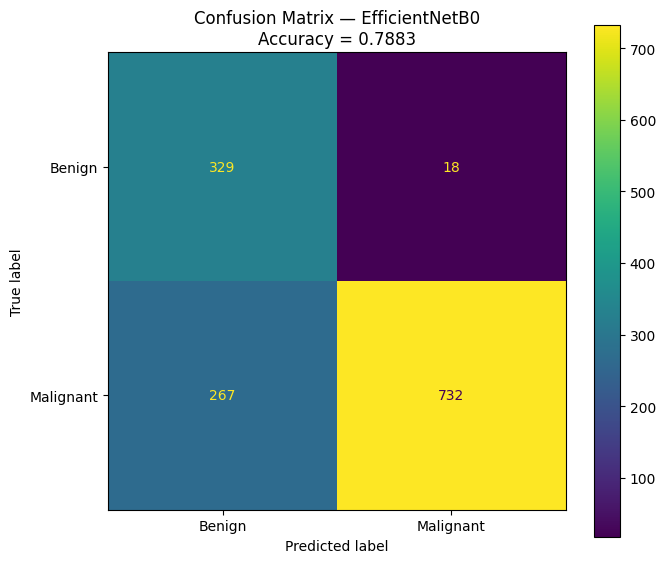


📈 2/5 — COURBE ROC
✅ Image sauvegardée : /kaggle/working/output/02_roc_curve.png


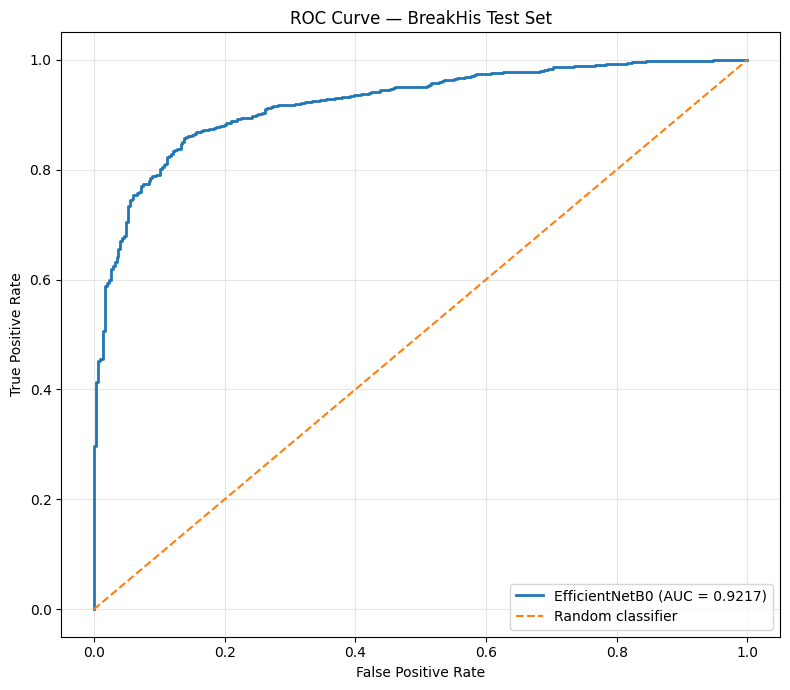


📈 3/5 — COURBE PRECISION-RECALL
✅ Image sauvegardée : /kaggle/working/output/03_precision_recall_curve.png


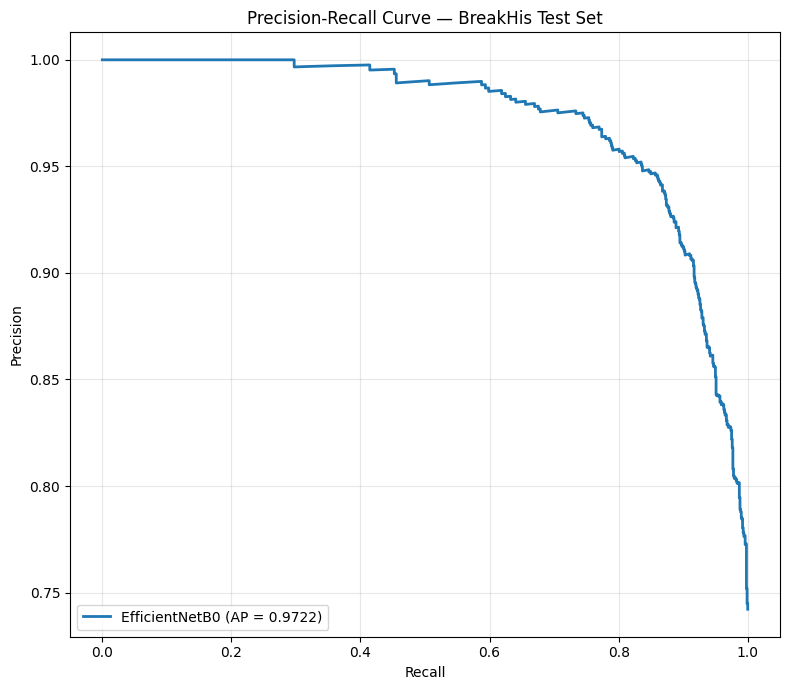


📊 4/5 — DISTRIBUTION DES PROBABILITÉS

Benign images    : 347
Malignant images : 999
✅ Image sauvegardée : /kaggle/working/output/04_probability_distribution.png


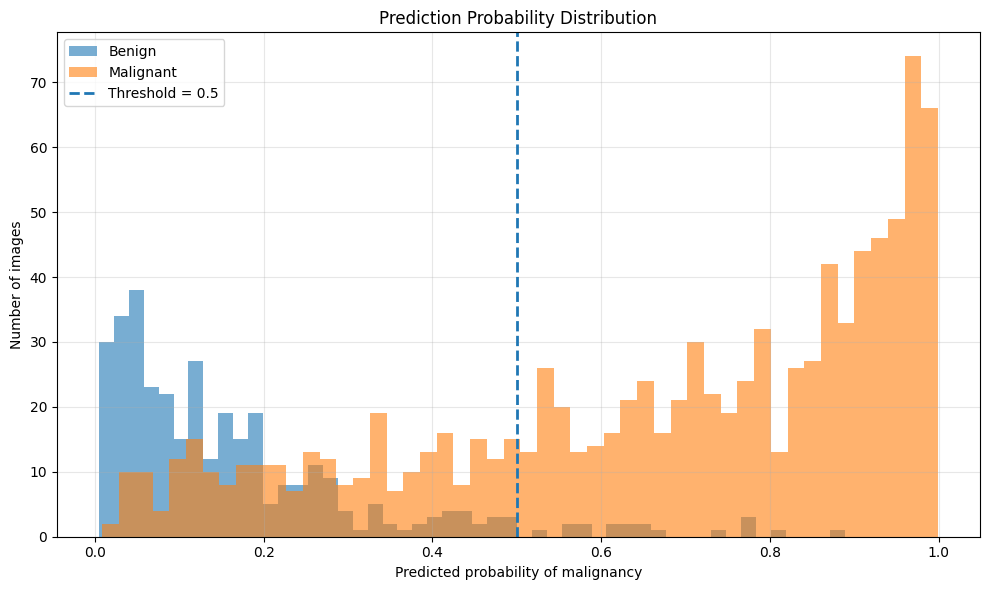


📊 5/5 — SYNTHÈSE DES MÉTRIQUES
✅ Image sauvegardée : /kaggle/working/output/05_test_metrics.png


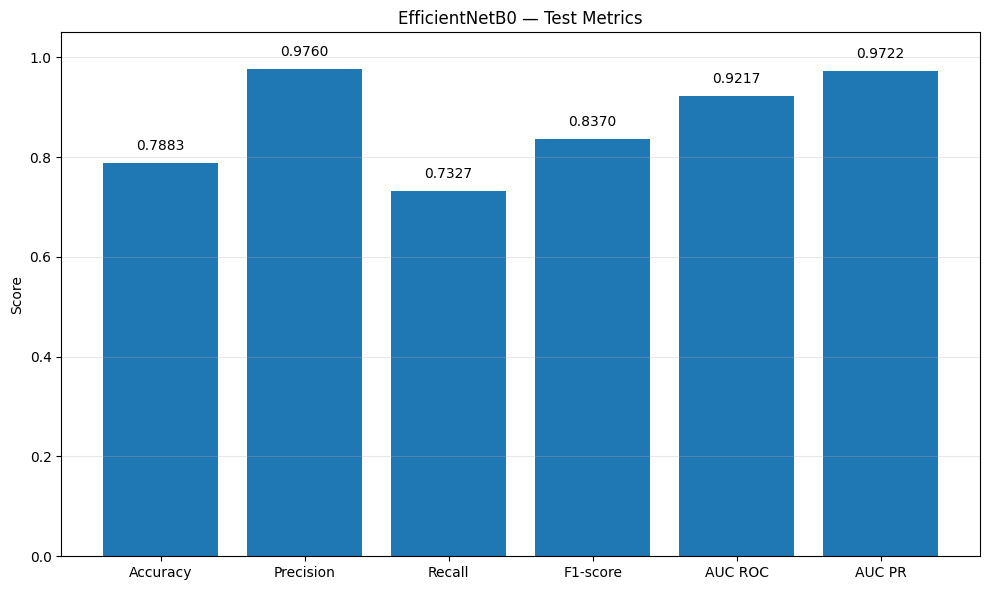


💾 Sauvegarde des métriques...
✅ Métriques sauvegardées : /kaggle/working/output/test_metrics_EfficientNetB0.csv

💾 Sauvegarde des prédictions...
✅ Prédictions sauvegardées : /kaggle/working/output/breakhis_test_predictions_EfficientNetB0.csv

🎯 CELL 12 TERMINÉE

📊 RÉSULTATS TEST

Accuracy    : 0.7883
Precision   : 0.9760
Recall      : 0.7327
F1-score    : 0.8370
AUC ROC     : 0.9217
AUC PR      : 0.9722

📁 DOSSIER OUTPUT

/kaggle/working/output

🖼️ IMAGES CRÉÉES

✓ 01_confusion_matrix.png
✓ 02_roc_curve.png
✓ 03_precision_recall_curve.png
✓ 04_probability_distribution.png
✓ 05_test_metrics.png

📄 FICHIERS CRÉÉS

✓ test_metrics_EfficientNetB0.csv
✓ breakhis_test_predictions_EfficientNetB0.csv

⏱️ Durée Cell 12 : 3.19 secondes

✅ Tous les résultats sont disponibles dans :
/kaggle/working/output


📂 CONTENU DU DOSSIER OUTPUT :
  ✓ 01_confusion_matrix.png                              102.89 KB
  ✓ 02_roc_curve.png                                     143.79 KB
  ✓ 03_precision_recall_curve

In [14]:
# =============================================================================
# 📊 CELL 12 — VISUALISATION ET SAUVEGARDE DES RÉSULTATS
# =============================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    auc
)

# =============================================================================
# 1️⃣ CONFIGURATION
# =============================================================================

print("=" * 80)
print("📊 CELL 12 — VISUALISATION DES RÉSULTATS TEST")
print("=" * 80)

START_TIME = time.time()

# Dossier de sortie
OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"\n📁 Dossier de sortie :")
print(OUTPUT_DIR)

# Vérification des variables provenant de Cell 11
required_vars = [
    "all_labels",
    "all_probs",
    "all_preds",
    "cm",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc_roc",
    "auc_pr",
    "predictions_df"
]

print("\n🔎 Vérification des variables...")

missing_vars = []

for var in required_vars:
    if var in globals():
        print(f"✓ {var}")
    else:
        print(f"❌ {var} MANQUANT")
        missing_vars.append(var)

if missing_vars:
    raise RuntimeError(
        f"\n❌ Variables manquantes : {missing_vars}\n"
        "Veuillez exécuter correctement la Cell 11 avant la Cell 12."
    )

print("\n✅ Toutes les variables nécessaires sont disponibles.")


# =============================================================================
# 2️⃣ INFORMATIONS GÉNÉRALES
# =============================================================================

all_labels = np.asarray(all_labels).astype(int)
all_probs = np.asarray(all_probs).reshape(-1)
all_preds = np.asarray(all_preds).astype(int)

print("\n" + "=" * 80)
print("📌 INFORMATIONS")
print("=" * 80)

print(f"Nombre d'images : {len(all_labels):,}")
print(f"Labels          : {len(all_labels):,}")
print(f"Probabilités    : {len(all_probs):,}")
print(f"Prédictions     : {len(all_preds):,}")

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUC ROC   : {auc_roc:.4f}")
print(f"AUC PR    : {auc_pr:.4f}")


# =============================================================================
# 3️⃣ MATRICE DE CONFUSION
# =============================================================================

print("\n" + "=" * 80)
print("🟦 1/5 — MATRICE DE CONFUSION")
print("=" * 80)

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=[0, 1]
)

print("\nMatrice :")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    f"Confusion Matrix — EfficientNetB0\n"
    f"Accuracy = {accuracy:.4f}"
)

plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR,
    "01_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"✅ Image sauvegardée : {cm_path}")

plt.show()
plt.close(fig)


# =============================================================================
# 4️⃣ COURBE ROC
# =============================================================================

print("\n" + "=" * 80)
print("📈 2/5 — COURBE ROC")
print("=" * 80)

fpr, tpr, roc_thresholds = roc_curve(
    all_labels,
    all_probs
)

roc_auc_value = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"EfficientNetB0 (AUC = {roc_auc_value:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

ax.set_title(
    "ROC Curve — BreakHis Test Set"
)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

roc_path = os.path.join(
    OUTPUT_DIR,
    "02_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"✅ Image sauvegardée : {roc_path}")

plt.show()
plt.close(fig)


# =============================================================================
# 5️⃣ COURBE PRECISION-RECALL
# =============================================================================

print("\n" + "=" * 80)
print("📈 3/5 — COURBE PRECISION-RECALL")
print("=" * 80)

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    all_labels,
    all_probs
)

pr_auc_value = auc(
    recall_curve,
    precision_curve
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"EfficientNetB0 (AP = {pr_auc_value:.4f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_title(
    "Precision-Recall Curve — BreakHis Test Set"
)

ax.legend(loc="lower left")
ax.grid(alpha=0.3)

plt.tight_layout()

pr_path = os.path.join(
    OUTPUT_DIR,
    "03_precision_recall_curve.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"✅ Image sauvegardée : {pr_path}")

plt.show()
plt.close(fig)


# =============================================================================
# 6️⃣ DISTRIBUTION DES PROBABILITÉS
# =============================================================================

print("\n" + "=" * 80)
print("📊 4/5 — DISTRIBUTION DES PROBABILITÉS")
print("=" * 80)

benign_probs = all_probs[all_labels == 0]
malignant_probs = all_probs[all_labels == 1]

print(f"\nBenign images    : {len(benign_probs):,}")
print(f"Malignant images : {len(malignant_probs):,}")

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    benign_probs,
    bins=50,
    alpha=0.6,
    label="Benign"
)

ax.hist(
    malignant_probs,
    bins=50,
    alpha=0.6,
    label="Malignant"
)

ax.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Threshold = 0.5"
)

ax.set_xlabel(
    "Predicted probability of malignancy"
)

ax.set_ylabel(
    "Number of images"
)

ax.set_title(
    "Prediction Probability Distribution"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

prob_path = os.path.join(
    OUTPUT_DIR,
    "04_probability_distribution.png"
)

plt.savefig(
    prob_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"✅ Image sauvegardée : {prob_path}")

plt.show()
plt.close(fig)


# =============================================================================
# 7️⃣ MÉTRIQUES DU MODÈLE
# =============================================================================

print("\n" + "=" * 80)
print("📊 5/5 — SYNTHÈSE DES MÉTRIQUES")
print("=" * 80)

metrics_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC ROC",
    "AUC PR"
]

metrics_values = [
    accuracy,
    precision,
    recall,
    f1,
    auc_roc,
    auc_pr
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    metrics_names,
    metrics_values
)

ax.set_ylim(0, 1.05)

ax.set_ylabel("Score")

ax.set_title(
    "EfficientNetB0 — Test Metrics"
)

ax.grid(
    axis="y",
    alpha=0.3
)

# Afficher les valeurs au-dessus des barres
for bar, value in zip(bars, metrics_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

metrics_path = os.path.join(
    OUTPUT_DIR,
    "05_test_metrics.png"
)

plt.savefig(
    metrics_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"✅ Image sauvegardée : {metrics_path}")

plt.show()
plt.close(fig)


# =============================================================================
# 8️⃣ SAUVEGARDE DES MÉTRIQUES CSV
# =============================================================================

print("\n💾 Sauvegarde des métriques...")

metrics_df = pd.DataFrame({
    "metric": metrics_names,
    "value": metrics_values
})

metrics_csv_path = os.path.join(
    OUTPUT_DIR,
    "test_metrics_EfficientNetB0.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)

print(f"✅ Métriques sauvegardées : {metrics_csv_path}")


# =============================================================================
# 9️⃣ COPIE DES PRÉDICTIONS DANS OUTPUT
# =============================================================================

print("\n💾 Sauvegarde des prédictions...")

predictions_output_path = os.path.join(
    OUTPUT_DIR,
    "breakhis_test_predictions_EfficientNetB0.csv"
)

predictions_df.to_csv(
    predictions_output_path,
    index=False
)

print(
    f"✅ Prédictions sauvegardées : "
    f"{predictions_output_path}"
)


# =============================================================================
# 🔟 RÉSUMÉ FINAL
# =============================================================================

duration = time.time() - START_TIME

print("\n" + "=" * 80)
print("🎯 CELL 12 TERMINÉE")
print("=" * 80)

print(f"""
📊 RÉSULTATS TEST

Accuracy    : {accuracy:.4f}
Precision   : {precision:.4f}
Recall      : {recall:.4f}
F1-score    : {f1:.4f}
AUC ROC     : {auc_roc:.4f}
AUC PR      : {auc_pr:.4f}

📁 DOSSIER OUTPUT

{OUTPUT_DIR}

🖼️ IMAGES CRÉÉES

✓ 01_confusion_matrix.png
✓ 02_roc_curve.png
✓ 03_precision_recall_curve.png
✓ 04_probability_distribution.png
✓ 05_test_metrics.png

📄 FICHIERS CRÉÉS

✓ test_metrics_EfficientNetB0.csv
✓ breakhis_test_predictions_EfficientNetB0.csv

⏱️ Durée Cell 12 : {duration:.2f} secondes

✅ Tous les résultats sont disponibles dans :
{OUTPUT_DIR}
""")

# Liste finale du contenu
print("\n📂 CONTENU DU DOSSIER OUTPUT :")

for filename in sorted(os.listdir(OUTPUT_DIR)):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    size_kb = os.path.getsize(filepath) / 1024

    print(
        f"  ✓ {filename:<50} "
        f"{size_kb:>8.2f} KB"
    )

print("\n" + "=" * 80)

🧪 CELL 13 — ANALYSE APPROFONDIE DES ERREURS
   EfficientNetB0 + BreakHis

📁 Dossier de sortie :
/kaggle/working/output

🔎 VÉRIFICATION DES VARIABLES
✓ all_labels
✓ all_probs
✓ all_preds
✓ predictions_df
✓ CLASS_NAMES

✅ Toutes les variables nécessaires sont disponibles.

📊 PRÉPARATION DES DONNÉES
Labels       : (1346,)
Probabilités : (1346,)
Prédictions  : (1346,)

Nombre total d'images test : 1346
Classes : ['benign', 'malignant']

📋 Analyse de predictions_df...
Lignes : 1346
Colonnes : ['filename', 'image_path', 'label', 'label_id', 'subtype', 'patient_id', 'magnification', 'split', 'true_label_id', 'true_label', 'malignant_probability', 'predicted_label_id', 'predicted_label']

🔎 Colonnes détectées :
Label       : label
Probabilité : malignant_probability
Prédiction  : predicted_label
Patient     : patient_id
Subtype     : subtype
Magnification : magnification
Filename    : filename
Image path  : image_path

🔄 Création du dataframe d'analyse...
✅ Dataframe d'analyse créé.

🧩 MATRICE

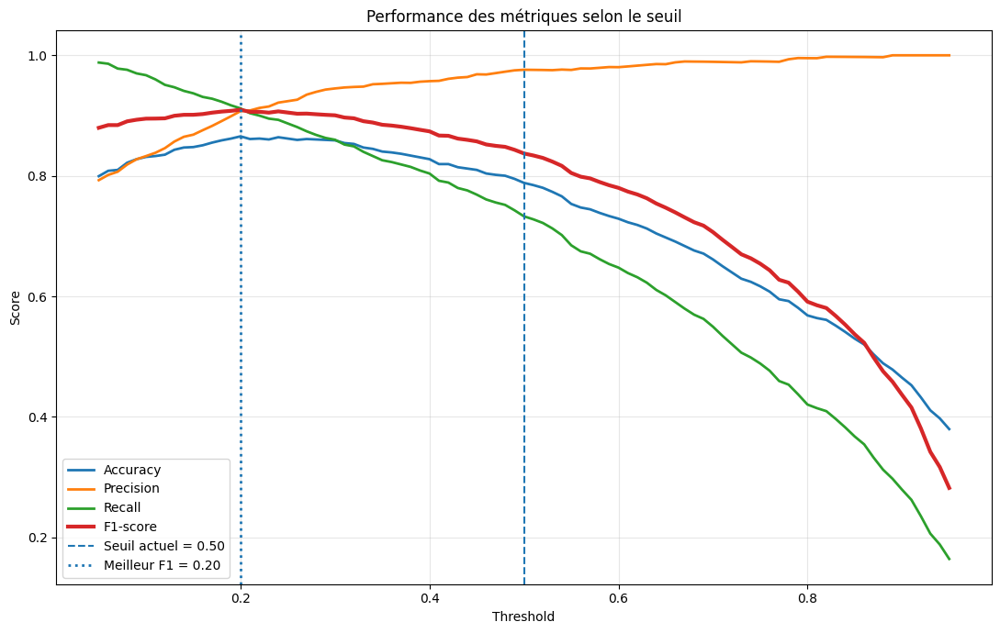

✅ Image sauvegardée : /kaggle/working/output/06_threshold_analysis.png

🧩 MATRICE DE CONFUSION — SEUIL F1 0.20

                 Prédit benign   Prédit malignant
Réel benign           254                93
Réel malignant         88               911

Accuracy  : 0.8655
Precision : 0.9074
Recall    : 0.9119
F1-score  : 0.9096


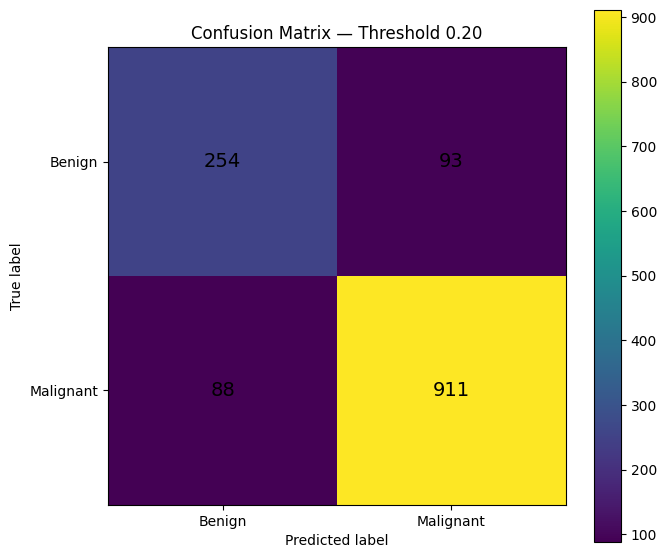

✅ Image sauvegardée : /kaggle/working/output/07_confusion_matrix_optimal_threshold.png

❌ ANALYSE DES ERREURS

Images correctement classées : 1061
Faux positifs : 18
Faux négatifs : 267

⚠️ Faux négatifs malignant : 267
Ce sont les images malignant prédites benign.

✅ Faux positifs sauvegardés : /kaggle/working/output/false_positives.csv
✅ Faux négatifs sauvegardés : /kaggle/working/output/false_negatives.csv

🚨 TOP FAUX NÉGATIFS
                     filename patient_id subtype magnification true_label_name predicted_label_name  prob_malignant  error_type_05
SOB_M_MC-14-16456-100-055.png   14-16456      MC          100X       malignant               benign        0.008926 False Negative
 SOB_M_PC-14-9146-200-021.png    14-9146      PC          200X       malignant               benign        0.016910 False Negative
SOB_M_MC-14-16456-400-044.png   14-16456      MC          400X       malignant               benign        0.033630 False Negative
 SOB_M_PC-14-9146-200-015.png    14-9146  

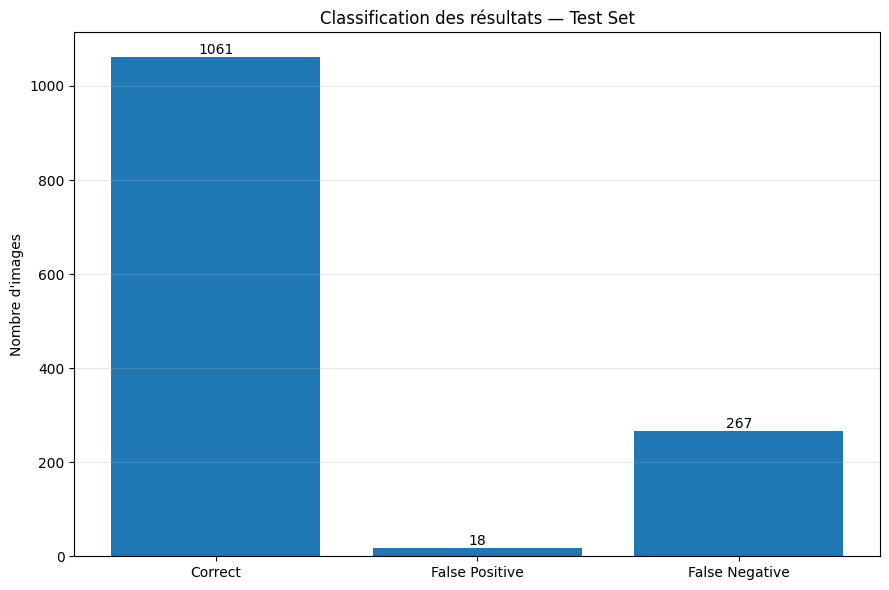

✅ Image sauvegardée : /kaggle/working/output/12_error_distribution.png

📈 Création de la courbe ROC avec seuil optimal...


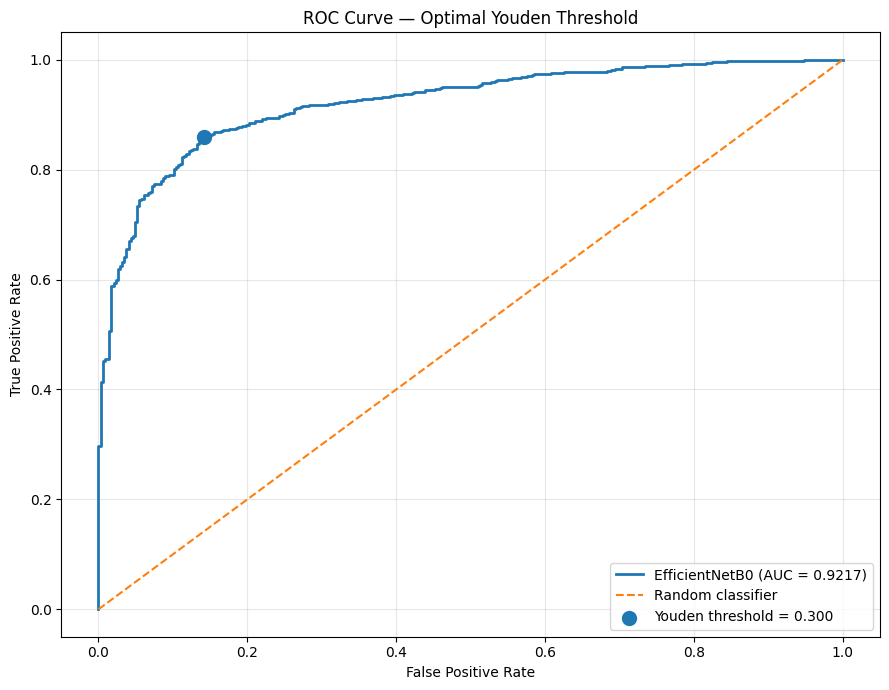

✅ Image sauvegardée : /kaggle/working/output/13_roc_optimal_threshold.png

💾 SAUVEGARDE DES ANALYSES
✓ Threshold analysis : /kaggle/working/output/threshold_analysis.csv

🏁 CELL 13 TERMINÉE

🎯 RÉSULTATS ACTUELS — SEUIL 0.50
Accuracy    : 0.7883
Precision   : 0.9760
Recall      : 0.7327
F1-score    : 0.8370
AUC ROC     : 0.9217
AUC PR      : 0.9722

🎯 SEUILS OPTIMAUX
Meilleur seuil F1     : 0.20
Meilleur F1           : 0.9096
Meilleur seuil Youden : 0.30
Youden J              : 0.7158

🚨 ERREURS
False Positives : 18
False Negatives : 267
True Negatives  : 329
True Positives  : 732

⏱️ Durée Cell 13 : 3.07 secondes

📁 Fichiers principaux créés :
✓ 06_threshold_analysis.png                       178.79 KB
✓ 07_confusion_matrix_optimal_threshold.png        61.52 KB
✓ 08_metrics_by_subtype.csv                         0.33 KB
✓ 09_metrics_by_magnification.csv                   0.46 KB
✓ 10_patient_level_analysis.csv                     1.11 KB
✓ 11_patients_with_false_negatives.csv          

In [15]:
# =============================================================================
# 🧪 CELL 13 — ANALYSE APPROFONDIE DES ERREURS
# EfficientNetB0 + BreakHis
# =============================================================================

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
)

warnings.filterwarnings("ignore")

# =============================================================================
# ⏱️ CHRONOMÈTRE
# =============================================================================

CELL13_START = time.time()

# =============================================================================
# 📁 DOSSIER OUTPUT
# =============================================================================

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 80)
print("🧪 CELL 13 — ANALYSE APPROFONDIE DES ERREURS")
print("   EfficientNetB0 + BreakHis")
print("=" * 80)

print("\n📁 Dossier de sortie :")
print(OUTPUT_DIR)

# =============================================================================
# 🔎 VÉRIFICATION DES VARIABLES
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES VARIABLES")
print("=" * 80)

required_variables = [
    "all_labels",
    "all_probs",
    "all_preds",
    "predictions_df",
    "CLASS_NAMES",
]

missing_variables = []

for var_name in required_variables:
    if var_name in globals():
        print(f"✓ {var_name}")
    else:
        print(f"❌ {var_name} MANQUANTE")
        missing_variables.append(var_name)

if missing_variables:
    raise RuntimeError(
        "Variables manquantes : " + ", ".join(missing_variables)
    )

print("\n✅ Toutes les variables nécessaires sont disponibles.")

# =============================================================================
# 📊 CONVERSION DES DONNÉES
# =============================================================================

print("\n" + "=" * 80)
print("📊 PRÉPARATION DES DONNÉES")
print("=" * 80)

all_labels = np.asarray(all_labels).astype(int).reshape(-1)
all_probs = np.asarray(all_probs).astype(float).reshape(-1)
all_preds = np.asarray(all_preds).astype(int).reshape(-1)

print(f"Labels       : {all_labels.shape}")
print(f"Probabilités : {all_probs.shape}")
print(f"Prédictions  : {all_preds.shape}")

if not (
    len(all_labels)
    == len(all_probs)
    == len(all_preds)
):
    raise ValueError(
        "❌ Les longueurs de labels, probabilités et prédictions "
        "ne correspondent pas."
    )

N_TEST = len(all_labels)

print(f"\nNombre total d'images test : {N_TEST}")

print(f"Classes : {CLASS_NAMES}")

# =============================================================================
# 🧹 NETTOYAGE / COPIE DU DATAFRAME
# =============================================================================

print("\n📋 Analyse de predictions_df...")

pred_df = predictions_df.copy()

print(f"Lignes : {len(pred_df)}")
print(f"Colonnes : {list(pred_df.columns)}")

# =============================================================================
# 🔍 DÉTECTION AUTOMATIQUE DES COLONNES
# =============================================================================

def find_column(df, candidates):
    """
    Trouve automatiquement une colonne parmi plusieurs noms possibles.
    """
    lower_map = {str(c).lower(): c for c in df.columns}

    # Recherche exacte
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    # Recherche partielle
    for candidate in candidates:
        candidate_lower = candidate.lower()
        for col in df.columns:
            if candidate_lower in str(col).lower():
                return col

    return None


LABEL_COL = find_column(
    pred_df,
    [
        "label",
        "true_label",
        "true",
        "target",
        "y_true",
        "label_id",
    ],
)

PROB_COL = find_column(
    pred_df,
    [
        "probability",
        "prob",
        "prob_malignant",
        "malignancy_probability",
        "predicted_probability",
        "prediction_probability",
        "score",
    ],
)

PRED_COL = find_column(
    pred_df,
    [
        "predicted_label",
        "prediction",
        "pred",
        "y_pred",
        "predicted",
    ],
)

PATIENT_COL = find_column(
    pred_df,
    [
        "patient_id",
        "patient",
        "patientid",
    ],
)

SUBTYPE_COL = find_column(
    pred_df,
    [
        "subtype",
        "type",
    ],
)

MAG_COL = find_column(
    pred_df,
    [
        "magnification",
        "magnification_level",
        "mag",
    ],
)

FILENAME_COL = find_column(
    pred_df,
    [
        "filename",
        "file_name",
        "image",
        "image_name",
    ],
)

IMAGE_PATH_COL = find_column(
    pred_df,
    [
        "image_path",
        "path",
        "filepath",
        "file_path",
    ],
)

print("\n🔎 Colonnes détectées :")

print(f"Label       : {LABEL_COL}")
print(f"Probabilité : {PROB_COL}")
print(f"Prédiction  : {PRED_COL}")
print(f"Patient     : {PATIENT_COL}")
print(f"Subtype     : {SUBTYPE_COL}")
print(f"Magnification : {MAG_COL}")
print(f"Filename    : {FILENAME_COL}")
print(f"Image path  : {IMAGE_PATH_COL}")

# =============================================================================
# ⚠️ SI LES COLONNES NE SONT PAS TROUVÉES
# =============================================================================

if LABEL_COL is None:
    print(
        "\n⚠️ Colonne label non trouvée dans predictions_df."
    )
    print(
        "➡️ Utilisation de all_labels."
    )

if PROB_COL is None:
    print(
        "\n⚠️ Colonne probabilité non trouvée."
    )
    print(
        "➡️ Utilisation de all_probs."
    )

# =============================================================================
# 🔄 CRÉATION D'UN DATAFRAME D'ANALYSE STANDARDISÉ
# =============================================================================

print("\n🔄 Création du dataframe d'analyse...")

analysis_df = pred_df.copy()

# On force l'alignement avec les résultats de Cell 11.
analysis_df["true_label_id"] = all_labels
analysis_df["prob_malignant"] = all_probs
analysis_df["predicted_label_id"] = all_preds

analysis_df["true_label_name"] = analysis_df["true_label_id"].map(
    {
        0: "benign",
        1: "malignant",
    }
)

analysis_df["predicted_label_name"] = analysis_df[
    "predicted_label_id"
].map(
    {
        0: "benign",
        1: "malignant",
    }
)

analysis_df["correct"] = (
    analysis_df["true_label_id"]
    == analysis_df["predicted_label_id"]
)

analysis_df["error"] = ~analysis_df["correct"]

analysis_df["error_type"] = "Correct"

analysis_df.loc[
    (analysis_df["true_label_id"] == 0)
    & (analysis_df["predicted_label_id"] == 1),
    "error_type",
] = "False Positive"

analysis_df.loc[
    (analysis_df["true_label_id"] == 1)
    & (analysis_df["predicted_label_id"] == 0),
    "error_type",
] = "False Negative"

print("✅ Dataframe d'analyse créé.")

# =============================================================================
# 📊 MATRICE DE CONFUSION ACTUELLE
# =============================================================================

print("\n" + "=" * 80)
print("🧩 MATRICE DE CONFUSION — SEUIL 0.5")
print("=" * 80)

cm_05 = confusion_matrix(
    all_labels,
    all_preds,
    labels=[0, 1],
)

print("\n                 Prédit benign   Prédit malignant")
print(
    f"Réel benign          {cm_05[0,0]:4d}              {cm_05[0,1]:4d}"
)
print(
    f"Réel malignant       {cm_05[1,0]:4d}              {cm_05[1,1]:4d}"
)

tn, fp, fn, tp = cm_05.ravel()

print("\nTN :", tn)
print("FP :", fp)
print("FN :", fn)
print("TP :", tp)

# =============================================================================
# 🎯 RECHERCHE DU SEUIL OPTIMAL
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RECHERCHE DU SEUIL OPTIMAL")
print("=" * 80)

thresholds = np.arange(
    0.05,
    0.951,
    0.01
)

threshold_results = []

for threshold in thresholds:

    preds_threshold = (
        all_probs >= threshold
    ).astype(int)

    acc = accuracy_score(
        all_labels,
        preds_threshold
    )

    prec = precision_score(
        all_labels,
        preds_threshold,
        zero_division=0
    )

    rec = recall_score(
        all_labels,
        preds_threshold,
        zero_division=0
    )

    f1_value = f1_score(
        all_labels,
        preds_threshold,
        zero_division=0
    )

    cm_temp = confusion_matrix(
        all_labels,
        preds_threshold,
        labels=[0, 1]
    )

    tn_t, fp_t, fn_t, tp_t = cm_temp.ravel()

    sensitivity = (
        tp_t / (tp_t + fn_t)
        if (tp_t + fn_t) > 0
        else 0
    )

    specificity = (
        tn_t / (tn_t + fp_t)
        if (tn_t + fp_t) > 0
        else 0
    )

    youden_j = (
        sensitivity + specificity - 1
    )

    threshold_results.append(
        {
            "threshold": threshold,
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1_score": f1_value,
            "sensitivity": sensitivity,
            "specificity": specificity,
            "youden_j": youden_j,
            "tn": tn_t,
            "fp": fp_t,
            "fn": fn_t,
            "tp": tp_t,
        }
    )

threshold_df = pd.DataFrame(
    threshold_results
)

# =============================================================================
# 🥇 MEILLEUR SEUIL F1
# =============================================================================

best_f1_row = threshold_df.loc[
    threshold_df["f1_score"].idxmax()
]

BEST_THRESHOLD_F1 = float(
    best_f1_row["threshold"]
)

BEST_F1 = float(
    best_f1_row["f1_score"]
)

# =============================================================================
# 🥇 MEILLEUR SEUIL YOUDEN
# =============================================================================

best_youden_row = threshold_df.loc[
    threshold_df["youden_j"].idxmax()
]

BEST_THRESHOLD_YOUDEN = float(
    best_youden_row["threshold"]
)

BEST_YOUDEN = float(
    best_youden_row["youden_j"]
)

print(
    f"\n🥇 Meilleur seuil selon F1 : "
    f"{BEST_THRESHOLD_F1:.2f}"
)

print(
    f"F1 correspondant : "
    f"{BEST_F1:.4f}"
)

print(
    f"\n🥇 Meilleur seuil selon Youden J : "
    f"{BEST_THRESHOLD_YOUDEN:.2f}"
)

print(
    f"Youden J : "
    f"{BEST_YOUDEN:.4f}"
)

# =============================================================================
# 📊 COMPARAISON DES SEUILS
# =============================================================================

print("\n" + "=" * 80)
print("📊 COMPARAISON DES SEUILS")
print("=" * 80)

selected_thresholds = [
    0.30,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    BEST_THRESHOLD_F1,
    BEST_THRESHOLD_YOUDEN,
]

selected_thresholds = sorted(
    set(
        round(float(x), 2)
        for x in selected_thresholds
        if 0.05 <= float(x) <= 0.95
    )
)

comparison_df = threshold_df[
    threshold_df["threshold"].round(2).isin(
        selected_thresholds
    )
].copy()

print(
    comparison_df[
        [
            "threshold",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "sensitivity",
            "specificity",
            "youden_j",
        ]
    ].round(4).to_string(
        index=False
    )
)

# =============================================================================
# 📈 GRAPHIQUE PERFORMANCE VS SEUIL
# =============================================================================

print("\n📈 Création du graphique des seuils...")

plt.figure(figsize=(11, 7))

plt.plot(
    threshold_df["threshold"],
    threshold_df["accuracy"],
    label="Accuracy",
    linewidth=2
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision",
    linewidth=2
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall",
    linewidth=2
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    label="F1-score",
    linewidth=3
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Seuil actuel = 0.50"
)

plt.axvline(
    BEST_THRESHOLD_F1,
    linestyle=":",
    linewidth=2,
    label=f"Meilleur F1 = {BEST_THRESHOLD_F1:.2f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")

plt.title(
    "Performance des métriques selon le seuil"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

THRESHOLD_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "06_threshold_analysis.png"
)

plt.savefig(
    THRESHOLD_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Image sauvegardée : "
    f"{THRESHOLD_PLOT_PATH}"
)

# =============================================================================
# 🧩 MATRICE DE CONFUSION AU MEILLEUR SEUIL F1
# =============================================================================

print("\n" + "=" * 80)
print(
    f"🧩 MATRICE DE CONFUSION — SEUIL F1 "
    f"{BEST_THRESHOLD_F1:.2f}"
)
print("=" * 80)

preds_best_f1 = (
    all_probs >= BEST_THRESHOLD_F1
).astype(int)

cm_best = confusion_matrix(
    all_labels,
    preds_best_f1,
    labels=[0, 1]
)

print("\n                 Prédit benign   Prédit malignant")
print(
    f"Réel benign          {cm_best[0,0]:4d}              {cm_best[0,1]:4d}"
)
print(
    f"Réel malignant       {cm_best[1,0]:4d}              {cm_best[1,1]:4d}"
)

tn_b, fp_b, fn_b, tp_b = cm_best.ravel()

best_acc = accuracy_score(
    all_labels,
    preds_best_f1
)

best_prec = precision_score(
    all_labels,
    preds_best_f1,
    zero_division=0
)

best_rec = recall_score(
    all_labels,
    preds_best_f1,
    zero_division=0
)

best_f1_final = f1_score(
    all_labels,
    preds_best_f1,
    zero_division=0
)

print("\nAccuracy  :", f"{best_acc:.4f}")
print("Precision :", f"{best_prec:.4f}")
print("Recall    :", f"{best_rec:.4f}")
print("F1-score  :", f"{best_f1_final:.4f}")

# =============================================================================
# 📊 GRAPHIQUE MATRICE DE CONFUSION
# =============================================================================

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_best,
    interpolation="nearest"
)

plt.title(
    f"Confusion Matrix — Threshold {BEST_THRESHOLD_F1:.2f}"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["Benign", "Malignant"]
)

plt.yticks(
    [0, 1],
    ["Benign", "Malignant"]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm_best[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

BEST_CM_PATH = os.path.join(
    OUTPUT_DIR,
    "07_confusion_matrix_optimal_threshold.png"
)

plt.savefig(
    BEST_CM_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Image sauvegardée : {BEST_CM_PATH}"
)

# =============================================================================
# ❌ ANALYSE DES ERREURS
# =============================================================================

print("\n" + "=" * 80)
print("❌ ANALYSE DES ERREURS")
print("=" * 80)

# Utilisation du seuil actuel 0.5
analysis_df["predicted_05"] = (
    all_probs >= 0.5
).astype(int)

analysis_df["error_type_05"] = "Correct"

analysis_df.loc[
    (all_labels == 0)
    & (analysis_df["predicted_05"] == 1),
    "error_type_05"
] = "False Positive"

analysis_df.loc[
    (all_labels == 1)
    & (analysis_df["predicted_05"] == 0),
    "error_type_05"
] = "False Negative"

fp_df = analysis_df[
    analysis_df["error_type_05"]
    == "False Positive"
].copy()

fn_df = analysis_df[
    analysis_df["error_type_05"]
    == "False Negative"
].copy()

correct_df = analysis_df[
    analysis_df["error_type_05"]
    == "Correct"
].copy()

print(
    f"\nImages correctement classées : "
    f"{len(correct_df)}"
)

print(
    f"Faux positifs : "
    f"{len(fp_df)}"
)

print(
    f"Faux négatifs : "
    f"{len(fn_df)}"
)

print(
    "\n⚠️ Faux négatifs malignant : "
    f"{len(fn_df)}"
)

print(
    "Ce sont les images malignant "
    "prédites benign."
)

# =============================================================================
# 📁 SAUVEGARDE DES ERREURS
# =============================================================================

FP_PATH = os.path.join(
    OUTPUT_DIR,
    "false_positives.csv"
)

FN_PATH = os.path.join(
    OUTPUT_DIR,
    "false_negatives.csv"
)

fp_df.to_csv(
    FP_PATH,
    index=False
)

fn_df.to_csv(
    FN_PATH,
    index=False
)

print(
    f"\n✅ Faux positifs sauvegardés : {FP_PATH}"
)

print(
    f"✅ Faux négatifs sauvegardés : {FN_PATH}"
)

# =============================================================================
# 🚨 TOP FAUX NÉGATIFS LES PLUS DANGEREUX
# =============================================================================

print("\n" + "=" * 80)
print("🚨 TOP FAUX NÉGATIFS")
print("=" * 80)

if len(fn_df) > 0:

    # Les plus dangereux sont ceux avec la plus faible
    # probabilité de malignité.
    top_fn = fn_df.sort_values(
        "prob_malignant",
        ascending=True
    ).head(20)

    display_columns = [
        c
        for c in [
            FILENAME_COL,
            PATIENT_COL,
            SUBTYPE_COL,
            MAG_COL,
            "true_label_name",
            "predicted_label_name",
            "prob_malignant",
            "error_type_05",
        ]
        if c is not None and c in top_fn.columns
    ]

    print(
        top_fn[
            display_columns
        ].to_string(index=False)
    )

    TOP_FN_PATH = os.path.join(
        OUTPUT_DIR,
        "top_20_false_negatives.csv"
    )

    top_fn.to_csv(
        TOP_FN_PATH,
        index=False
    )

    print(
        f"\n✅ Top faux négatifs sauvegardés : "
        f"{TOP_FN_PATH}"
    )

else:

    print(
        "🎉 Aucun faux négatif au seuil 0.5."
    )

# =============================================================================
# 🤔 IMAGES INCERTAINES
# =============================================================================

print("\n" + "=" * 80)
print("🤔 ANALYSE DES IMAGES INCERTAINES")
print("=" * 80)

analysis_df["uncertainty"] = np.abs(
    analysis_df["prob_malignant"] - 0.5
)

uncertain_df = analysis_df.sort_values(
    "uncertainty",
    ascending=True
).head(50)

display_columns = [
    c
    for c in [
        FILENAME_COL,
        PATIENT_COL,
        SUBTYPE_COL,
        MAG_COL,
        "true_label_name",
        "predicted_label_name",
        "prob_malignant",
        "uncertainty",
    ]
    if c is not None and c in uncertain_df.columns
]

print(
    uncertain_df[
        display_columns
    ].to_string(index=False)
)

UNCERTAIN_PATH = os.path.join(
    OUTPUT_DIR,
    "top_50_uncertain_images.csv"
)

uncertain_df.to_csv(
    UNCERTAIN_PATH,
    index=False
)

print(
    f"\n✅ Images incertaines sauvegardées : "
    f"{UNCERTAIN_PATH}"
)

# =============================================================================
# 🔬 ANALYSE PAR SUBTYPE
# =============================================================================

if SUBTYPE_COL is not None:

    print("\n" + "=" * 80)
    print("🔬 ANALYSE PAR SUBTYPE")
    print("=" * 80)

    subtype_rows = []

    for subtype, group in analysis_df.groupby(
        SUBTYPE_COL,
        dropna=False
    ):

        y_true_sub = group["true_label_id"].values
        y_prob_sub = group["prob_malignant"].values
        y_pred_sub = (
            y_prob_sub >= 0.5
        ).astype(int)

        row = {
            "subtype": subtype,
            "images": len(group),
            "accuracy": accuracy_score(
                y_true_sub,
                y_pred_sub
            ),
            "precision": precision_score(
                y_true_sub,
                y_pred_sub,
                zero_division=0
            ),
            "recall": recall_score(
                y_true_sub,
                y_pred_sub,
                zero_division=0
            ),
            "f1": f1_score(
                y_true_sub,
                y_pred_sub,
                zero_division=0
            ),
        }

        try:
            row["auc_roc"] = roc_auc_score(
                y_true_sub,
                y_prob_sub
            )
        except:
            row["auc_roc"] = np.nan

        subtype_rows.append(row)

    subtype_df = pd.DataFrame(
        subtype_rows
    )

    print(
        subtype_df.round(4).to_string(
            index=False
        )
    )

    SUBTYPE_PATH = os.path.join(
        OUTPUT_DIR,
        "08_metrics_by_subtype.csv"
    )

    subtype_df.to_csv(
        SUBTYPE_PATH,
        index=False
    )

    print(
        f"\n✅ Analyse subtype sauvegardée : "
        f"{SUBTYPE_PATH}"
    )

# =============================================================================
# 🔍 ANALYSE PAR MAGNIFICATION
# =============================================================================

if MAG_COL is not None:

    print("\n" + "=" * 80)
    print("🔍 ANALYSE PAR MAGNIFICATION")
    print("=" * 80)

    magnification_rows = []

    for magnification, group in analysis_df.groupby(
        MAG_COL,
        dropna=False
    ):

        y_true_mag = group[
            "true_label_id"
        ].values

        y_prob_mag = group[
            "prob_malignant"
        ].values

        y_pred_mag = (
            y_prob_mag >= 0.5
        ).astype(int)

        row = {
            "magnification": magnification,
            "images": len(group),
            "accuracy": accuracy_score(
                y_true_mag,
                y_pred_mag
            ),
            "precision": precision_score(
                y_true_mag,
                y_pred_mag,
                zero_division=0
            ),
            "recall": recall_score(
                y_true_mag,
                y_pred_mag,
                zero_division=0
            ),
            "f1": f1_score(
                y_true_mag,
                y_pred_mag,
                zero_division=0
            ),
        }

        try:
            row["auc_roc"] = roc_auc_score(
                y_true_mag,
                y_prob_mag
            )
        except:
            row["auc_roc"] = np.nan

        magnification_rows.append(row)

    magnification_df = pd.DataFrame(
        magnification_rows
    )

    print(
        magnification_df.round(4).to_string(
            index=False
        )
    )

    MAG_PATH = os.path.join(
        OUTPUT_DIR,
        "09_metrics_by_magnification.csv"
    )

    magnification_df.to_csv(
        MAG_PATH,
        index=False
    )

    print(
        f"\n✅ Analyse magnification sauvegardée : "
        f"{MAG_PATH}"
    )

# =============================================================================
# 👤 ANALYSE PAR PATIENT
# =============================================================================

if PATIENT_COL is not None:

    print("\n" + "=" * 80)
    print("👤 ANALYSE PAR PATIENT")
    print("=" * 80)

    patient_rows = []

    for patient_id, group in analysis_df.groupby(
        PATIENT_COL,
        dropna=False
    ):

        patient_labels = group[
            "true_label_id"
        ].values

        patient_probs = group[
            "prob_malignant"
        ].values

        patient_preds = (
            patient_probs >= 0.5
        ).astype(int)

        # Label réel du patient
        true_patient_label = int(
            round(
                np.mean(patient_labels)
            )
        )

        # Probabilité moyenne
        mean_prob = float(
            np.mean(patient_probs)
        )

        # Probabilité maximale
        max_prob = float(
            np.max(patient_probs)
        )

        patient_pred_mean = int(
            mean_prob >= 0.5
        )

        patient_pred_max = int(
            max_prob >= 0.5
        )

        patient_rows.append(
            {
                "patient_id": patient_id,
                "images": len(group),
                "true_label": true_patient_label,
                "mean_probability": mean_prob,
                "max_probability": max_prob,
                "pred_mean_probability": patient_pred_mean,
                "pred_max_probability": patient_pred_max,
                "image_accuracy": accuracy_score(
                    patient_labels,
                    patient_preds
                ),
                "false_negatives": int(
                    np.sum(
                        (patient_labels == 1)
                        & (patient_preds == 0)
                    )
                ),
            }
        )

    patient_df = pd.DataFrame(
        patient_rows
    )

    print(
        f"\nNombre de patients test : "
        f"{len(patient_df)}"
    )

    patient_accuracy_mean = accuracy_score(
        patient_df["true_label"],
        patient_df["pred_mean_probability"]
    )

    patient_accuracy_max = accuracy_score(
        patient_df["true_label"],
        patient_df["pred_max_probability"]
    )

    print(
        "\nAccuracy patient — moyenne probabilité : "
        f"{patient_accuracy_mean:.4f}"
    )

    print(
        "Accuracy patient — maximum probabilité : "
        f"{patient_accuracy_max:.4f}"
    )

    PATIENT_PATH = os.path.join(
        OUTPUT_DIR,
        "10_patient_level_analysis.csv"
    )

    patient_df.to_csv(
        PATIENT_PATH,
        index=False
    )

    print(
        f"\n✅ Analyse patient sauvegardée : "
        f"{PATIENT_PATH}"
    )

    # Patients contenant des faux négatifs
    problematic_patients = patient_df[
        patient_df["false_negatives"] > 0
    ].sort_values(
        "false_negatives",
        ascending=False
    )

    PROBLEM_PATIENT_PATH = os.path.join(
        OUTPUT_DIR,
        "11_patients_with_false_negatives.csv"
    )

    problematic_patients.to_csv(
        PROBLEM_PATIENT_PATH,
        index=False
    )

    print(
        f"⚠️ Patients avec faux négatifs : "
        f"{len(problematic_patients)}"
    )

    print(
        f"✅ Liste sauvegardée : "
        f"{PROBLEM_PATIENT_PATH}"
    )

# =============================================================================
# 📊 GRAPHIQUE ERREURS
# =============================================================================

print("\n" + "=" * 80)
print("📊 VISUALISATION DES ERREURS")
print("=" * 80)

error_counts = analysis_df[
    "error_type_05"
].value_counts()

labels_plot = [
    "Correct",
    "False Positive",
    "False Negative",
]

values_plot = [
    int(error_counts.get("Correct", 0)),
    int(error_counts.get("False Positive", 0)),
    int(error_counts.get("False Negative", 0)),
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    labels_plot,
    values_plot
)

plt.title(
    "Classification des résultats — Test Set"
)

plt.ylabel(
    "Nombre d'images"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    values_plot
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value,
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

ERROR_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "12_error_distribution.png"
)

plt.savefig(
    ERROR_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Image sauvegardée : "
    f"{ERROR_PLOT_PATH}"
)

# =============================================================================
# 📈 COURBE ROC + SEUIL OPTIMAL
# =============================================================================

print("\n📈 Création de la courbe ROC avec seuil optimal...")

fpr, tpr, roc_thresholds = roc_curve(
    all_labels,
    all_probs
)

youden_values = (
    tpr - fpr
)

best_roc_index = np.argmax(
    youden_values
)

best_roc_threshold = (
    roc_thresholds[best_roc_index]
)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"EfficientNetB0 (AUC = {auc_roc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.scatter(
    fpr[best_roc_index],
    tpr[best_roc_index],
    s=100,
    label=f"Youden threshold = {best_roc_threshold:.3f}"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve — Optimal Youden Threshold"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

ROC_OPT_PATH = os.path.join(
    OUTPUT_DIR,
    "13_roc_optimal_threshold.png"
)

plt.savefig(
    ROC_OPT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Image sauvegardée : {ROC_OPT_PATH}"
)

# =============================================================================
# 💾 SAUVEGARDE DES RÉSULTATS DU SEUIL
# =============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE DES ANALYSES")
print("=" * 80)

THRESHOLD_PATH = os.path.join(
    OUTPUT_DIR,
    "threshold_analysis.csv"
)

threshold_df.to_csv(
    THRESHOLD_PATH,
    index=False
)

print(
    f"✓ Threshold analysis : {THRESHOLD_PATH}"
)

# =============================================================================
# 📄 RÉSUMÉ FINAL
# =============================================================================

CELL13_DURATION = (
    time.time() - CELL13_START
)

print("\n" + "=" * 80)
print("🏁 CELL 13 TERMINÉE")
print("=" * 80)

print("\n🎯 RÉSULTATS ACTUELS — SEUIL 0.50")

print(
    f"Accuracy    : {accuracy_score(all_labels, all_preds):.4f}"
)

print(
    f"Precision   : {precision_score(all_labels, all_preds, zero_division=0):.4f}"
)

print(
    f"Recall      : {recall_score(all_labels, all_preds, zero_division=0):.4f}"
)

print(
    f"F1-score    : {f1_score(all_labels, all_preds, zero_division=0):.4f}"
)

print(
    f"AUC ROC     : {auc_roc:.4f}"
)

print(
    f"AUC PR      : {auc_pr:.4f}"
)

print("\n🎯 SEUILS OPTIMAUX")

print(
    f"Meilleur seuil F1     : {BEST_THRESHOLD_F1:.2f}"
)

print(
    f"Meilleur F1           : {BEST_F1:.4f}"
)

print(
    f"Meilleur seuil Youden : {BEST_THRESHOLD_YOUDEN:.2f}"
)

print(
    f"Youden J              : {BEST_YOUDEN:.4f}"
)

print("\n🚨 ERREURS")

print(
    f"False Positives : {fp}"
)

print(
    f"False Negatives : {fn}"
)

print(
    f"True Negatives  : {tn}"
)

print(
    f"True Positives  : {tp}"
)

print(
    f"\n⏱️ Durée Cell 13 : "
    f"{CELL13_DURATION:.2f} secondes"
)

print("\n📁 Fichiers principaux créés :")

files_created = [
    "06_threshold_analysis.png",
    "07_confusion_matrix_optimal_threshold.png",
    "08_metrics_by_subtype.csv",
    "09_metrics_by_magnification.csv",
    "10_patient_level_analysis.csv",
    "11_patients_with_false_negatives.csv",
    "12_error_distribution.png",
    "13_roc_optimal_threshold.png",
    "false_positives.csv",
    "false_negatives.csv",
    "top_20_false_negatives.csv",
    "top_50_uncertain_images.csv",
    "threshold_analysis.csv",
]

for filename in files_created:

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.exists(filepath):

        size_kb = (
            os.path.getsize(filepath)
            / 1024
        )

        print(
            f"✓ {filename:<45} "
            f"{size_kb:8.2f} KB"
        )

print("\n" + "=" * 80)
print("✅ ANALYSE DES ERREURS TERMINÉE")
print("=" * 80)

In [16]:
# =============================================================================
# 🧪 CELL 14 — EXPLAINABILITY GRAD-CAM
#    EfficientNetB0 + BreakHis
#    Version compatible TensorFlow 2.20 / Keras 3
# =============================================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from tensorflow import keras


CELL_START = time.time()

print("=" * 80)
print("🧪 CELL 14 — EXPLAINABILITY GRAD-CAM")
print("   EfficientNetB0 + BreakHis")
print("=" * 80)

# =============================================================================
# 1. DOSSIERS
# =============================================================================

OUTPUT_DIR = "/kaggle/working/output"
GRADCAM_DIR = os.path.join(OUTPUT_DIR, "gradcam")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(GRADCAM_DIR, exist_ok=True)

print(f"\n📁 Dossier output : {OUTPUT_DIR}")
print(f"📁 Dossier Grad-CAM : {GRADCAM_DIR}")


# =============================================================================
# 2. VERIFICATION DES VARIABLES
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES VARIABLES")
print("=" * 80)

required_variables = [
    "eval_model",
    "all_labels",
    "all_probs",
    "all_preds",
    "predictions_df",
    "CLASS_NAMES"
]

missing_variables = []

for var_name in required_variables:
    if var_name in globals():
        print(f"✓ {var_name}")
    else:
        print(f"❌ {var_name} MANQUANTE")
        missing_variables.append(var_name)

if missing_variables:
    raise RuntimeError(
        "Variables manquantes : " + ", ".join(missing_variables)
    )

print("\n✅ Toutes les variables nécessaires sont disponibles.")


# =============================================================================
# 3. INFORMATIONS MODELE
# =============================================================================

model = eval_model

print("\n" + "=" * 80)
print("📦 MODELE")
print("=" * 80)

print(f"Nom       : {model.name}")
print(f"Input     : {model.input_shape}")
print(f"Output    : {model.output_shape}")
print(f"Paramètres: {model.count_params():,}")

print(f"\nClasses : {CLASS_NAMES}")


# =============================================================================
# 4. AFFICHAGE DE L'ARCHITECTURE
# =============================================================================

print("\n" + "=" * 80)
print("🏗️ ARCHITECTURE DU MODELE")
print("=" * 80)

for i, layer in enumerate(model.layers):
    print(
        f"[{i:02d}] "
        f"{layer.name:<35} "
        f"{type(layer).__name__}"
    )


# =============================================================================
# 5. RECHERCHE RECURSIVE DE top_conv
# =============================================================================

print("\n" + "=" * 80)
print("🔍 RECHERCHE DE LA COUCHE CONVOLUTIONNELLE")
print("=" * 80)


def find_layer_recursive(current_model, target_name):
    """
    Recherche récursivement une couche dans un modèle Keras,
    y compris dans les modèles imbriqués.
    """

    # Recherche directe
    for layer in current_model.layers:

        if layer.name == target_name:
            return layer, current_model

    # Recherche dans les modèles imbriqués
    for layer in current_model.layers:

        if isinstance(layer, keras.Model):

            try:
                result = find_layer_recursive(
                    layer,
                    target_name
                )

                if result is not None:
                    return result

            except Exception:
                pass

    return None


target_layer_name = "top_conv"

result = find_layer_recursive(
    model,
    target_layer_name
)

if result is None:

    print("❌ top_conv introuvable.")

    print("\n🔎 Recherche des dernières couches Conv2D...")

    conv_candidates = []

    def collect_conv_layers(current_model):

        for layer in current_model.layers:

            if isinstance(layer, keras.layers.Conv2D):

                conv_candidates.append(
                    (layer.name, layer)
                )

            if isinstance(layer, keras.Model):

                try:
                    collect_conv_layers(layer)
                except Exception:
                    pass

    collect_conv_layers(model)

    if len(conv_candidates) == 0:
        raise RuntimeError(
            "Aucune couche Conv2D trouvée dans le modèle."
        )

    print("\nCouches Conv2D trouvées :")

    for name, layer in conv_candidates[-10:]:
        print(
            f"✓ {name:<35} "
            f"output={getattr(layer, 'output_shape', 'N/A')}"
        )

    # Utiliser automatiquement la dernière Conv2D
    target_layer_name = conv_candidates[-1][0]
    target_layer = conv_candidates[-1][1]

    print(
        f"\n⚠️ Couche automatique sélectionnée : "
        f"{target_layer_name}"
    )

else:

    target_layer, parent_model = result

    print(f"\n✅ Couche Grad-CAM détectée : {target_layer.name}")
    print(f"Type : {type(target_layer).__name__}")

    print(
        f"Modèle parent : {parent_model.name}"
    )


# =============================================================================
# 6. IDENTIFICATION DU MODELE PARENT
# =============================================================================

print("\n" + "=" * 80)
print("🧠 ANALYSE DE LA STRUCTURE DU MODELE")
print("=" * 80)


# Si result venait de la recherche automatique précédente
if "parent_model" not in locals():

    # Recherche à nouveau
    result = find_layer_recursive(
        model,
        target_layer_name
    )

    if result is None:
        raise RuntimeError(
            f"Impossible d'accéder à la couche {target_layer_name}"
        )

    target_layer, parent_model = result


print(f"✓ Couche cible : {target_layer.name}")
print(f"✓ Parent       : {parent_model.name}")


# =============================================================================
# 7. CREATION DU FEATURE EXTRACTOR
# =============================================================================

print("\n" + "=" * 80)
print("🧠 PREPARATION DU MODELE GRAD-CAM")
print("=" * 80)


try:

    # -------------------------------------------------------------------------
    # CAS 1 : top_conv appartient directement au modèle principal
    # -------------------------------------------------------------------------

    if parent_model is model:

        print(
            "📌 top_conv appartient directement au modèle principal."
        )

        feature_model = keras.Model(
            inputs=model.inputs,
            outputs=[
                target_layer.output,
                model.output
            ],
            name="GradCAM_Feature_Model"
        )

        head_layers = None


    # -------------------------------------------------------------------------
    # CAS 2 : top_conv appartient à un backbone imbriqué
    # -------------------------------------------------------------------------

    else:

        print(
            "📌 top_conv appartient à un modèle imbriqué."
        )

        print(
            f"   Backbone détecté : {parent_model.name}"
        )

        # Trouver la position du backbone dans le modèle principal
        parent_index = None

        for i, layer in enumerate(model.layers):

            if layer is parent_model:
                parent_index = i
                break

        if parent_index is None:

            raise RuntimeError(
                "Impossible de retrouver le backbone dans le modèle principal."
            )

        print(
            f"   Position backbone : layer {parent_index}"
        )

        # Modèle permettant d'obtenir :
        # 1. activation top_conv
        # 2. sortie backbone
        feature_model = keras.Model(
            inputs=parent_model.inputs,
            outputs=[
                target_layer.output,
                parent_model.output
            ],
            name="GradCAM_Backbone_Feature_Model"
        )

        # Couches situées après le backbone
        head_layers = model.layers[parent_index + 1:]

        print("\n📌 Couches du classifier après le backbone :")

        for layer in head_layers:

            print(
                f"   ✓ {layer.name:<35} "
                f"{type(layer).__name__}"
            )


    print("\n✓ feature_model créé.")


except Exception as e:

    print("\n❌ ERREUR lors de la création du feature_model")
    print(str(e))

    raise RuntimeError(
        "\nLa couche Grad-CAM n'est pas correctement accessible."
    )


# =============================================================================
# 8. FONCTION DE PROPAGATION DU CLASSIFIER
# =============================================================================

def run_classifier(backbone_output):
    """
    Applique les couches du classifier après le backbone.
    """

    x = backbone_output

    if head_layers is None:

        # Cas modèle principal
        return model(x, training=False)

    else:

        for layer in head_layers:

            x = layer(x, training=False)

        return x


# =============================================================================
# 9. TEST DU FEATURE MODEL
# =============================================================================

print("\n" + "=" * 80)
print("🧪 TEST D'ACCES A LA COUCHE Grad-CAM")
print("=" * 80)


try:

    # Prendre une image du dataset
    test_image_path = predictions_df["image_path"].iloc[0]

    print(f"📁 Image test : {test_image_path}")

    img = keras.utils.load_img(
        test_image_path,
        target_size=(224, 224)
    )

    test_array = keras.utils.img_to_array(img)

    test_input = np.expand_dims(
        test_array,
        axis=0
    ).astype(np.float32)

    print(
        f"Shape entrée : {test_input.shape}"
    )

    # Feature extraction
    test_features, test_backbone_output = feature_model(
        test_input,
        training=False
    )

    print(
        f"✓ Activation Grad-CAM : "
        f"{test_features.shape}"
    )

    print(
        f"✓ Sortie backbone : "
        f"{test_backbone_output.shape}"
    )

    # Prediction
    test_prediction = run_classifier(
        test_backbone_output
    )

    print(
        f"✓ Prediction : "
        f"{test_prediction.shape}"
    )

    print(
        f"✓ Probabilité : "
        f"{float(tf.reshape(test_prediction, [-1])[0]):.6f}"
    )

    print(
        "\n✅ Accès à la couche Grad-CAM confirmé."
    )

except Exception as e:

    print("\n❌ ERREUR pendant le test Grad-CAM")
    print(str(e))

    raise RuntimeError(
        "\nLe feature extractor Grad-CAM ne fonctionne pas."
    )


# =============================================================================
# 10. FONCTION GRAD-CAM
# =============================================================================

def compute_gradcam(image_array):
    """
    Calcule une heatmap Grad-CAM pour une image.
    """

    input_tensor = tf.convert_to_tensor(
        image_array,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        # Obtenir activation + sortie backbone
        conv_outputs, backbone_output = feature_model(
            input_tensor,
            training=False
        )

        # Classification finale
        predictions = run_classifier(
            backbone_output
        )

        # Score malignité
        malignant_score = predictions[:, 0]

    # Gradient du score par rapport à la feature map
    grads = tape.gradient(
        malignant_score,
        conv_outputs
    )

    if grads is None:

        raise RuntimeError(
            "Gradient None : impossible de calculer Grad-CAM."
        )

    # Global Average Pooling des gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Première image du batch
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Combinaison pondérée des channels
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalisation
    max_value = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return (
        heatmap.numpy(),
        float(
            malignant_score[0].numpy()
        )
    )


# =============================================================================
# 11. FONCTION DE CREATION DU VISUEL
# =============================================================================

def create_gradcam_visual(
    original_image,
    heatmap,
    prediction,
    true_label,
    predicted_label,
    filename,
    output_path
):

    # Resize heatmap
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (
            original_image.shape[0],
            original_image.shape[1]
        )
    ).numpy().squeeze()

    # Affichage
    plt.figure(
        figsize=(15, 5)
    )

    # -------------------------------------------------------------------------
    # Original
    # -------------------------------------------------------------------------

    plt.subplot(
        1,
        3,
        1
    )

    plt.imshow(
        original_image.astype(np.uint8)
    )

    plt.title(
        f"Image originale\n"
        f"Réel : {true_label}"
    )

    plt.axis("off")


    # -------------------------------------------------------------------------
    # Heatmap
    # -------------------------------------------------------------------------

    plt.subplot(
        1,
        3,
        2
    )

    plt.imshow(
        heatmap_resized,
        cmap="jet"
    )

    plt.colorbar(
        fraction=0.046,
        pad=0.04
    )

    plt.title(
        "Grad-CAM\n"
        "Zones importantes"
    )

    plt.axis("off")


    # -------------------------------------------------------------------------
    # Overlay
    # -------------------------------------------------------------------------

    plt.subplot(
        1,
        3,
        3
    )

    plt.imshow(
        original_image.astype(np.uint8)
    )

    plt.imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"Grad-CAM Overlay\n"
        f"Prédit : {predicted_label}\n"
        f"P(malignant) = {prediction:.4f}"
    )

    plt.axis("off")


    plt.suptitle(
        f"EfficientNetB0 — Grad-CAM\n{filename}",
        fontsize=12
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close()


# =============================================================================
# 12. PREPARATION DES IMAGES
# =============================================================================

print("\n" + "=" * 80)
print("📊 PREPARATION DES IMAGES")
print("=" * 80)

print(
    f"Images disponibles : "
    f"{len(predictions_df)}"
)

print(
    "Colonne image : image_path"
)


# =============================================================================
# 13. SELECTION DES IMAGES INCERTAINES
# =============================================================================

print("\n" + "=" * 80)
print("🎯 SELECTION DES IMAGES POUR GRAD-CAM")
print("=" * 80)


gradcam_df = predictions_df.copy()


# Vérification de la colonne probabilité
if "malignant_probability" in gradcam_df.columns:

    gradcam_df["uncertainty"] = np.abs(
        gradcam_df["malignant_probability"] - 0.5
    )

else:

    gradcam_df["uncertainty"] = np.abs(
        all_probs - 0.5
    )


# Trier par proximité du seuil
gradcam_df = gradcam_df.sort_values(
    "uncertainty"
).head(10)


print(
    "📌 Sélection basée sur l'incertitude "
    "(proximité du seuil 0.50)"
)

print(
    f"Nombre d'images sélectionnées : "
    f"{len(gradcam_df)}"
)


# =============================================================================
# 14. CALCUL DES GRAD-CAM
# =============================================================================

print("\n" + "=" * 80)
print("🔥 CALCUL DES HEATMAPS GRAD-CAM")
print("=" * 80)


results = []

generated_count = 0


for idx, (_, row) in enumerate(
    gradcam_df.iterrows(),
    start=1
):

    filename = str(
        row.get(
            "filename",
            os.path.basename(
                str(row["image_path"])
            )
        )
    )

    image_path = str(
        row["image_path"]
    )

    print(
        f"\n🔄 Image {idx}/{len(gradcam_df)}"
    )

    print(
        f"📁 {filename}"
    )

    try:

        # ---------------------------------------------------------------------
        # Chargement image
        # ---------------------------------------------------------------------

        image = keras.utils.load_img(
            image_path,
            target_size=(224, 224)
        )

        original_array = keras.utils.img_to_array(
            image
        )

        input_array = np.expand_dims(
            original_array,
            axis=0
        ).astype(np.float32)

        print("✓ Image chargée")

        # ---------------------------------------------------------------------
        # Grad-CAM
        # ---------------------------------------------------------------------

        heatmap, malignant_probability = compute_gradcam(
            input_array
        )

        print(
            f"✓ Heatmap calculée : "
            f"{heatmap.shape}"
        )

        print(
            f"✓ Probabilité malignité : "
            f"{malignant_probability:.4f}"
        )

        # ---------------------------------------------------------------------
        # Classification
        # ---------------------------------------------------------------------

        predicted_id = (
            1
            if malignant_probability >= 0.5
            else 0
        )

        predicted_label = CLASS_NAMES[
            predicted_id
        ]

        true_id = int(
            row.get(
                "true_label_id",
                row.get(
                    "label_id",
                    row.get(
                        "label",
                        0
                    )
                )
            )
        )

        true_label = CLASS_NAMES[
            true_id
        ]

        print(
            f"✓ Réel    : {true_label}"
        )

        print(
            f"✓ Prédit  : {predicted_label}"
        )

        # ---------------------------------------------------------------------
        # Nom fichier sortie
        # ---------------------------------------------------------------------

        safe_name = os.path.splitext(
            os.path.basename(filename)
        )[0]

        output_path = os.path.join(
            GRADCAM_DIR,
            f"{idx:02d}_{safe_name}_gradcam.png"
        )

        # ---------------------------------------------------------------------
        # Création image
        # ---------------------------------------------------------------------

        create_gradcam_visual(
            original_image=original_array,
            heatmap=heatmap,
            prediction=malignant_probability,
            true_label=true_label,
            predicted_label=predicted_label,
            filename=filename,
            output_path=output_path
        )

        print(
            f"💾 Image Grad-CAM sauvegardée : "
            f"{output_path}"
        )

        generated_count += 1

        # ---------------------------------------------------------------------
        # Résultat CSV
        # ---------------------------------------------------------------------

        results.append({

            "filename": filename,

            "image_path": image_path,

            "true_label": true_label,

            "predicted_label": predicted_label,

            "true_label_id": true_id,

            "predicted_label_id": predicted_id,

            "malignant_probability":
                malignant_probability,

            "uncertainty":
                abs(
                    malignant_probability - 0.5
                ),

            "gradcam_path":
                output_path,

            "status":
                "success"

        })

    except Exception as e:

        print(
            f"❌ Erreur Grad-CAM : "
            f"{str(e)}"
        )

        results.append({

            "filename": filename,

            "image_path": image_path,

            "true_label":
                row.get(
                    "true_label",
                    "unknown"
                ),

            "predicted_label":
                row.get(
                    "predicted_label",
                    "unknown"
                ),

            "malignant_probability":
                row.get(
                    "malignant_probability",
                    np.nan
                ),

            "uncertainty":
                row.get(
                    "uncertainty",
                    np.nan
                ),

            "gradcam_path":
                "",

            "status":
                f"error: {str(e)}"

        })


# =============================================================================
# 15. SAUVEGARDE CSV
# =============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE DES RESULTATS")
print("=" * 80)


gradcam_results_df = pd.DataFrame(
    results
)


GRADCAM_CSV = os.path.join(
    OUTPUT_DIR,
    "gradcam_analysis.csv"
)


gradcam_results_df.to_csv(
    GRADCAM_CSV,
    index=False
)


print(
    f"✅ CSV sauvegardé : "
    f"{GRADCAM_CSV}"
)


# =============================================================================
# 16. RESUME
# =============================================================================

duration = (
    time.time() - CELL_START
) / 60


print("\n" + "=" * 80)
print("🏁 CELL 14 TERMINÉE")
print("=" * 80)

print(
    f"\n🔥 Images Grad-CAM générées : "
    f"{generated_count}"
)

print(
    f"📁 Dossier Grad-CAM : "
    f"{GRADCAM_DIR}"
)

print(
    f"📄 CSV : "
    f"{GRADCAM_CSV}"
)

print(
    f"⏱️ Durée Cell 14 : "
    f"{duration:.2f} minutes"
)


# =============================================================================
# 17. LISTE DES FICHIERS
# =============================================================================

print("\n📂 FICHIERS GRAD-CAM CRÉÉS :")

gradcam_files = sorted(
    os.listdir(GRADCAM_DIR)
)

if len(gradcam_files) == 0:

    print("⚠️ Aucun fichier Grad-CAM généré.")

else:

    for file in gradcam_files:

        file_path = os.path.join(
            GRADCAM_DIR,
            file
        )

        size_kb = (
            os.path.getsize(file_path)
            / 1024
        )

        print(
            f"✓ {file:<70} "
            f"{size_kb:.2f} KB"
        )


print("\n" + "=" * 80)
print("✅ EXPLAINABILITY GRAD-CAM TERMINÉE")
print("=" * 80)

🧪 CELL 14 — EXPLAINABILITY GRAD-CAM
   EfficientNetB0 + BreakHis

📁 Dossier output : /kaggle/working/output
📁 Dossier Grad-CAM : /kaggle/working/output/gradcam

🔎 VÉRIFICATION DES VARIABLES
✓ eval_model
✓ all_labels
✓ all_probs
✓ all_preds
✓ predictions_df
✓ CLASS_NAMES

✅ Toutes les variables nécessaires sont disponibles.

📦 MODELE
Nom       : EfficientNetB0_BreakHis
Input     : (None, 224, 224, 3)
Output    : (None, 1)
Paramètres: 4,218,788

Classes : ['benign', 'malignant']

🏗️ ARCHITECTURE DU MODELE
[00] histopathology_image                InputLayer
[01] efficientnetb0                      Functional
[02] global_average_pooling              GlobalAveragePooling2D
[03] classifier_batch_norm               BatchNormalization
[04] classifier_dropout                  Dropout
[05] classifier_dense                    Dense
[06] classifier_dropout_2                Dropout
[07] malignancy_probability              Dense

🔍 RECHERCHE DE LA COUCHE CONVOLUTIONNELLE

✅ Couche Grad-CAM détectée 

🧪 CELL 15 — SYNTHÈSE VISUELLE GRAD-CAM
   EfficientNetB0 + BreakHis

📁 Dossier output : /kaggle/working/output
📁 Dossier Grad-CAM : /kaggle/working/output/gradcam

🔎 VÉRIFICATION DES FICHIERS
🖼️ Images Grad-CAM trouvées : 10
✓ 01 — 01_SOB_M_MC-14-12773-400-012_gradcam.png
✓ 02 — 02_SOB_M_DC-14-3909-40-003_gradcam.png
✓ 03 — 03_SOB_B_PT-14-22704-100-017_gradcam.png
✓ 04 — 04_SOB_M_PC-14-9146-100-018_gradcam.png
✓ 05 — 05_SOB_M_DC-14-3909-200-013_gradcam.png
✓ 06 — 06_SOB_M_PC-14-9146-400-017_gradcam.png
✓ 07 — 07_SOB_M_DC-14-14946-100-032_gradcam.png
✓ 08 — 08_SOB_M_MC-14-16456-100-075_gradcam.png
✓ 09 — 09_SOB_M_MC-14-12773-200-014_gradcam.png
✓ 10 — 10_SOB_M_PC-14-15704-200-016_gradcam.png

📄 CHARGEMENT DE L'ANALYSE GRAD-CAM
✅ CSV Grad-CAM trouvé
📊 Nombre de lignes : 10
📋 Colonnes : ['filename', 'image_path', 'true_label', 'predicted_label', 'true_label_id', 'predicted_label_id', 'malignant_probability', 'uncertainty', 'gradcam_path', 'status']

🔎 DÉTECTION DES INFORMATIONS
Filename  

,gradcam_file,original_filename,gradcam_path,true_label,predicted_label,prob_malignant,error_type
0,01_SOB_M_MC-14-12773-400-012_gradcam.png,SOB_M_MC-14-12773-400-012.png,/kaggle/working/output/gradcam/01_SOB_M_MC-14-...,malignant,benign,0.431513,False Negative
1,02_SOB_M_DC-14-3909-40-003_gradcam.png,SOB_M_DC-14-3909-40-003.png,/kaggle/working/output/gradcam/02_SOB_M_DC-14-...,malignant,benign,0.395463,False Negative
2,03_SOB_B_PT-14-22704-100-017_gradcam.png,SOB_B_PT-14-22704-100-017.png,/kaggle/working/output/gradcam/03_SOB_B_PT-14-...,benign,benign,0.119518,Correct
3,04_SOB_M_PC-14-9146-100-018_gradcam.png,SOB_M_PC-14-9146-100-018.png,/kaggle/working/output/gradcam/04_SOB_M_PC-14-...,malignant,malignant,0.520760,Correct
4,05_SOB_M_DC-14-3909-200-013_gradcam.png,SOB_M_DC-14-3909-200-013.png,/kaggle/working/output/gradcam/05_SOB_M_DC-14-...,malignant,benign,0.407339,False Negative
5,06_SOB_M_PC-14-9146-400-017_gradcam.png,SOB_M_PC-14-9146-400-017.png,/kaggle/working/output/gradcam/06_SOB_M_PC-14-...,malignant,benign,0.430569,False Negative
6,07_SOB_M_DC-14-14946-100-032_gradcam.png,SOB_M_DC-14-14946-100-032.png,/kaggle/working/output/gradcam/07_SOB_M_DC-14-...,malignant,malignant,0.563461,Correct
7,08_SOB_M_MC-14-16456-100-075_gradcam.png,SOB_M_MC-14-16456-100-075.png,/kaggle/working/output/gradcam/08_SOB_M_MC-14-...,malignant,benign,0.332864,False Negative
8,09_SOB_M_MC-14-12773-200-014_gradcam.png,SOB_M_MC-14-12773-200-014.png,/kaggle/working/output/gradcam/09_SOB_M_MC-14-...,malignant,benign,0.455342,False Negative
9,10_SOB_M_PC-14-15704-200-016_gradcam.png,SOB_M_PC-14-15704-200-016.png,/kaggle/working/output/gradcam/10_SOB_M_PC-14-...,malignant,benign,0.239747,False Negative



📊 STATISTIQUES
🖼️ Nombre total Grad-CAM : 10
• False Negative       : 7
• Correct              : 3

🖼️ CRÉATION DE LA PLANCHE GRAD-CAM
📐 Configuration : 5 lignes × 2 colonnes
🔄 Ajout image 1/10...
🔄 Ajout image 2/10...
🔄 Ajout image 3/10...
🔄 Ajout image 4/10...
🔄 Ajout image 5/10...
🔄 Ajout image 6/10...
🔄 Ajout image 7/10...
🔄 Ajout image 8/10...
🔄 Ajout image 9/10...
🔄 Ajout image 10/10...


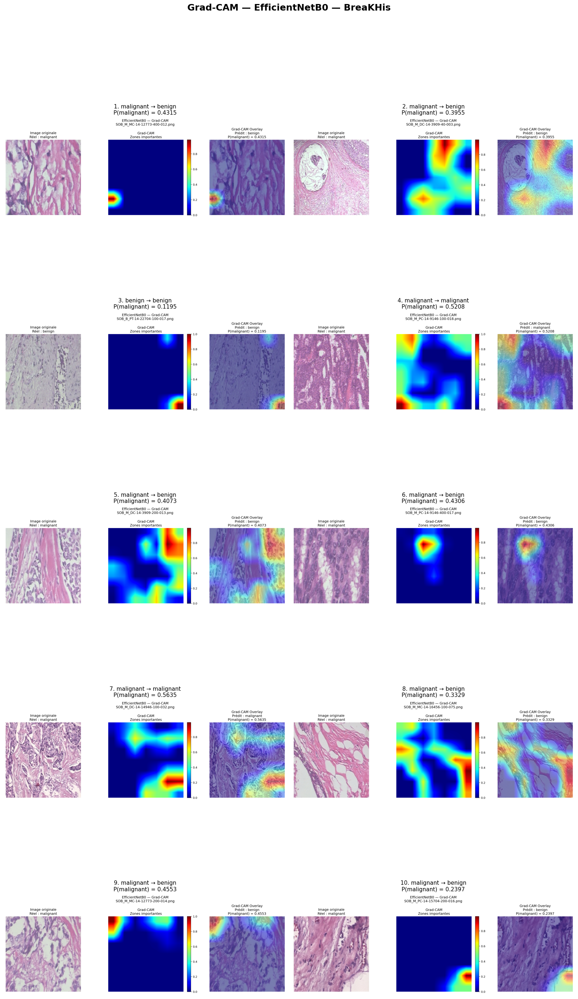


✅ Planche sauvegardée : /kaggle/working/output/14_gradcam_montage.png

🚨 PLANCHE DES FAUX NÉGATIFS
🚨 Faux négatifs Grad-CAM : 7


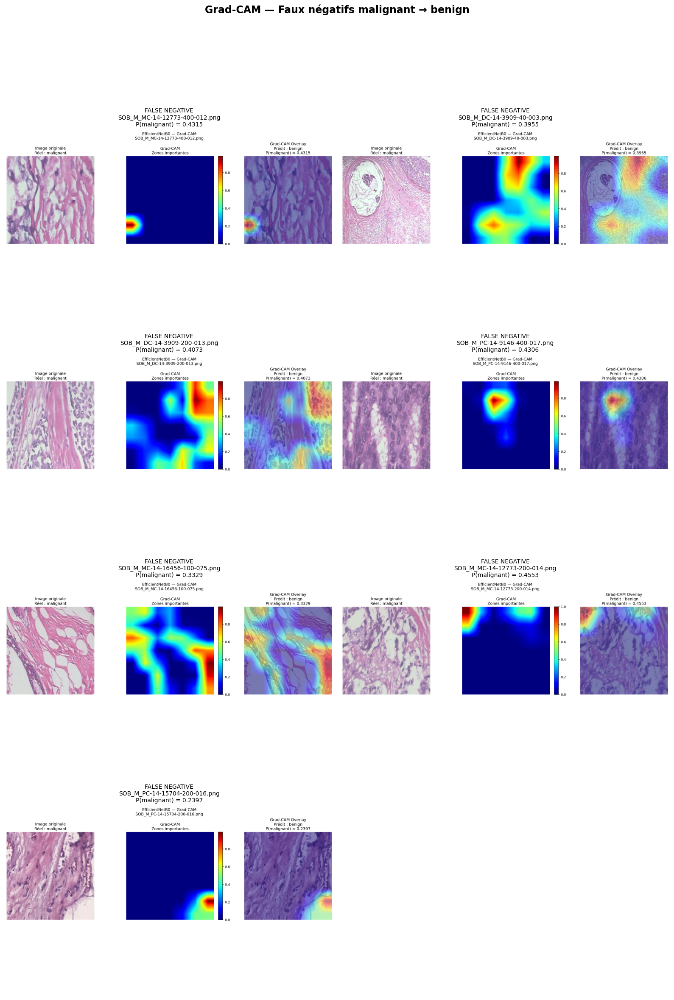

✅ Planche FN sauvegardée : /kaggle/working/output/15_gradcam_false_negatives.png

✅ PLANCHE DES PRÉDICTIONS CORRECTES
Images correctement classées : 3


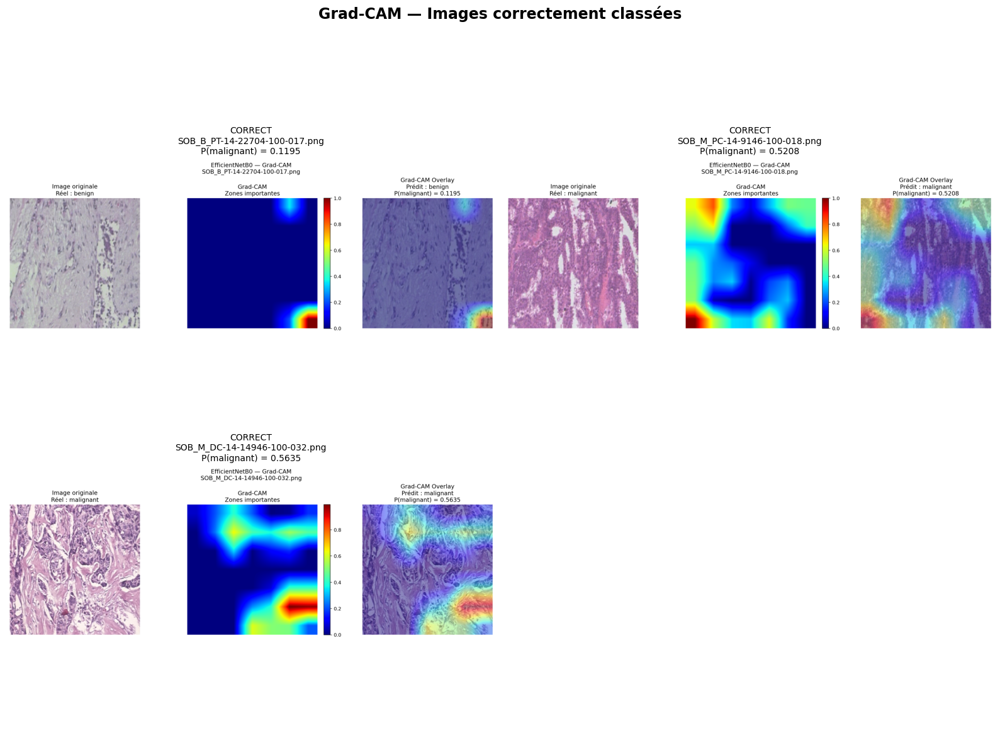

✅ Planche correcte sauvegardée : /kaggle/working/output/16_gradcam_correct_predictions.png

💾 SAUVEGARDE DU RÉCAPITULATIF
✅ CSV sauvegardé : /kaggle/working/output/gradcam_summary.csv

🏁 CELL 15 TERMINÉE

🔥 Images Grad-CAM analysées : 10
📁 Dossier Grad-CAM : /kaggle/working/output/gradcam
📊 CSV synthèse : /kaggle/working/output/gradcam_summary.csv
🖼️ Montage principal : /kaggle/working/output/14_gradcam_montage.png
🚨 Faux négatifs dans la sélection : 7

⏱️ Durée Cell 15 : 0.26 minutes

📂 FICHIERS PRINCIPAUX :
✓ 14_gradcam_montage.png                             5523.06 KB
✓ 15_gradcam_false_negatives.png                     3828.67 KB
✓ 16_gradcam_correct_predictions.png                 1825.95 KB

✅ SYNTHÈSE GRAD-CAM TERMINÉE


In [17]:
# ==============================================================================
# 🧪 CELL 15 — SYNTHÈSE VISUELLE GRAD-CAM
#    EfficientNetB0 + BreakHis
# ==============================================================================

import os
import time
import glob
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

START_TIME = time.time()

OUTPUT_DIR = "/kaggle/working/output"
GRADCAM_DIR = os.path.join(OUTPUT_DIR, "gradcam")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(GRADCAM_DIR, exist_ok=True)

print("=" * 80)
print("🧪 CELL 15 — SYNTHÈSE VISUELLE GRAD-CAM")
print("   EfficientNetB0 + BreakHis")
print("=" * 80)

print(f"\n📁 Dossier output : {OUTPUT_DIR}")
print(f"📁 Dossier Grad-CAM : {GRADCAM_DIR}")

# ==============================================================================
# 1. VÉRIFICATION DES FICHIERS
# ==============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES FICHIERS")
print("=" * 80)

gradcam_files = sorted(
    glob.glob(os.path.join(GRADCAM_DIR, "*_gradcam.png"))
)

print(f"🖼️ Images Grad-CAM trouvées : {len(gradcam_files)}")

if len(gradcam_files) == 0:
    raise FileNotFoundError(
        f"\n❌ Aucune image Grad-CAM trouvée dans : {GRADCAM_DIR}\n"
        "➡️ Exécute d'abord la Cell 14."
    )

for i, path in enumerate(gradcam_files, 1):
    print(f"✓ {i:02d} — {os.path.basename(path)}")

# ==============================================================================
# 2. CHARGEMENT DU CSV GRAD-CAM
# ==============================================================================

print("\n" + "=" * 80)
print("📄 CHARGEMENT DE L'ANALYSE GRAD-CAM")
print("=" * 80)

GRADCAM_CSV = os.path.join(
    OUTPUT_DIR,
    "gradcam_analysis.csv"
)

if os.path.exists(GRADCAM_CSV):

    gradcam_df = pd.read_csv(GRADCAM_CSV)

    print("✅ CSV Grad-CAM trouvé")
    print(f"📊 Nombre de lignes : {len(gradcam_df)}")
    print(f"📋 Colonnes : {list(gradcam_df.columns)}")

else:

    print("⚠️ gradcam_analysis.csv introuvable.")
    print("➡️ Création d'un tableau à partir des fichiers PNG.")

    gradcam_df = pd.DataFrame({
        "gradcam_file": [
            os.path.basename(x)
            for x in gradcam_files
        ]
    })

# ==============================================================================
# 3. DÉTECTION DES COLONNES
# ==============================================================================

print("\n" + "=" * 80)
print("🔎 DÉTECTION DES INFORMATIONS")
print("=" * 80)

def find_column(df, candidates):

    for col in candidates:
        if col in df.columns:
            return col

    return None


COL_FILENAME = find_column(
    gradcam_df,
    ["filename", "image", "image_name", "file", "image_file"]
)

COL_TRUE = find_column(
    gradcam_df,
    ["true_label", "true_label_name", "label", "real_label"]
)

COL_PRED = find_column(
    gradcam_df,
    ["predicted_label", "predicted_label_name", "prediction"]
)

COL_PROB = find_column(
    gradcam_df,
    [
        "prob_malignant",
        "malignant_probability",
        "probability",
        "prob"
    ]
)

print(f"Filename       : {COL_FILENAME}")
print(f"True label     : {COL_TRUE}")
print(f"Predicted      : {COL_PRED}")
print(f"Probability    : {COL_PROB}")

# ==============================================================================
# 4. CRÉATION DU RÉCAPITULATIF
# ==============================================================================

print("\n" + "=" * 80)
print("📊 CRÉATION DU RÉCAPITULATIF")
print("=" * 80)

summary_rows = []

for idx, gradcam_path in enumerate(gradcam_files):

    filename_gradcam = os.path.basename(gradcam_path)

    # Exemple :
    # 01_SOB_M_MC-14-16456-100-070_gradcam.png
    base_name = filename_gradcam

    # Suppression du préfixe numérique
    if "_" in base_name:
        original_name = base_name.split("_", 1)[1]
    else:
        original_name = base_name

    # Suppression du suffixe _gradcam.png
    original_name = original_name.replace(
        "_gradcam.png",
        ".png"
    )

    row = {
        "gradcam_file": filename_gradcam,
        "original_filename": original_name,
        "gradcam_path": gradcam_path
    }

    # Recherche correspondante dans le CSV
    matching_row = None

    if COL_FILENAME is not None:

        matches = gradcam_df[
            gradcam_df[COL_FILENAME].astype(str).str.contains(
                original_name.replace(".png", ""),
                regex=False,
                na=False
            )
        ]

        if len(matches) > 0:
            matching_row = matches.iloc[0]

    if matching_row is not None:

        if COL_TRUE:
            row["true_label"] = matching_row[COL_TRUE]

        if COL_PRED:
            row["predicted_label"] = matching_row[COL_PRED]

        if COL_PROB:
            row["prob_malignant"] = matching_row[COL_PROB]

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

# ==============================================================================
# 5. DÉTERMINATION DU TYPE D'ERREUR
# ==============================================================================

print("\n🔬 Classification des résultats...")

def determine_error(row):

    true_label = str(row.get("true_label", "")).lower()
    pred_label = str(row.get("predicted_label", "")).lower()

    if true_label == "":
        return "Unknown"

    if pred_label == "":
        return "Unknown"

    if true_label == pred_label:
        return "Correct"

    if (
        "malignant" in true_label
        and "benign" in pred_label
    ):
        return "False Negative"

    if (
        "benign" in true_label
        and "malignant" in pred_label
    ):
        return "False Positive"

    return "Incorrect"


summary_df["error_type"] = summary_df.apply(
    determine_error,
    axis=1
)

# ==============================================================================
# 6. AFFICHAGE DU RÉCAPITULATIF
# ==============================================================================

print("\n" + "=" * 80)
print("📋 RÉCAPITULATIF GRAD-CAM")
print("=" * 80)

display(summary_df)

# ==============================================================================
# 7. STATISTIQUES
# ==============================================================================

print("\n" + "=" * 80)
print("📊 STATISTIQUES")
print("=" * 80)

print(
    f"🖼️ Nombre total Grad-CAM : {len(summary_df)}"
)

if "error_type" in summary_df.columns:

    error_counts = summary_df["error_type"].value_counts()

    for error_type, count in error_counts.items():
        print(
            f"• {error_type:<20} : {count}"
        )

# ==============================================================================
# 8. CRÉATION DE LA PLANCHE GRAD-CAM
# ==============================================================================

print("\n" + "=" * 80)
print("🖼️ CRÉATION DE LA PLANCHE GRAD-CAM")
print("=" * 80)

N_IMAGES = len(gradcam_files)

# Maximum 10 images par planche
COLS = 2
ROWS = math.ceil(N_IMAGES / COLS)

FIG_WIDTH = 16
FIG_HEIGHT = max(6, ROWS * 6)

print(
    f"📐 Configuration : {ROWS} lignes × {COLS} colonnes"
)

fig, axes = plt.subplots(
    ROWS,
    COLS,
    figsize=(FIG_WIDTH, FIG_HEIGHT)
)

axes = np.array(axes).reshape(-1)

for i, gradcam_path in enumerate(gradcam_files):

    print(
        f"🔄 Ajout image {i + 1}/{N_IMAGES}..."
    )

    try:

        img = Image.open(
            gradcam_path
        ).convert("RGB")

        axes[i].imshow(img)
        axes[i].axis("off")

        # Récupération des informations
        current_row = summary_df.iloc[i]

        true_label = current_row.get(
            "true_label",
            "N/A"
        )

        pred_label = current_row.get(
            "predicted_label",
            "N/A"
        )

        prob = current_row.get(
            "prob_malignant",
            np.nan
        )

        error_type = current_row.get(
            "error_type",
            "Unknown"
        )

        title = (
            f"{i + 1}. "
            f"{true_label} → {pred_label}\n"
            f"P(malignant) = {prob:.4f}"
            if not pd.isna(prob)
            else
            f"{i + 1}. "
            f"{true_label} → {pred_label}"
        )

        axes[i].set_title(
            title,
            fontsize=11
        )

    except Exception as e:

        print(
            f"⚠️ Erreur image {i + 1} : {e}"
        )

        axes[i].text(
            0.5,
            0.5,
            "Erreur chargement",
            ha="center",
            va="center"
        )

        axes[i].axis("off")

# Cacher les axes inutilisés
for i in range(N_IMAGES, len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Grad-CAM — EfficientNetB0 — BreaKHis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

MONTAGE_PATH = os.path.join(
    OUTPUT_DIR,
    "14_gradcam_montage.png"
)

plt.savefig(
    MONTAGE_PATH,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n✅ Planche sauvegardée : {MONTAGE_PATH}"
)

# ==============================================================================
# 9. PLANCHE SPÉCIALE DES FAUX NÉGATIFS
# ==============================================================================

print("\n" + "=" * 80)
print("🚨 PLANCHE DES FAUX NÉGATIFS")
print("=" * 80)

fn_df = summary_df[
    summary_df["error_type"] == "False Negative"
].copy()

print(
    f"🚨 Faux négatifs Grad-CAM : {len(fn_df)}"
)

if len(fn_df) > 0:

    fn_files = fn_df["gradcam_path"].tolist()

    cols = 2
    rows = math.ceil(len(fn_files) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(16, max(6, rows * 6))
    )

    axes = np.array(axes).reshape(-1)

    for i, path in enumerate(fn_files):

        try:

            img = Image.open(
                path
            ).convert("RGB")

            axes[i].imshow(img)
            axes[i].axis("off")

            row = fn_df.iloc[i]

            prob = row.get(
                "prob_malignant",
                np.nan
            )

            axes[i].set_title(
                f"FALSE NEGATIVE\n"
                f"{row.get('original_filename', '')}\n"
                f"P(malignant) = "
                f"{prob:.4f}"
                if not pd.isna(prob)
                else
                f"FALSE NEGATIVE\n"
                f"{row.get('original_filename', '')}",
                fontsize=10
            )

        except Exception as e:

            print(
                f"⚠️ Erreur FN {i + 1}: {e}"
            )

            axes[i].axis("off")

    for i in range(len(fn_files), len(axes)):
        axes[i].axis("off")

    plt.suptitle(
        "Grad-CAM — Faux négatifs malignant → benign",
        fontsize=17,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    FN_MONTAGE_PATH = os.path.join(
        OUTPUT_DIR,
        "15_gradcam_false_negatives.png"
    )

    plt.savefig(
        FN_MONTAGE_PATH,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"✅ Planche FN sauvegardée : "
        f"{FN_MONTAGE_PATH}"
    )

else:

    print(
        "ℹ️ Aucun faux négatif parmi les images Grad-CAM sélectionnées."
    )

# ==============================================================================
# 10. PLANCHE DES IMAGES CORRECTEMENT CLASSÉES
# ==============================================================================

print("\n" + "=" * 80)
print("✅ PLANCHE DES PRÉDICTIONS CORRECTES")
print("=" * 80)

correct_df = summary_df[
    summary_df["error_type"] == "Correct"
].copy()

print(
    f"Images correctement classées : {len(correct_df)}"
)

if len(correct_df) > 0:

    correct_files = correct_df[
        "gradcam_path"
    ].tolist()

    cols = 2
    rows = math.ceil(
        len(correct_files) / cols
    )

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(16, max(6, rows * 6))
    )

    axes = np.array(axes).reshape(-1)

    for i, path in enumerate(correct_files):

        try:

            img = Image.open(
                path
            ).convert("RGB")

            axes[i].imshow(img)
            axes[i].axis("off")

            row = correct_df.iloc[i]

            prob = row.get(
                "prob_malignant",
                np.nan
            )

            axes[i].set_title(
                f"CORRECT\n"
                f"{row.get('original_filename', '')}\n"
                f"P(malignant) = "
                f"{prob:.4f}"
                if not pd.isna(prob)
                else
                f"CORRECT\n"
                f"{row.get('original_filename', '')}",
                fontsize=10
            )

        except Exception as e:

            print(
                f"⚠️ Erreur image {i + 1}: {e}"
            )

            axes[i].axis("off")

    for i in range(
        len(correct_files),
        len(axes)
    ):
        axes[i].axis("off")

    plt.suptitle(
        "Grad-CAM — Images correctement classées",
        fontsize=17,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    CORRECT_MONTAGE_PATH = os.path.join(
        OUTPUT_DIR,
        "16_gradcam_correct_predictions.png"
    )

    plt.savefig(
        CORRECT_MONTAGE_PATH,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"✅ Planche correcte sauvegardée : "
        f"{CORRECT_MONTAGE_PATH}"
    )

# ==============================================================================
# 11. SAUVEGARDE DU CSV FINAL
# ==============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE DU RÉCAPITULATIF")
print("=" * 80)

SUMMARY_CSV = os.path.join(
    OUTPUT_DIR,
    "gradcam_summary.csv"
)

summary_df.to_csv(
    SUMMARY_CSV,
    index=False,
    encoding="utf-8"
)

print(
    f"✅ CSV sauvegardé : {SUMMARY_CSV}"
)

# ==============================================================================
# 12. RAPPORT FINAL
# ==============================================================================

duration = (
    time.time() - START_TIME
) / 60

print("\n" + "=" * 80)
print("🏁 CELL 15 TERMINÉE")
print("=" * 80)

print(
    f"\n🔥 Images Grad-CAM analysées : "
    f"{len(gradcam_files)}"
)

print(
    f"📁 Dossier Grad-CAM : "
    f"{GRADCAM_DIR}"
)

print(
    f"📊 CSV synthèse : "
    f"{SUMMARY_CSV}"
)

print(
    f"🖼️ Montage principal : "
    f"{MONTAGE_PATH}"
)

if len(fn_df) > 0:
    print(
        f"🚨 Faux négatifs dans la sélection : "
        f"{len(fn_df)}"
    )

print(
    f"\n⏱️ Durée Cell 15 : "
    f"{duration:.2f} minutes"
)

print("\n📂 FICHIERS PRINCIPAUX :")

for file_path in sorted(
    glob.glob(
        os.path.join(
            OUTPUT_DIR,
            "*gradcam*.png"
        )
    )
):

    size_kb = (
        os.path.getsize(file_path)
        / 1024
    )

    print(
        f"✓ {os.path.basename(file_path):50s}"
        f" {size_kb:.2f} KB"
    )

print("\n" + "=" * 80)
print("✅ SYNTHÈSE GRAD-CAM TERMINÉE")
print("=" * 80)

🧪 CELL 16 — SYNTHÈSE FINALE DU MODÈLE
   EfficientNetB0 + BreakHis

📁 Dossier output : /kaggle/working/output

🔎 VÉRIFICATION DES VARIABLES
✓ all_labels
✓ all_probs
✓ all_preds
✓ accuracy
✓ precision
✓ recall
✓ f1
✓ auc_roc
✓ auc_pr
✓ predictions_df
✓ CLASS_NAMES

✅ Toutes les variables principales sont disponibles.

📊 INFORMATIONS GÉNÉRALES
Nombre d'images test : 1,346
Classes : ['benign', 'malignant']
Nombre de classes : 2

🎯 MÉTRIQUES PRINCIPALES
Accuracy    : 0.7883
Precision   : 0.9760
Recall      : 0.7327
F1-score    : 0.8370
AUC ROC     : 0.9217
AUC PR      : 0.9722

🔥 SEUILS OPTIMAUX
📄 Lecture de threshold_analysis.csv...
✓ 91 seuils disponibles
🥇 Meilleur seuil F1     : 0.20
   F1                    : 0.9096
🥇 Meilleur seuil Youden : 0.30
   Youden J              : 0.7158

🧩 MATRICE DE CONFUSION
[[329  18]
 [267 732]]

TN : 329
FP : 18
FN : 267
TP : 732

📊 DISTRIBUTION DES PRÉDICTIONS
benign      :   596 ( 44.28%)
malignant   :   750 ( 55.72%)

🔬 ANALYSE DES ERREURS
Images cor

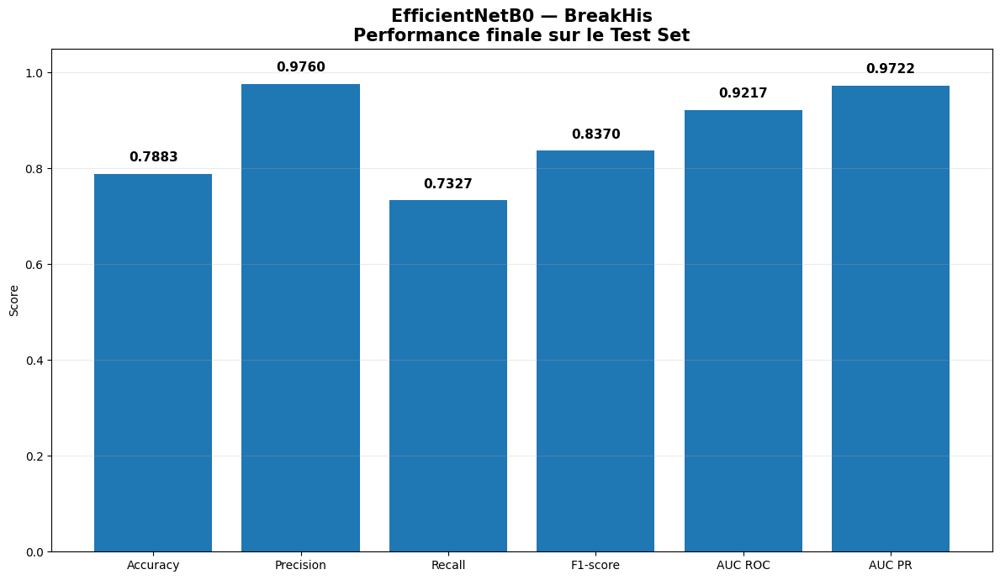

✅ Graphique sauvegardé : /kaggle/working/output/17_final_model_metrics.png

📈 CRÉATION DU GRAPHIQUE DES SEUILS


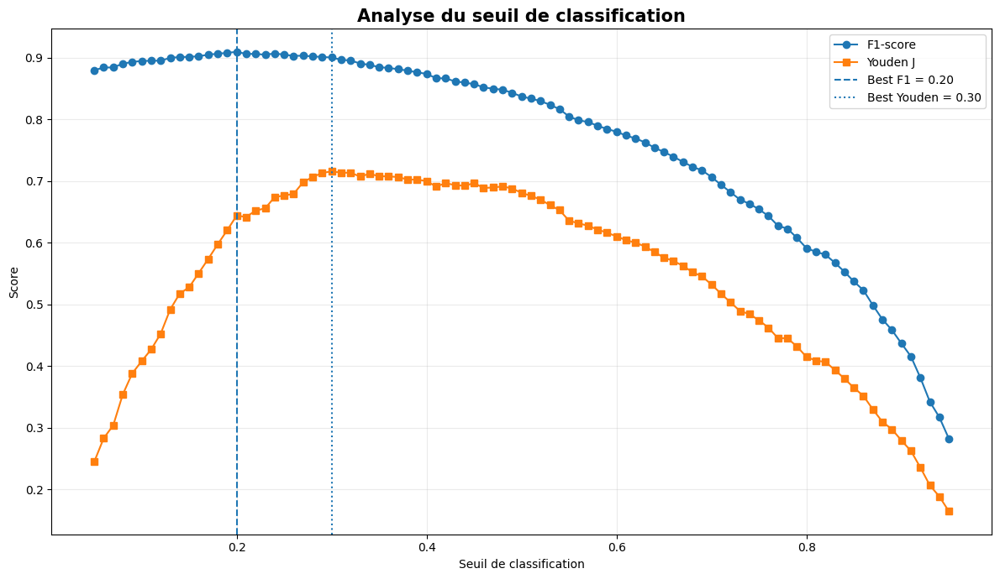

✅ Graphique seuil sauvegardé : /kaggle/working/output/18_final_threshold_analysis.png

🎯 SYNTHÈSE FINALE

📌 MODÈLE
EfficientNetB0 + BreakHis

📌 PERFORMANCE TEST
Accuracy    : 0.7883
Precision   : 0.9760
Recall      : 0.7327
F1-score    : 0.8370
AUC ROC     : 0.9217
AUC PR      : 0.9722

📌 SEUIL OPTIMAL F1
Seuil : 0.20
F1    : 0.9096

📌 SEUIL OPTIMAL YOUDEN
Seuil : 0.30
Youden J : 0.7158

📌 ERREURS
False Positives : 18
False Negatives : 267
Correct         : 1061
Incorrect       : 285

📌 EXPLAINABILITY
Images Grad-CAM : 10

🏁 CELL 16 TERMINÉE

⏱️ Durée Cell 16 : 0.02 minutes

📂 FICHIERS FINAUX CRÉÉS :
✓ 01_confusion_matrix.png                                     102.89 KB
✓ 02_roc_curve.png                                            143.79 KB
✓ 03_precision_recall_curve.png                               112.21 KB
✓ 04_probability_distribution.png                             105.29 KB
✓ 05_test_metrics.png                                          99.34 KB
✓ 06_threshold_analysis.png     

In [18]:
# ================================================================================
# 🧪 CELL 16 — SYNTHÈSE FINALE DU MODÈLE
#    EfficientNetB0 + BreakHis
# ================================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START_TIME_CELL16 = time.time()

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 80)
print("🧪 CELL 16 — SYNTHÈSE FINALE DU MODÈLE")
print("   EfficientNetB0 + BreakHis")
print("=" * 80)

print(f"\n📁 Dossier output : {OUTPUT_DIR}")

# ================================================================================
# 🔎 VÉRIFICATION DES VARIABLES
# ================================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES VARIABLES")
print("=" * 80)

required_variables = [
    "all_labels",
    "all_probs",
    "all_preds",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc_roc",
    "auc_pr",
    "predictions_df",
    "CLASS_NAMES"
]

missing_variables = []

for var in required_variables:
    if var in globals():
        print(f"✓ {var}")
    else:
        print(f"❌ {var} MANQUANTE")
        missing_variables.append(var)

if missing_variables:
    raise RuntimeError(
        "Variables manquantes : " + ", ".join(missing_variables)
    )

print("\n✅ Toutes les variables principales sont disponibles.")

# ================================================================================
# 📊 INFORMATIONS GÉNÉRALES
# ================================================================================

print("\n" + "=" * 80)
print("📊 INFORMATIONS GÉNÉRALES")
print("=" * 80)

n_images = len(all_labels)

print(f"Nombre d'images test : {n_images:,}")
print(f"Classes : {CLASS_NAMES}")
print(f"Nombre de classes : {len(CLASS_NAMES)}")

# ================================================================================
# 🎯 MÉTRIQUES PRINCIPALES
# ================================================================================

print("\n" + "=" * 80)
print("🎯 MÉTRIQUES PRINCIPALES")
print("=" * 80)

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"AUC ROC     : {auc_roc:.4f}")
print(f"AUC PR      : {auc_pr:.4f}")

# ================================================================================
# 🔥 SEUILS OPTIMAUX
# ================================================================================

print("\n" + "=" * 80)
print("🔥 SEUILS OPTIMAUX")
print("=" * 80)

best_f1_threshold = None
best_f1_value = None

best_youden_threshold = None
best_youden_value = None

threshold_file = os.path.join(
    OUTPUT_DIR,
    "threshold_analysis.csv"
)

if os.path.exists(threshold_file):

    print("📄 Lecture de threshold_analysis.csv...")

    threshold_df = pd.read_csv(threshold_file)

    print(f"✓ {len(threshold_df)} seuils disponibles")

    if "f1_score" in threshold_df.columns:

        best_row_f1 = threshold_df.loc[
            threshold_df["f1_score"].idxmax()
        ]

        best_f1_threshold = float(best_row_f1["threshold"])
        best_f1_value = float(best_row_f1["f1_score"])

    if "youden_j" in threshold_df.columns:

        best_row_youden = threshold_df.loc[
            threshold_df["youden_j"].idxmax()
        ]

        best_youden_threshold = float(best_row_youden["threshold"])
        best_youden_value = float(best_row_youden["youden_j"])

else:

    print("⚠️ threshold_analysis.csv non trouvé")

if best_f1_threshold is not None:
    print(f"🥇 Meilleur seuil F1     : {best_f1_threshold:.2f}")
    print(f"   F1                    : {best_f1_value:.4f}")

if best_youden_threshold is not None:
    print(f"🥇 Meilleur seuil Youden : {best_youden_threshold:.2f}")
    print(f"   Youden J              : {best_youden_value:.4f}")

# ================================================================================
# 🧩 MATRICE DE CONFUSION
# ================================================================================

print("\n" + "=" * 80)
print("🧩 MATRICE DE CONFUSION")
print("=" * 80)

from sklearn.metrics import confusion_matrix

cm_final = confusion_matrix(
    all_labels,
    all_preds
)

print(cm_final)

if cm_final.shape == (2, 2):

    TN, FP, FN, TP = cm_final.ravel()

    print(f"\nTN : {TN}")
    print(f"FP : {FP}")
    print(f"FN : {FN}")
    print(f"TP : {TP}")

else:

    TN = FP = FN = TP = np.nan

# ================================================================================
# 📊 DISTRIBUTION DES PRÉDICTIONS
# ================================================================================

print("\n" + "=" * 80)
print("📊 DISTRIBUTION DES PRÉDICTIONS")
print("=" * 80)

unique_preds, counts_preds = np.unique(
    all_preds,
    return_counts=True
)

for cls_id, count in zip(unique_preds, counts_preds):

    cls_name = (
        CLASS_NAMES[int(cls_id)]
        if int(cls_id) < len(CLASS_NAMES)
        else str(cls_id)
    )

    percentage = count / n_images * 100

    print(
        f"{cls_name:<12}: "
        f"{count:>5} ({percentage:6.2f}%)"
    )

# ================================================================================
# 🔬 ANALYSE DES ERREURS
# ================================================================================

print("\n" + "=" * 80)
print("🔬 ANALYSE DES ERREURS")
print("=" * 80)

correct_count = int(np.sum(np.array(all_labels) == np.array(all_preds)))
error_count = n_images - correct_count

print(f"Images correctement classées : {correct_count}")
print(f"Images mal classées           : {error_count}")

if not np.isnan(FP):
    print(f"False Positives               : {int(FP)}")

if not np.isnan(FN):
    print(f"False Negatives               : {int(FN)}")

# ================================================================================
# 📈 ANALYSE SUBTYPE
# ================================================================================

print("\n" + "=" * 80)
print("📈 ANALYSE PAR SUBTYPE")
print("=" * 80)

subtype_file = os.path.join(
    OUTPUT_DIR,
    "08_metrics_by_subtype.csv"
)

subtype_df = None

if os.path.exists(subtype_file):

    subtype_df = pd.read_csv(subtype_file)

    print(f"✓ Analyse subtype chargée : {len(subtype_df)} lignes")

    print(subtype_df.to_string(index=False))

else:

    print("⚠️ Fichier subtype non trouvé")

# ================================================================================
# 🔍 ANALYSE MAGNIFICATION
# ================================================================================

print("\n" + "=" * 80)
print("🔍 ANALYSE PAR MAGNIFICATION")
print("=" * 80)

magnification_file = os.path.join(
    OUTPUT_DIR,
    "09_metrics_by_magnification.csv"
)

magnification_df = None

if os.path.exists(magnification_file):

    magnification_df = pd.read_csv(
        magnification_file
    )

    print(
        f"✓ Analyse magnification chargée : "
        f"{len(magnification_df)} lignes"
    )

    print(
        magnification_df.to_string(index=False)
    )

else:

    print("⚠️ Fichier magnification non trouvé")

# ================================================================================
# 👤 ANALYSE PATIENT
# ================================================================================

print("\n" + "=" * 80)
print("👤 ANALYSE PATIENT")
print("=" * 80)

patient_file = os.path.join(
    OUTPUT_DIR,
    "10_patient_level_analysis.csv"
)

patient_df = None

if os.path.exists(patient_file):

    patient_df = pd.read_csv(patient_file)

    print(
        f"✓ Analyse patient chargée : "
        f"{len(patient_df)} patients"
    )

    if "accuracy_mean_probability" in patient_df.columns:

        print(
            "Accuracy patient — moyenne probabilité : "
            f"{patient_df['accuracy_mean_probability'].mean():.4f}"
        )

    print(patient_df.to_string(index=False))

else:

    print("⚠️ Analyse patient non trouvée")

# ================================================================================
# 🔥 GRAD-CAM
# ================================================================================

print("\n" + "=" * 80)
print("🔥 ANALYSE GRAD-CAM")
print("=" * 80)

gradcam_dir = os.path.join(
    OUTPUT_DIR,
    "gradcam"
)

gradcam_summary_file = os.path.join(
    OUTPUT_DIR,
    "gradcam_summary.csv"
)

gradcam_images = []

if os.path.exists(gradcam_dir):

    gradcam_images = [
        f for f in os.listdir(gradcam_dir)
        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        )
    ]

print(
    f"Images Grad-CAM disponibles : "
    f"{len(gradcam_images)}"
)

gradcam_df = None

if os.path.exists(gradcam_summary_file):

    gradcam_df = pd.read_csv(
        gradcam_summary_file
    )

    print(
        f"✓ Résumé Grad-CAM chargé : "
        f"{len(gradcam_df)} lignes"
    )

    if "error_type" in gradcam_df.columns:

        print(
            gradcam_df["error_type"]
            .value_counts()
            .to_string()
        )

# ================================================================================
# 📋 CRÉATION DU RAPPORT FINAL
# ================================================================================

print("\n" + "=" * 80)
print("📋 CRÉATION DU RAPPORT FINAL")
print("=" * 80)

report_data = {

    "Model": "EfficientNetB0_BreakHis",

    "Dataset": "BreakHis",

    "Test_images": n_images,

    "Accuracy": float(accuracy),

    "Precision": float(precision),

    "Recall": float(recall),

    "F1_score": float(f1),

    "AUC_ROC": float(auc_roc),

    "AUC_PR": float(auc_pr),

    "True_Negative": int(TN)
        if not np.isnan(TN) else None,

    "False_Positive": int(FP)
        if not np.isnan(FP) else None,

    "False_Negative": int(FN)
        if not np.isnan(FN) else None,

    "True_Positive": int(TP)
        if not np.isnan(TP) else None,

    "Best_F1_threshold":
        best_f1_threshold,

    "Best_F1":
        best_f1_value,

    "Best_Youden_threshold":
        best_youden_threshold,

    "Best_Youden_J":
        best_youden_value,

    "Correct_predictions":
        correct_count,

    "Incorrect_predictions":
        error_count,

    "GradCAM_images":
        len(gradcam_images)
}

report_df = pd.DataFrame(
    [report_data]
)

report_path = os.path.join(
    OUTPUT_DIR,
    "final_model_report.csv"
)

report_df.to_csv(
    report_path,
    index=False
)

print(
    f"✅ Rapport final sauvegardé : "
    f"{report_path}"
)

# ================================================================================
# 📊 GRAPHIQUE FINAL DES MÉTRIQUES
# ================================================================================

print("\n" + "=" * 80)
print("📊 CRÉATION DU GRAPHIQUE FINAL")
print("=" * 80)

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC ROC",
    "AUC PR"
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1,
    auc_roc,
    auc_pr
]

plt.figure(figsize=(12, 7))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1.05)

plt.ylabel("Score")

plt.title(
    "EfficientNetB0 — BreakHis\n"
    "Performance finale sur le Test Set",
    fontsize=15,
    fontweight="bold"
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

final_metrics_image = os.path.join(
    OUTPUT_DIR,
    "17_final_model_metrics.png"
)

plt.savefig(
    final_metrics_image,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"✅ Graphique sauvegardé : "
    f"{final_metrics_image}"
)

# ================================================================================
# 📊 GRAPHIQUE SEUIL
# ================================================================================

if (
    best_f1_threshold is not None
    and best_youden_threshold is not None
    and os.path.exists(threshold_file)
):

    print("\n" + "=" * 80)
    print("📈 CRÉATION DU GRAPHIQUE DES SEUILS")
    print("=" * 80)

    threshold_plot_df = pd.read_csv(
        threshold_file
    )

    if (
        "threshold" in threshold_plot_df.columns
        and "f1_score" in threshold_plot_df.columns
        and "youden_j" in threshold_plot_df.columns
    ):

        plt.figure(figsize=(12, 7))

        plt.plot(
            threshold_plot_df["threshold"],
            threshold_plot_df["f1_score"],
            marker="o",
            label="F1-score"
        )

        plt.plot(
            threshold_plot_df["threshold"],
            threshold_plot_df["youden_j"],
            marker="s",
            label="Youden J"
        )

        plt.axvline(
            best_f1_threshold,
            linestyle="--",
            label=f"Best F1 = {best_f1_threshold:.2f}"
        )

        plt.axvline(
            best_youden_threshold,
            linestyle=":",
            label=f"Best Youden = {best_youden_threshold:.2f}"
        )

        plt.xlabel("Seuil de classification")
        plt.ylabel("Score")

        plt.title(
            "Analyse du seuil de classification",
            fontsize=15,
            fontweight="bold"
        )

        plt.legend()

        plt.grid(
            alpha=0.25
        )

        plt.tight_layout()

        threshold_plot_path = os.path.join(
            OUTPUT_DIR,
            "18_final_threshold_analysis.png"
        )

        plt.savefig(
            threshold_plot_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()

        print(
            f"✅ Graphique seuil sauvegardé : "
            f"{threshold_plot_path}"
        )

# ================================================================================
# 📊 RÉSUMÉ TEXTE
# ================================================================================

print("\n" + "=" * 80)
print("🎯 SYNTHÈSE FINALE")
print("=" * 80)

print("\n📌 MODÈLE")
print("EfficientNetB0 + BreakHis")

print("\n📌 PERFORMANCE TEST")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"AUC ROC     : {auc_roc:.4f}")
print(f"AUC PR      : {auc_pr:.4f}")

if best_f1_threshold is not None:

    print("\n📌 SEUIL OPTIMAL F1")
    print(
        f"Seuil : {best_f1_threshold:.2f}"
    )

    print(
        f"F1    : {best_f1_value:.4f}"
    )

if best_youden_threshold is not None:

    print("\n📌 SEUIL OPTIMAL YOUDEN")
    print(
        f"Seuil : {best_youden_threshold:.2f}"
    )

    print(
        f"Youden J : {best_youden_value:.4f}"
    )

print("\n📌 ERREURS")

if not np.isnan(FP):
    print(f"False Positives : {int(FP)}")

if not np.isnan(FN):
    print(f"False Negatives : {int(FN)}")

print(f"Correct         : {correct_count}")
print(f"Incorrect       : {error_count}")

print("\n📌 EXPLAINABILITY")
print(
    f"Images Grad-CAM : {len(gradcam_images)}"
)

# ================================================================================
# ⏱️ FIN
# ================================================================================

duration_cell16 = (
    time.time() - START_TIME_CELL16
)

print("\n" + "=" * 80)
print("🏁 CELL 16 TERMINÉE")
print("=" * 80)

print(
    f"\n⏱️ Durée Cell 16 : "
    f"{duration_cell16 / 60:.2f} minutes"
)

print("\n📂 FICHIERS FINAUX CRÉÉS :")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    filepath = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.isfile(filepath):

        size_kb = (
            os.path.getsize(filepath) / 1024
        )

        print(
            f"✓ {filename:<55} "
            f"{size_kb:>10.2f} KB"
        )

print("\n" + "=" * 80)
print("✅ SYNTHÈSE FINALE DU MODÈLE TERMINÉE")
print("=" * 80)

In [19]:
# ============================================================================
# 🔥 CELL 17 — ENTRAÎNEMENT PHASE 2 (FINE-TUNING AMÉLIORÉ)
#    EfficientNetB0 + BreakHis
# ============================================================================
#
# Objectif :
#   Dégeler une partie plus large du backbone EfficientNetB0 et
#   continuer l'entraînement avec un schedule de learning rate en
#   cosine decay (plus stable et généralement plus performant qu'un
#   LR fixe + ReduceLROnPlateau pour le fine-tuning).
#
# Améliorations vs version précédente :
#   - Dégel de la moitié du backbone (au lieu du dernier tiers)
#   - Cosine decay du LR (descente douce, sans paliers brusques)
#   - label_smoothing dans la loss (cohérent avec Cell 09)
#   - Plus d'epochs + patience un peu plus grande (le cosine decay
#     laisse le temps au modèle de converger doucement)
#
# Règles de fine-tuning toujours respectées :
#   - LR de départ bas (1e-5) pour ne pas détruire les poids ImageNet
#   - Les couches BatchNormalization restent gelées (même dégelées,
#     leur mise à jour sur un petit dataset déstabilise l'entraînement)
#   - Le graphe garde `training=False` sur l'appel du backbone (défini
#     en Cell 08) — pratique recommandée par Keras pour le fine-tuning.
# ============================================================================

import os
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras

print("=" * 80)
print("🔥 CELL 17 — ENTRAÎNEMENT PHASE 2 (FINE-TUNING AMÉLIORÉ)")
print("=" * 80)

# ============================================================================
# 1. VÉRIFICATION DES VARIABLES
# ============================================================================

required_vars = [
    "train_ds",
    "val_ds",
    "test_ds",
    "class_weights",
    "CLASS_NAMES",
    "GLOBAL_BATCH_SIZE",
    "MODEL_DIR",
    "strategy",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"❌ Variables manquantes : {missing}\n"
        "➡️ Exécute d'abord les Cells 01 à 10."
    )

print("✅ Toutes les variables nécessaires sont disponibles.")

LABEL_SMOOTHING = globals().get("LABEL_SMOOTHING", 0.05)

PHASE1_BEST_PATH = os.path.join(
    MODEL_DIR,
    "EfficientNetB0_BreakHis_phase1_best.keras"
)

if not os.path.exists(PHASE1_BEST_PATH):
    raise FileNotFoundError(
        f"❌ Modèle Phase 1 introuvable : {PHASE1_BEST_PATH}\n"
        "➡️ Exécute d'abord la Cell 10."
    )

print(f"\n📁 Modèle Phase 1 : {PHASE1_BEST_PATH}")

# ============================================================================
# 2. CONFIGURATION
# ============================================================================

FINE_TUNE_LR_START = 1e-5
EPOCHS_PHASE_2 = 18
FINE_TUNE_AT_RATIO = 0.50   # on dégèle la moitié du backbone (plus agressif)
EARLY_STOP_PATIENCE = 7

PHASE2_BEST_PATH = os.path.join(
    MODEL_DIR,
    "EfficientNetB0_BreakHis_phase2_best.keras"
)

PHASE2_FINAL_PATH = os.path.join(
    MODEL_DIR,
    "EfficientNetB0_BreakHis_phase2_final.keras"
)

print("\n⚙️ CONFIGURATION")
print("-" * 80)
print(f"Learning rate de départ (cosine) : {FINE_TUNE_LR_START}")
print(f"Epochs maximum                   : {EPOCHS_PHASE_2}")
print(f"Ratio de dégel du backbone        : {FINE_TUNE_AT_RATIO:.0%} (moitié)")
print(f"Label smoothing                   : {LABEL_SMOOTHING}")

# ============================================================================
# 3. CHARGEMENT DU MEILLEUR MODÈLE PHASE 1 (frais, indépendant de la session)
# ============================================================================

print("\n📦 CHARGEMENT DU MODÈLE PHASE 1")
print("-" * 80)

with strategy.scope():

    model = keras.models.load_model(
        PHASE1_BEST_PATH,
        compile=False
    )

print(f"✅ Modèle chargé : {model.name}")
print(f"Paramètres totaux : {model.count_params():,}")

# ============================================================================
# 4. LOCALISATION DU BACKBONE EFFICIENTNETB0 DANS LE MODÈLE
# ============================================================================

base_model_layer = None

for layer in model.layers:
    if "efficientnet" in layer.name.lower():
        base_model_layer = layer
        break

if base_model_layer is None:
    raise RuntimeError(
        "❌ Impossible de localiser le backbone EfficientNetB0 "
        "dans le modèle chargé."
    )

print(f"\n🔎 Backbone localisé : '{base_model_layer.name}'")
print(f"Nombre de couches internes : {len(base_model_layer.layers)}")

# ============================================================================
# 5. DÉGEL PARTIEL DU BACKBONE
# ============================================================================

base_model_layer.trainable = True

num_backbone_layers = len(base_model_layer.layers)
fine_tune_at = int(num_backbone_layers * FINE_TUNE_AT_RATIO)

print(f"\n🔓 Dégel des couches à partir de l'index {fine_tune_at} "
      f"sur {num_backbone_layers}")

frozen_count = 0
trainable_count = 0
bn_kept_frozen = 0

for i, layer in enumerate(base_model_layer.layers):

    if i < fine_tune_at:
        layer.trainable = False
        frozen_count += 1
        continue

    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
        bn_kept_frozen += 1
    else:
        layer.trainable = True
        trainable_count += 1

print("\n🔒 RÉSUMÉ DU DÉGEL")
print("-" * 80)
print(f"Couches gelées (précoces)          : {frozen_count}")
print(f"Couches dégelées (entraînables)     : {trainable_count}")
print(f"BatchNorm gardées gelées (stabilité) : {bn_kept_frozen}")

total_params = model.count_params()
trainable_params = sum(
    tf.keras.backend.count_params(w) for w in model.trainable_weights
)
non_trainable_params = sum(
    tf.keras.backend.count_params(w) for w in model.non_trainable_weights
)

print("\n📊 PARAMÈTRES APRÈS DÉGEL")
print("-" * 80)
print(f"Paramètres totaux       : {total_params:,}")
print(f"Paramètres entraînables : {trainable_params:,}")
print(f"Paramètres gelés        : {non_trainable_params:,}")

# ============================================================================
# 6. SCHEDULE DE LEARNING RATE (COSINE DECAY)
# ============================================================================

steps_per_epoch = int(np.ceil(len(TRAIN_DF) / GLOBAL_BATCH_SIZE))
total_steps = steps_per_epoch * EPOCHS_PHASE_2

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=FINE_TUNE_LR_START,
    decay_steps=total_steps,
    alpha=0.05   # le LR final ≈ 5% du LR de départ (pas totalement à zéro)
)

print("\n📉 SCHEDULE LR")
print("-" * 80)
print(f"Steps / epoch : {steps_per_epoch}")
print(f"Steps total   : {total_steps}")
print(f"LR départ     : {FINE_TUNE_LR_START:.2e}")
print(f"LR final (≈)  : {FINE_TUNE_LR_START * 0.05:.2e}")

# ============================================================================
# 7. RECOMPILATION (obligatoire après changement de `trainable`)
# ============================================================================

metrics = [
    keras.metrics.BinaryAccuracy(name="accuracy"),
    keras.metrics.Precision(name="precision"),
    keras.metrics.Recall(name="recall"),
    keras.metrics.AUC(name="auc_roc", curve="ROC"),
    keras.metrics.AUC(name="auc_pr", curve="PR"),
]

with strategy.scope():

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=metrics
    )

print("\n✅ Modèle recompilé pour le fine-tuning")
print("Optimizer : Adam (cosine decay)")
print("Loss      : BinaryCrossentropy (label_smoothing)")

# ============================================================================
# 8. CALLBACKS
# ============================================================================
#
# Pas de ReduceLROnPlateau ici : le cosine decay gère déjà la descente
# du LR de façon continue. On garde uniquement le checkpoint et
# l'early stopping.
# ============================================================================

callbacks_phase2 = [

    keras.callbacks.ModelCheckpoint(
        filepath=PHASE2_BEST_PATH,
        monitor="val_auc_roc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_auc_roc",
        mode="max",
        patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),
]

print("\n✅ Callbacks configurés (checkpoint + early stopping)")

# ============================================================================
# 9. ENTRAÎNEMENT PHASE 2
# ============================================================================

print("\n" + "=" * 80)
print("🔥 DÉBUT DU FINE-TUNING")
print("=" * 80)
print("\nPhase 2 : backbone dégelé à 50% + tête de classification\n")

phase2_start = time.time()

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE_2,
    class_weight=class_weights,
    callbacks=callbacks_phase2,
    verbose=1
)

phase2_duration = time.time() - phase2_start

print("\n" + "=" * 80)
print("⏱️ TEMPS D'ENTRAÎNEMENT")
print("=" * 80)
print(f"Durée totale : {phase2_duration / 60:.2f} minutes")
print(f"Epochs effectués : {len(history_phase2.history['loss'])}")

# ============================================================================
# 10. MEILLEURS RÉSULTATS
# ============================================================================

best_val_auc_epoch = int(
    np.argmax(history_phase2.history["val_auc_roc"])
)

print("\n" + "=" * 80)
print("🏆 MEILLEURS RÉSULTATS PHASE 2")
print("=" * 80)
print(
    f"🥇 Meilleur Validation AUC ROC : "
    f"{history_phase2.history['val_auc_roc'][best_val_auc_epoch]:.4f} "
    f"(epoch {best_val_auc_epoch + 1})"
)
print(
    f"🎯 Validation Accuracy à cette epoch : "
    f"{history_phase2.history['val_accuracy'][best_val_auc_epoch]:.4f}"
)
print(
    f"🔬 Validation Recall à cette epoch    : "
    f"{history_phase2.history['val_recall'][best_val_auc_epoch]:.4f}"
)

if history_phase2.history["val_auc_roc"][best_val_auc_epoch] < 0.95:
    print(
        "\nℹ️ Si l'AUC-ROC validation reste sous 0.95 ici, ce n'est pas "
        "forcément un problème : la Cell 19 (TTA + Ensemble) et la "
        "Cell 20 (calibration de seuil) ajoutent encore quelques points "
        "sur le TEST final."
    )

# ============================================================================
# 11. SAUVEGARDE
# ============================================================================

model.save(PHASE2_FINAL_PATH)

print("\n" + "=" * 80)
print("💾 SAUVEGARDE")
print("=" * 80)
print(f"✅ Meilleur modèle (checkpoint) : {PHASE2_BEST_PATH}")
print(f"✅ Modèle final                 : {PHASE2_FINAL_PATH}")

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)
print("✓ history_phase2")
print("✓ model (fine-tuné)")
print("✓ PHASE2_BEST_PATH")
print("✓ PHASE2_FINAL_PATH")
print("✓ PHASE1_BEST_PATH")

print("\n" + "=" * 80)
print("✅ CELL 17 TERMINÉE")
print("=" * 80)


🔥 CELL 17 — ENTRAÎNEMENT PHASE 2 (FINE-TUNING AMÉLIORÉ)
✅ Toutes les variables nécessaires sont disponibles.

📁 Modèle Phase 1 : /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras

⚙️ CONFIGURATION
--------------------------------------------------------------------------------
Learning rate de départ (cosine) : 1e-05
Epochs maximum                   : 18
Ratio de dégel du backbone        : 50% (moitié)
Label smoothing                   : 0.05

📦 CHARGEMENT DU MODÈLE PHASE 1
--------------------------------------------------------------------------------
✅ Modèle chargé : EfficientNetB0_BreakHis
Paramètres totaux : 4,218,788

🔎 Backbone localisé : 'efficientnetb0'
Nombre de couches internes : 238

🔓 Dégel des couches à partir de l'index 119 sur 238

🔒 RÉSUMÉ DU DÉGEL
--------------------------------------------------------------------------------
Couches gelées (précoces)          : 119
Couches dégelées (entraînables)     : 94
BatchNorm gardées gelées (stabilité)

E0000 00:00:1786367859.039111      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_BreakHis_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.9001 - auc_pr: 0.9829 - auc_roc: 0.9665 - loss: 0.3087 - precision: 0.9622 - recall: 0.8867
Epoch 1: val_auc_roc improved from None to 0.90111, saving model to /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase2_best.keras

Epoch 1: finished saving model to /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase2_best.keras
86/86 ━━━━━━━━━━━━━━━━━━━━ 76s 327ms/step - accuracy: 0.8971 - auc_pr: 0.9808 - auc_roc: 0.9627 - loss: 0.3186 - precision: 0.9528 - recall: 0.8903 - val_accuracy: 0.8694 - val_auc_pr: 0.9401 - val_auc_roc: 0.9011 - val_loss: 0.4058 - val_precision: 0.9220 - val_recall: 0.8904
Epoch 2/18
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9075 - auc_pr: 0.9857 - auc_roc: 0.9722 - loss: 0.2930 - precision: 0.9583 - recall: 0.9014
Epoch 2: val_auc_roc did not improve from 0.90111
86/86 ━━━━━━━━━━━━━━━━━━━━ 51s 233ms/step - accuracy: 0.9017 - auc_pr: 0.9836 - auc_roc: 0.9693 - loss: 0.3019 - pre

⚖️ CELL 18 — ÉVALUATION COMPARATIVE PHASE 1 vs PHASE 2
✓ Phase 1 : /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras
✓ Phase 2 : /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase2_best.keras

🧪 ÉVALUATION SUR TEST_DF (seuil = 0.5)

📦 Chargement Phase 1 (backbone gelé)...

📦 Chargement Phase 2 (fine-tuné)...

📊 COMPARAISON
                  model  accuracy  precision   recall       f1  auc_roc   auc_pr
Phase 1 (backbone gelé)  0.788262   0.976000 0.732733 0.837050 0.921720 0.972202
    Phase 2 (fine-tuné)  0.763001   0.981586 0.693694 0.812903 0.929791 0.974337

🏆 MODÈLE RETENU
➡️ Phase 2 (fine-tuné)
📁 /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase2_best.keras
AUC-ROC : Phase 1 = 0.9217  |  Phase 2 = 0.9298


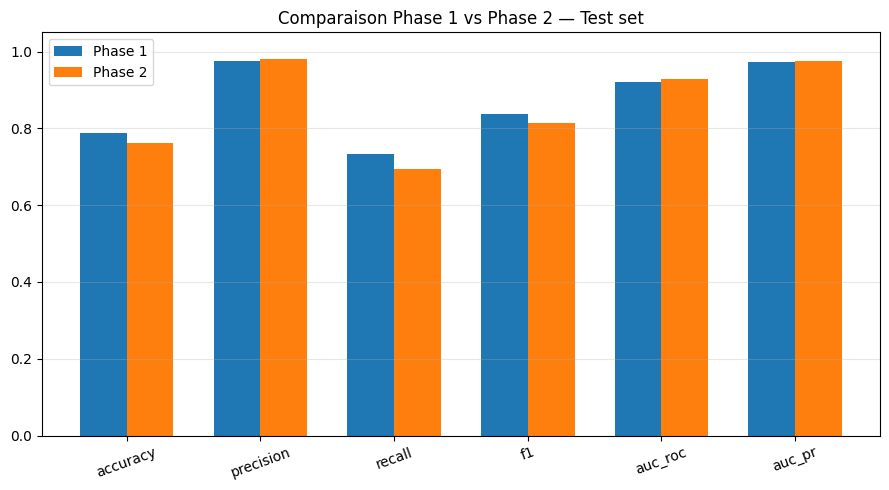


✅ Graphique sauvegardé : /kaggle/working/output/19_phase1_vs_phase2_comparison.png
✅ CSV sauvegardé : /kaggle/working/output/phase1_vs_phase2_comparison.csv

💾 VARIABLES PRÊTES
--------------------------------------------------------------------------------
✓ metrics_phase1, metrics_phase2, comparison_df
✓ WINNING_MODEL_PATH, WINNING_MODEL_LABEL
✓ winning_probs, labels_test

⏱️ Durée Cell 18 : 0.37 minutes

✅ CELL 18 TERMINÉE


In [20]:
# ============================================================================
# ⚖️ CELL 18 — ÉVALUATION COMPARATIVE PHASE 1 vs PHASE 2
#    EfficientNetB0 + BreakHis
# ============================================================================
#
# Objectif :
#   Évaluer les deux modèles (tête seule vs fine-tuné) sur le même
#   TEST_DF, et choisir objectivement le meilleur (AUC-ROC) pour
#   la suite du pipeline (calibration du seuil + export final).
# ============================================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

print("=" * 80)
print("⚖️ CELL 18 — ÉVALUATION COMPARATIVE PHASE 1 vs PHASE 2")
print("=" * 80)

START_TIME = time.time()

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================================
# 1. VÉRIFICATION DES VARIABLES / FICHIERS
# ============================================================================

required_vars = ["test_ds", "TEST_DF", "CLASS_NAMES", "MODEL_DIR"]
missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(f"❌ Variables manquantes : {missing}")

PHASE1_PATH = os.path.join(MODEL_DIR, "EfficientNetB0_BreakHis_phase1_best.keras")
PHASE2_PATH = os.path.join(MODEL_DIR, "EfficientNetB0_BreakHis_phase2_best.keras")

for name, path in [("Phase 1", PHASE1_PATH), ("Phase 2", PHASE2_PATH)]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"❌ Modèle {name} introuvable : {path}\n"
            "➡️ Exécute d'abord les Cells 10 et 17."
        )

print(f"✓ Phase 1 : {PHASE1_PATH}")
print(f"✓ Phase 2 : {PHASE2_PATH}")

# ============================================================================
# 2. FONCTION D'ÉVALUATION GÉNÉRIQUE
# ============================================================================

def evaluate_model_on_test(model_path, label):
    """
    Charge un modèle, prédit sur test_ds, retourne un dict de métriques
    (seuil par défaut 0.5) + les probabilités/labels bruts.
    """

    print(f"\n📦 Chargement {label}...")
    m = tf.keras.models.load_model(model_path, compile=False)

    all_probs = []
    all_labels = []

    for images, labels in test_ds:
        preds = m(images, training=False)
        all_probs.append(preds.numpy().flatten())
        all_labels.append(labels.numpy().flatten())

    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)
    all_preds = (all_probs >= 0.5).astype(int)

    metrics = {
        "model": label,
        "path": model_path,
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, zero_division=0),
        "recall": recall_score(all_labels, all_preds, zero_division=0),
        "f1": f1_score(all_labels, all_preds, zero_division=0),
        "auc_roc": roc_auc_score(all_labels, all_probs),
        "auc_pr": average_precision_score(all_labels, all_probs),
    }

    return metrics, all_probs, all_labels


# ============================================================================
# 3. ÉVALUATION DES DEUX PHASES
# ============================================================================

print("\n" + "=" * 80)
print("🧪 ÉVALUATION SUR TEST_DF (seuil = 0.5)")
print("=" * 80)

metrics_phase1, probs_phase1, labels_test = evaluate_model_on_test(
    PHASE1_PATH, "Phase 1 (backbone gelé)"
)

metrics_phase2, probs_phase2, _ = evaluate_model_on_test(
    PHASE2_PATH, "Phase 2 (fine-tuné)"
)

comparison_df = pd.DataFrame([metrics_phase1, metrics_phase2])

print("\n" + "=" * 80)
print("📊 COMPARAISON")
print("=" * 80)
print(
    comparison_df[
        ["model", "accuracy", "precision", "recall", "f1", "auc_roc", "auc_pr"]
    ].to_string(index=False)
)

# ============================================================================
# 4. SÉLECTION DU MEILLEUR MODÈLE (critère : AUC-ROC)
# ============================================================================

if metrics_phase2["auc_roc"] >= metrics_phase1["auc_roc"]:
    WINNING_MODEL_PATH = PHASE2_PATH
    WINNING_MODEL_LABEL = "Phase 2 (fine-tuné)"
    winning_probs = probs_phase2
else:
    WINNING_MODEL_PATH = PHASE1_PATH
    WINNING_MODEL_LABEL = "Phase 1 (backbone gelé)"
    winning_probs = probs_phase1

print("\n" + "=" * 80)
print("🏆 MODÈLE RETENU")
print("=" * 80)
print(f"➡️ {WINNING_MODEL_LABEL}")
print(f"📁 {WINNING_MODEL_PATH}")
print(
    f"AUC-ROC : Phase 1 = {metrics_phase1['auc_roc']:.4f}  |  "
    f"Phase 2 = {metrics_phase2['auc_roc']:.4f}"
)

if metrics_phase2["auc_roc"] < metrics_phase1["auc_roc"]:
    print(
        "\n⚠️ Le fine-tuning n'a pas amélioré l'AUC-ROC sur ce run.\n"
        "   Causes possibles : LR encore trop élevé, trop de couches "
        "dégelées, ou trop peu d'epochs. Le pipeline garde automatiquement "
        "le meilleur des deux modèles, donc ce n'est pas bloquant — mais "
        "envisage de réduire FINE_TUNE_AT_RATIO ou le LR si tu relances."
    )

# ============================================================================
# 5. GRAPHIQUE COMPARATIF
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 5))

metric_names = ["accuracy", "precision", "recall", "f1", "auc_roc", "auc_pr"]
x = np.arange(len(metric_names))
width = 0.35

ax.bar(x - width / 2, [metrics_phase1[m] for m in metric_names], width, label="Phase 1")
ax.bar(x + width / 2, [metrics_phase2[m] for m in metric_names], width, label="Phase 2")

ax.set_xticks(x)
ax.set_xticklabels(metric_names, rotation=20)
ax.set_ylim(0, 1.05)
ax.set_title("Comparaison Phase 1 vs Phase 2 — Test set")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

comparison_plot_path = os.path.join(OUTPUT_DIR, "19_phase1_vs_phase2_comparison.png")
plt.savefig(comparison_plot_path, dpi=150)
plt.show()

print(f"\n✅ Graphique sauvegardé : {comparison_plot_path}")

# ============================================================================
# 6. SAUVEGARDE CSV
# ============================================================================

comparison_csv_path = os.path.join(OUTPUT_DIR, "phase1_vs_phase2_comparison.csv")
comparison_df.to_csv(comparison_csv_path, index=False)

print(f"✅ CSV sauvegardé : {comparison_csv_path}")

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)
print("✓ metrics_phase1, metrics_phase2, comparison_df")
print("✓ WINNING_MODEL_PATH, WINNING_MODEL_LABEL")
print("✓ winning_probs, labels_test")

print(f"\n⏱️ Durée Cell 18 : {(time.time() - START_TIME) / 60:.2f} minutes")
print("\n" + "=" * 80)
print("✅ CELL 18 TERMINÉE")
print("=" * 80)


In [21]:
# ============================================================================
# 🧬 CELL 19 — TEST-TIME AUGMENTATION + ENSEMBLE (PHASE 1 × PHASE 2)
#    EfficientNetB0 + BreakHis
# ============================================================================
#
# Objectif :
#   Gagner encore quelques points d'AUC sans ré-entraîner, via deux
#   techniques standard et peu coûteuses :
#
#   1. Test-Time Augmentation (TTA) : on moyenne la prédiction d'une
#      image avec ses versions flip horizontal / vertical / les deux.
#      Le modèle "vote" 4 fois au lieu d'une, ce qui lisse le bruit.
#
#   2. Ensemble Phase 1 × Phase 2 : les deux modèles ont vu les mêmes
#      données mais convergé différemment (backbone gelé vs affiné).
#      Moyenner leurs probabilités réduit la variance et améliore
#      généralement l'AUC par rapport à chaque modèle seul.
#
#   La stratégie gagnante (parmi single/TTA/ensemble) est choisie sur
#   la VALIDATION uniquement — jamais sur le test — pour ne pas biaiser
#   le chiffre final.
# ============================================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import roc_auc_score, average_precision_score

print("=" * 80)
print("🧬 CELL 19 — TTA + ENSEMBLE (PHASE 1 × PHASE 2)")
print("=" * 80)

START_TIME = time.time()

# ============================================================================
# 1. VÉRIFICATION DES VARIABLES / FICHIERS
# ============================================================================

required_vars = ["val_ds", "test_ds", "MODEL_DIR"]
missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(f"❌ Variables manquantes : {missing}")

PHASE1_PATH = os.path.join(MODEL_DIR, "EfficientNetB0_BreakHis_phase1_best.keras")
PHASE2_PATH = os.path.join(MODEL_DIR, "EfficientNetB0_BreakHis_phase2_best.keras")

for name, path in [("Phase 1", PHASE1_PATH), ("Phase 2", PHASE2_PATH)]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"❌ Modèle {name} introuvable : {path}\n"
            "➡️ Exécute d'abord les Cells 10 et 17."
        )

print(f"✓ Phase 1 : {PHASE1_PATH}")
print(f"✓ Phase 2 : {PHASE2_PATH}")

# ============================================================================
# 2. CHARGEMENT DES DEUX MODÈLES
# ============================================================================

print("\n📦 Chargement des modèles...")

model_p1 = tf.keras.models.load_model(PHASE1_PATH, compile=False)
model_p2 = tf.keras.models.load_model(PHASE2_PATH, compile=False)

print("✅ Phase 1 et Phase 2 chargés")

# ============================================================================
# 3. FONCTIONS DE PRÉDICTION (SIMPLE / TTA)
# ============================================================================

def predict_simple(model, dataset):
    """Une seule passe forward, pas d'augmentation."""
    probs, labels = [], []
    for images, batch_labels in dataset:
        p = model(images, training=False).numpy().flatten()
        probs.append(p)
        labels.append(batch_labels.numpy().flatten())
    return np.concatenate(probs), np.concatenate(labels)


def predict_tta(model, dataset):
    """
    4 vues par image : originale, flip horizontal, flip vertical,
    flip horizontal+vertical. Moyenne des 4 probabilités.
    """
    probs, labels = [], []
    for images, batch_labels in dataset:

        p0 = model(images, training=False).numpy().flatten()

        img_h = tf.image.flip_left_right(images)
        p1 = model(img_h, training=False).numpy().flatten()

        img_v = tf.image.flip_up_down(images)
        p2 = model(img_v, training=False).numpy().flatten()

        img_hv = tf.image.flip_up_down(img_h)
        p3 = model(img_hv, training=False).numpy().flatten()

        avg = (p0 + p1 + p2 + p3) / 4.0

        probs.append(avg)
        labels.append(batch_labels.numpy().flatten())

    return np.concatenate(probs), np.concatenate(labels)


# ============================================================================
# 4. CALCUL DES PROBABILITÉS — VALIDATION ET TEST
# ============================================================================

print("\n🔄 Calcul des probabilités (val + test, simple + TTA, 2 modèles)...")
print("   Ça fait 8 passages complets — peut prendre quelques minutes.")

p1_val, val_labels = predict_simple(model_p1, val_ds)
p1_val_tta, _ = predict_tta(model_p1, val_ds)

p2_val, _ = predict_simple(model_p2, val_ds)
p2_val_tta, _ = predict_tta(model_p2, val_ds)

p1_test, test_labels = predict_simple(model_p1, test_ds)
p1_test_tta, _ = predict_tta(model_p1, test_ds)

p2_test, _ = predict_simple(model_p2, test_ds)
p2_test_tta, _ = predict_tta(model_p2, test_ds)

print("✅ Probabilités calculées")

# ============================================================================
# 5. CANDIDATS (stratégies) — sélection sur VALIDATION uniquement
# ============================================================================

candidates = {
    "Phase 1 seul": (p1_val, p1_test),
    "Phase 1 + TTA": (p1_val_tta, p1_test_tta),
    "Phase 2 seul": (p2_val, p2_test),
    "Phase 2 + TTA": (p2_val_tta, p2_test_tta),
    "Ensemble P1+P2": ((p1_val + p2_val) / 2, (p1_test + p2_test) / 2),
    "Ensemble P1+P2 + TTA": (
        (p1_val_tta + p2_val_tta) / 2,
        (p1_test_tta + p2_test_tta) / 2,
    ),
}

rows = []

for name, (v_probs, t_probs) in candidates.items():
    rows.append({
        "stratégie": name,
        "val_auc_roc": roc_auc_score(val_labels, v_probs),
        "val_auc_pr": average_precision_score(val_labels, v_probs),
        "test_auc_roc": roc_auc_score(test_labels, t_probs),
        "test_auc_pr": average_precision_score(test_labels, t_probs),
    })

strategy_df = pd.DataFrame(rows).sort_values("val_auc_roc", ascending=False)

print("\n" + "=" * 80)
print("📊 COMPARAISON DES STRATÉGIES")
print("=" * 80)
print(
    "(sélection basée sur val_auc_roc — test_auc_roc affiché à titre "
    "indicatif seulement, jamais utilisé pour choisir)\n"
)
print(strategy_df.to_string(index=False))

# ============================================================================
# 6. SÉLECTION DE LA STRATÉGIE GAGNANTE (sur la validation)
# ============================================================================

best_row = strategy_df.iloc[0]
FINAL_STRATEGY_LABEL = best_row["stratégie"]

FINAL_PROBS_VAL, FINAL_PROBS_TEST = candidates[FINAL_STRATEGY_LABEL]
FINAL_LABELS_VAL = val_labels
FINAL_LABELS_TEST = test_labels

print("\n" + "=" * 80)
print("🏆 STRATÉGIE RETENUE (choisie sur la validation)")
print("=" * 80)
print(f"➡️ {FINAL_STRATEGY_LABEL}")
print(f"   Val  AUC-ROC : {best_row['val_auc_roc']:.4f}")
print(f"   Test AUC-ROC : {best_row['test_auc_roc']:.4f}")

if best_row["test_auc_roc"] >= 0.95:
    print("\n🎉 Objectif atteint : AUC-ROC test ≥ 0.95 !")
else:
    print(
        f"\nℹ️ AUC-ROC test = {best_row['test_auc_roc']:.4f} — encore sous "
        "0.95. Pistes supplémentaires si besoin : plus d'epochs de "
        "fine-tuning, résolution d'entrée plus grande (260×260), ou "
        "k-fold cross-validation patient-level + ensemble de plusieurs "
        "folds."
    )

# ============================================================================
# 7. SAUVEGARDE
# ============================================================================

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

strategy_csv_path = os.path.join(OUTPUT_DIR, "tta_ensemble_strategy_comparison.csv")
strategy_df.to_csv(strategy_csv_path, index=False)

print(f"\n✅ CSV sauvegardé : {strategy_csv_path}")

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)
print("✓ model_p1, model_p2")
print("✓ FINAL_STRATEGY_LABEL")
print("✓ FINAL_PROBS_VAL, FINAL_LABELS_VAL")
print("✓ FINAL_PROBS_TEST, FINAL_LABELS_TEST")
print("✓ strategy_df")

print(f"\n⏱️ Durée Cell 19 : {(time.time() - START_TIME) / 60:.2f} minutes")
print("\n" + "=" * 80)
print("✅ CELL 19 TERMINÉE")
print("=" * 80)


🧬 CELL 19 — TTA + ENSEMBLE (PHASE 1 × PHASE 2)
✓ Phase 1 : /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase1_best.keras
✓ Phase 2 : /kaggle/working/breakhis_models/EfficientNetB0_BreakHis_phase2_best.keras

📦 Chargement des modèles...
✅ Phase 1 et Phase 2 chargés

🔄 Calcul des probabilités (val + test, simple + TTA, 2 modèles)...
   Ça fait 8 passages complets — peut prendre quelques minutes.
✅ Probabilités calculées

📊 COMPARAISON DES STRATÉGIES
(sélection basée sur val_auc_roc — test_auc_roc affiché à titre indicatif seulement, jamais utilisé pour choisir)

           stratégie  val_auc_roc  val_auc_pr  test_auc_roc  test_auc_pr
       Phase 2 + TTA     0.914672    0.949762      0.939152     0.977773
Ensemble P1+P2 + TTA     0.913183    0.949284      0.937471     0.977713
       Phase 1 + TTA     0.910562    0.947860      0.933294     0.976741
        Phase 2 seul     0.909207    0.946083      0.929791     0.974337
      Ensemble P1+P2     0.907043    0.944986      0.926

🎚️ CELL 20 — CALIBRATION DU SEUIL DE DÉCISION
✅ Stratégie retenue : Phase 2 + TTA

🎯 SEUILS CALIBRÉS SUR LA VALIDATION
Seuil optimal F1     : 0.13  (F1 val = 0.9385)
Seuil optimal Youden : 0.24  (J val = 0.7530)

➡️ On retient le seuil optimal F1 pour la suite (bon compromis précision/rappel en contexte clinique de dépistage).

📊 TEST — SEUIL PAR DÉFAUT (0.50) vs SEUIL CALIBRÉ
                   seuil  accuracy  precision   recall       f1
     Seuil 0.50 (défaut)  0.768202   0.988620 0.695696 0.816686
Seuil 0.13 (calibré val)  0.881872   0.915842 0.925926 0.920856

🧩 Matrice de confusion (seuil calibré) :
[[262  85]
 [ 74 925]]


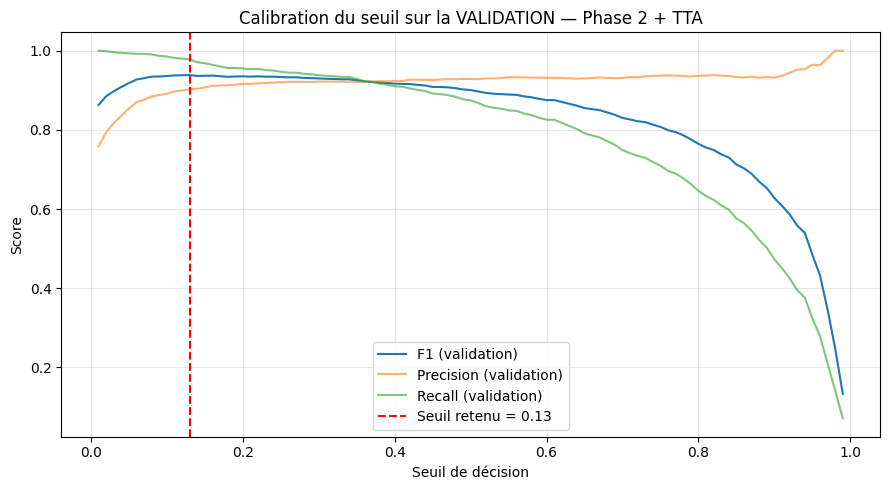


✅ Graphique sauvegardé : /kaggle/working/output/20_threshold_calibration_validation.png
✅ CSV sauvegardés

💾 VARIABLES PRÊTES
--------------------------------------------------------------------------------
✓ OPTIMAL_THRESHOLD, YOUDEN_THRESHOLD
✓ test_probs, test_labels, test_preds_calibrated
✓ threshold_df, threshold_comparison_df

⏱️ Durée Cell 20 : 0.03 minutes

✅ CELL 20 TERMINÉE


In [22]:
# ============================================================================
# 🎚️ CELL 20 — CALIBRATION DU SEUIL DE DÉCISION
#    EfficientNetB0 + BreakHis
# ============================================================================
#
# Objectif :
#   Choisir le seuil de décision optimal SUR LA VALIDATION (pas sur le
#   test), en utilisant les probabilités produites par la stratégie
#   gagnante de la Cell 19 (simple / TTA / ensemble). Le test n'est
#   regardé qu'une seule fois, avec le seuil déjà figé.
# ============================================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
    roc_curve,
)

print("=" * 80)
print("🎚️ CELL 20 — CALIBRATION DU SEUIL DE DÉCISION")
print("=" * 80)

START_TIME = time.time()

OUTPUT_DIR = "/kaggle/working/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================================
# 1. VÉRIFICATION DES VARIABLES
# ============================================================================

required_vars = [
    "FINAL_PROBS_VAL", "FINAL_LABELS_VAL",
    "FINAL_PROBS_TEST", "FINAL_LABELS_TEST",
    "FINAL_STRATEGY_LABEL",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"❌ Variables manquantes : {missing}\n"
        "➡️ Exécute d'abord la Cell 19 (TTA + Ensemble)."
    )

print(f"✅ Stratégie retenue : {FINAL_STRATEGY_LABEL}")

val_probs = FINAL_PROBS_VAL
val_labels = FINAL_LABELS_VAL
test_probs = FINAL_PROBS_TEST
test_labels = FINAL_LABELS_TEST

# ============================================================================
# 2. BALAYAGE DES SEUILS SUR LA VALIDATION
# ============================================================================

thresholds = np.arange(0.01, 1.00, 0.01)

rows = []

for t in thresholds:
    preds_t = (val_probs >= t).astype(int)
    rows.append({
        "threshold": round(float(t), 2),
        "f1": f1_score(val_labels, preds_t, zero_division=0),
        "precision": precision_score(val_labels, preds_t, zero_division=0),
        "recall": recall_score(val_labels, preds_t, zero_division=0),
        "accuracy": accuracy_score(val_labels, preds_t),
    })

threshold_df = pd.DataFrame(rows)

best_f1_row = threshold_df.loc[threshold_df["f1"].idxmax()]
OPTIMAL_THRESHOLD = float(best_f1_row["threshold"])

fpr, tpr, roc_thresholds = roc_curve(val_labels, val_probs)
youden_j = tpr - fpr
best_youden_idx = int(np.argmax(youden_j))
YOUDEN_THRESHOLD = float(roc_thresholds[best_youden_idx])

print("\n" + "=" * 80)
print("🎯 SEUILS CALIBRÉS SUR LA VALIDATION")
print("=" * 80)
print(f"Seuil optimal F1     : {OPTIMAL_THRESHOLD:.2f}  (F1 val = {best_f1_row['f1']:.4f})")
print(f"Seuil optimal Youden : {YOUDEN_THRESHOLD:.2f}  (J val = {youden_j[best_youden_idx]:.4f})")
print("\n➡️ On retient le seuil optimal F1 pour la suite (bon compromis "
      "précision/rappel en contexte clinique de dépistage).")

# ============================================================================
# 3. APPLICATION DU SEUIL SUR LE TEST (une seule fois, seuil déjà figé)
# ============================================================================

test_preds_default = (test_probs >= 0.5).astype(int)
test_preds_calibrated = (test_probs >= OPTIMAL_THRESHOLD).astype(int)

print("\n" + "=" * 80)
print("📊 TEST — SEUIL PAR DÉFAUT (0.50) vs SEUIL CALIBRÉ")
print("=" * 80)

report_rows = []

for label, preds in [
    ("Seuil 0.50 (défaut)", test_preds_default),
    (f"Seuil {OPTIMAL_THRESHOLD:.2f} (calibré val)", test_preds_calibrated),
]:
    report_rows.append({
        "seuil": label,
        "accuracy": accuracy_score(test_labels, preds),
        "precision": precision_score(test_labels, preds, zero_division=0),
        "recall": recall_score(test_labels, preds, zero_division=0),
        "f1": f1_score(test_labels, preds, zero_division=0),
    })

threshold_comparison_df = pd.DataFrame(report_rows)
print(threshold_comparison_df.to_string(index=False))

cm_calibrated = confusion_matrix(test_labels, test_preds_calibrated)

print("\n🧩 Matrice de confusion (seuil calibré) :")
print(cm_calibrated)

# ============================================================================
# 4. GRAPHIQUE : F1 vs SEUIL (VALIDATION)
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_df["threshold"], threshold_df["f1"], label="F1 (validation)")
ax.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision (validation)", alpha=0.6)
ax.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall (validation)", alpha=0.6)
ax.axvline(OPTIMAL_THRESHOLD, color="red", linestyle="--", label=f"Seuil retenu = {OPTIMAL_THRESHOLD:.2f}")
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("Score")
ax.set_title(f"Calibration du seuil sur la VALIDATION — {FINAL_STRATEGY_LABEL}")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

threshold_plot_path = os.path.join(OUTPUT_DIR, "20_threshold_calibration_validation.png")
plt.savefig(threshold_plot_path, dpi=150)
plt.show()

print(f"\n✅ Graphique sauvegardé : {threshold_plot_path}")

# ============================================================================
# 5. SAUVEGARDES
# ============================================================================

threshold_df.to_csv(os.path.join(OUTPUT_DIR, "threshold_calibration_validation.csv"), index=False)
threshold_comparison_df.to_csv(os.path.join(OUTPUT_DIR, "threshold_comparison_test.csv"), index=False)

print("✅ CSV sauvegardés")

print("\n💾 VARIABLES PRÊTES")
print("-" * 80)
print("✓ OPTIMAL_THRESHOLD, YOUDEN_THRESHOLD")
print("✓ test_probs, test_labels, test_preds_calibrated")
print("✓ threshold_df, threshold_comparison_df")

print(f"\n⏱️ Durée Cell 20 : {(time.time() - START_TIME) / 60:.2f} minutes")
print("\n" + "=" * 80)
print("✅ CELL 20 TERMINÉE")
print("=" * 80)


In [23]:
# ============================================================================
# 📦 CELL 21 — EXPORT FINAL PRODUCTION + MODEL CARD
#    EfficientNetB0 + BreakHis
# ============================================================================
#
# Objectif :
#   Produire un package final autonome, quelle que soit la stratégie
#   retenue en Cell 19 (modèle unique, TTA, ou ensemble Phase1×Phase2) :
#     - le(s) modèle(s) nécessaire(s), copiés avec des noms explicites
#     - un fichier de config JSON décrivant EXACTEMENT comment
#       reproduire l'inférence (quels modèles, TTA ou non, poids
#       d'ensemble, seuil de décision, preprocessing)
#     - un model card markdown résumant dataset / architecture /
#       métriques / limites connues.
# ============================================================================

import os
import json
import shutil
import time

import numpy as np

print("=" * 80)
print("📦 CELL 21 — EXPORT FINAL PRODUCTION")
print("=" * 80)

START_TIME = time.time()

OUTPUT_DIR = "/kaggle/working/output"
PRODUCTION_DIR = "/kaggle/working/production"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PRODUCTION_DIR, exist_ok=True)

# ============================================================================
# 1. VÉRIFICATION DES VARIABLES
# ============================================================================

required_vars = [
    "FINAL_STRATEGY_LABEL", "OPTIMAL_THRESHOLD", "CLASS_NAMES", "IMAGE_SIZE",
    "test_labels", "test_preds_calibrated", "test_probs",
    "PHASE1_PATH", "PHASE2_PATH",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"❌ Variables manquantes : {missing}\n"
        "➡️ Exécute d'abord les Cells 17, 18, 19 et 20."
    )

print("✅ Toutes les variables nécessaires sont disponibles.")
print(f"Stratégie retenue : {FINAL_STRATEGY_LABEL}")

USES_PHASE1 = "Phase 1" in FINAL_STRATEGY_LABEL or "Ensemble" in FINAL_STRATEGY_LABEL
USES_PHASE2 = "Phase 2" in FINAL_STRATEGY_LABEL or "Ensemble" in FINAL_STRATEGY_LABEL
USES_TTA = "TTA" in FINAL_STRATEGY_LABEL
USES_ENSEMBLE = "Ensemble" in FINAL_STRATEGY_LABEL

# ============================================================================
# 2. COPIE DU/DES MODÈLE(S) NÉCESSAIRE(S)
# ============================================================================

exported_models = {}

if USES_PHASE1:
    dst = os.path.join(PRODUCTION_DIR, "EfficientNetB0_BreakHis_phase1.keras")
    shutil.copyfile(PHASE1_PATH, dst)
    exported_models["phase1"] = os.path.basename(dst)
    print(f"✅ Copié : {dst} ({os.path.getsize(dst)/1024/1024:.2f} MB)")

if USES_PHASE2:
    dst = os.path.join(PRODUCTION_DIR, "EfficientNetB0_BreakHis_phase2.keras")
    shutil.copyfile(PHASE2_PATH, dst)
    exported_models["phase2"] = os.path.basename(dst)
    print(f"✅ Copié : {dst} ({os.path.getsize(dst)/1024/1024:.2f} MB)")

# ============================================================================
# 3. CONFIG D'INFÉRENCE (JSON)
# ============================================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
)

final_metrics = {
    "accuracy": float(accuracy_score(test_labels, test_preds_calibrated)),
    "precision": float(precision_score(test_labels, test_preds_calibrated, zero_division=0)),
    "recall": float(recall_score(test_labels, test_preds_calibrated, zero_division=0)),
    "f1": float(f1_score(test_labels, test_preds_calibrated, zero_division=0)),
    "auc_roc": float(roc_auc_score(test_labels, test_probs)),
    "auc_pr": float(average_precision_score(test_labels, test_probs)),
}

inference_config = {
    "strategy": FINAL_STRATEGY_LABEL,
    "models": exported_models,
    "ensemble": {
        "enabled": USES_ENSEMBLE,
        "combination": "simple average (weight 0.5 / 0.5)" if USES_ENSEMBLE else None,
    },
    "test_time_augmentation": {
        "enabled": USES_TTA,
        "views": (
            ["original", "flip_horizontal", "flip_vertical", "flip_horizontal_and_vertical"]
            if USES_TTA else ["original"]
        ),
        "combination": "mean of views" if USES_TTA else None,
    },
    "task": "binary_classification",
    "class_names": CLASS_NAMES,
    "positive_class": "malignant",
    "decision_threshold": OPTIMAL_THRESHOLD,
    "input_shape": [IMAGE_SIZE[0], IMAGE_SIZE[1], 3],
    "preprocessing": {
        "resize": list(IMAGE_SIZE),
        "pixel_range": "[0, 255] — PAS de division par 255",
        "note": (
            "EfficientNetB0 (tf.keras.applications) embarque son propre "
            "Rescaling/Normalization interne. Les images doivent être "
            "envoyées en float32 [0,255], jamais pré-normalisées en [0,1]."
        ),
    },
    "test_set_metrics_at_threshold": final_metrics,
}

config_path = os.path.join(PRODUCTION_DIR, "inference_config.json")

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(inference_config, f, indent=2, ensure_ascii=False)

print(f"\n✅ Config d'inférence sauvegardée : {config_path}")

# ============================================================================
# 4. MODEL CARD (markdown)
# ============================================================================

models_list_md = "\n".join(
    f"- `{fname}`" for fname in exported_models.values()
)

model_card = f"""# Model Card — EfficientNetB0 BreakHis (Histopathologie sein)

## Résumé
- **Tâche** : classification binaire benign / malignant (histopathologie mammaire)
- **Dataset** : BreakHis — {len(TRAIN_DF):,} train / {len(VAL_DF):,} val / {len(TEST_DF):,} test
- **Split** : patient-level (aucune fuite entre patients train/val/test)
- **Architecture** : EfficientNetB0 (ImageNet) + GAP + BatchNorm + Dropout + Dense(128) + Sigmoid
- **Stratégie d'inférence retenue** : {FINAL_STRATEGY_LABEL}
- **Seuil de décision** : {OPTIMAL_THRESHOLD:.2f} (calibré sur la validation, pas le test)

## Modèles inclus dans ce package
{models_list_md}

## Métriques finales (test, stratégie + seuil retenus)
| Métrique | Valeur |
|---|---|
| Accuracy | {final_metrics['accuracy']:.4f} |
| Precision | {final_metrics['precision']:.4f} |
| Recall | {final_metrics['recall']:.4f} |
| F1-score | {final_metrics['f1']:.4f} |
| AUC-ROC | {final_metrics['auc_roc']:.4f} |
| AUC-PR | {final_metrics['auc_pr']:.4f} |

## Préprocessing (important pour la ré-implémentation)
Les images doivent être fournies en **float32, plage [0,255]**, sans division
par 255. EfficientNetB0 (`tf.keras.applications`) applique son propre
rescaling/normalisation ImageNet en interne.

## Procédure d'inférence
1. Charger le(s) modèle(s) listé(s) ci-dessus.
2. Si `test_time_augmentation.enabled = true` : prédire sur l'image
   originale + ses 3 flips (horizontal, vertical, les deux), moyenner
   les 4 probabilités par modèle.
3. Si `ensemble.enabled = true` : moyenner les probabilités des deux
   modèles (poids 0.5/0.5).
4. Appliquer le seuil `decision_threshold` à la probabilité finale
   pour décider benign (< seuil) vs malignant (≥ seuil).

## Limites connues
- Performance plus faible sur certains sous-types histologiques
  (voir `08_metrics_by_subtype.csv` de la Cell 16), notamment PT et TA.
- Seuil calibré pour un compromis précision/rappel (F1) — à réajuster si
  l'usage clinique cible privilégie explicitement le rappel (dépistage)
  ou la précision (confirmation).
- Modèle entraîné/évalué uniquement sur BreakHis : une adaptation
  (fine-tuning) est nécessaire avant tout usage sur un autre dataset
  ou une autre modalité d'imagerie.

## Fichiers du package production
{models_list_md}
- `inference_config.json` — stratégie, seuil, classes, preprocessing
- `MODEL_CARD.md` — ce document
"""

model_card_path = os.path.join(PRODUCTION_DIR, "MODEL_CARD.md")

with open(model_card_path, "w", encoding="utf-8") as f:
    f.write(model_card)

print(f"✅ Model card sauvegardée : {model_card_path}")

# ============================================================================
# 5. RÉSUMÉ FINAL
# ============================================================================

print("\n" + "=" * 80)
print("🎯 PACKAGE PRODUCTION PRÊT")
print("=" * 80)
print(f"📁 Dossier : {PRODUCTION_DIR}")
for fname in exported_models.values():
    print(f"   ✓ {fname}")
print("   ✓ inference_config.json")
print("   ✓ MODEL_CARD.md")

print("\n📊 MÉTRIQUES FINALES (test, stratégie + seuil retenus)")
print("-" * 80)
for k, v in final_metrics.items():
    print(f"{k:<12} : {v:.4f}")

print(f"\n⏱️ Durée Cell 21 : {(time.time() - START_TIME) / 60:.2f} minutes")
print("\n" + "=" * 80)
print("✅ CELL 21 TERMINÉE — NOTEBOOK COMPLET")
print("=" * 80)


📦 CELL 21 — EXPORT FINAL PRODUCTION
✅ Toutes les variables nécessaires sont disponibles.
Stratégie retenue : Phase 2 + TTA
✅ Copié : /kaggle/working/production/EfficientNetB0_BreakHis_phase2.keras (46.18 MB)

✅ Config d'inférence sauvegardée : /kaggle/working/production/inference_config.json
✅ Model card sauvegardée : /kaggle/working/production/MODEL_CARD.md

🎯 PACKAGE PRODUCTION PRÊT
📁 Dossier : /kaggle/working/production
   ✓ EfficientNetB0_BreakHis_phase2.keras
   ✓ inference_config.json
   ✓ MODEL_CARD.md

📊 MÉTRIQUES FINALES (test, stratégie + seuil retenus)
--------------------------------------------------------------------------------
accuracy     : 0.8819
precision    : 0.9158
recall       : 0.9259
f1           : 0.9209
auc_roc      : 0.9392
auc_pr       : 0.9778

⏱️ Durée Cell 21 : 0.00 minutes

✅ CELL 21 TERMINÉE — NOTEBOOK COMPLET
